# Classifying Dry Bean Varieties with Logistic Regression and Support Vector Machines

**Project 7, logistic regression and SVMs**

## Introduction

This notebook studies how well **linear and kernel classifiers** can tell seven varieties of dry
bean apart from automated shape measurements, and uses that problem to compare **logistic
regression**, a **linear SVM**, a **polynomial-kernel SVM** and an **RBF-kernel SVM**.

### The dataset

The [Dry Bean dataset](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset) comes from the UCI
Machine Learning Repository. A grain company photographed 13,611 individual beans of seven
registered varieties with a high-resolution camera and passed each image through a segmentation
pipeline that produced **16 continuous geometric measurements** per bean: a handful of size
dimensions (area, perimeter, axis lengths) and a larger group of dimensionless shape descriptors
(eccentricity, solidity, roundness, compactness and four "shape factors").

The motivation is a real one. Seed varieties are normally sorted by hand, which is slow and
inconsistent between graders. If a classifier can recover the variety from a photograph, the
sorting can be automated.

### Why this dataset suits logistic regression and SVMs

| Requirement | How this dataset meets it |
|---|---|
| A categorical target | `Class`, the bean variety |
| At least two classes, but not too many | **7** classes: enough for multi-class strategy to matter, few enough to stay fast |
| Useful explanatory variables | **16 quantitative** features, so no categorical encoding is needed |
| Something interesting to find | The classes are **imbalanced (6.8:1)**, several features are **almost perfectly collinear**, and the classes are *nearly* but not quite linearly separable |

The seven classes also make the one-vs-rest versus one-vs-one question concrete: OVR fits 7 binary
models, while OVO fits 7 x 6 / 2 = **21**.

### Questions addressed

The brief asks for at least four of its listed questions. This notebook works through **all eight**:

| Section | Question |
|---|---|
| 4 | Which variables are predictive of the target variable? |
| 5 | Can logistic regression or a linear SVM predict well? |
| 6 | What do plots of selected pairs of variables look like, and where is the decision boundary? |
| 7 | How generalisable are the models, and how does the bias-variance trade-off affect the choice? |
| 8 | Is there a difference between the polynomial and RBF SVMs? |
| 9 | What effect does changing `class_weight` in an SVM have, and why might it matter here? |
| 10 | Is there a difference in runtime performance, and what does OVR versus OVO cost? |

Sections 1 to 3 cover setup, the data and exploratory analysis; Section 11 draws the conclusions.

### Summary of what was found

- All four classifiers land between about **91.6% and 92.6%** test accuracy, against a **26.2%**
  majority-class baseline. The problem is largely learnable by a linear model.
- The two kernel SVMs beat the two linear models by a small but **statistically significant**
  margin, while **RBF and polynomial are statistically indistinguishable from each other**.
- **One pair of varieties, DERMASON and SIRA, accounts for roughly 45% of every model's errors.**
  Next to that, nothing else about the problem is hard.
- About **five or six of the sixteen features** are enough to come within a point of the
  full-feature accuracy. `Extent` carries essentially no signal on its own.
- The kernel models pay for their accuracy with **far more parameters** and much slower
  prediction, which is the practical argument for preferring the linear model.

---
## 1. Setup

The notebook is **self-contained**: everything it needs is defined below and it runs top to bottom
with no other project files. Select the **`Python (project7)`** kernel.

Three decisions made here are applied consistently throughout, and each one matters for whether the
results mean anything:

- **One random seed (`RANDOM_STATE = 42`)** for the split, the cross-validation folds and every
  resample, so the whole notebook is reproducible.
- **One fixed stratified 75/25 train/test split.** The test set is touched *only* for final
  reporting; every hyper-parameter and every feature decision is made by cross-validation on the
  training set. Stratifying preserves the class proportions, which matters because the rarest
  variety is under 4% of the data.
- **Every model is a `Pipeline` whose first step is a `StandardScaler`.** This is not cosmetic.
  The features span five orders of magnitude (`Area` is around 53,000 while `ShapeFactor2` is
  around 0.0017), so without scaling `Area` would dominate both the regularisation penalty of
  logistic regression and the distance computation inside the RBF kernel. Keeping the scaler
  *inside* the pipeline means each fold's means and standard deviations are learnt from the
  training folds only, standardising the whole table up front would leak information from the
  validation fold into the fit.

In [1]:
import io
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
    validation_curve,
)
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

%matplotlib inline

# --- reproducibility -------------------------------------------------
RANDOM_STATE = 42
TEST_SIZE = 0.25
CV_FOLDS = 5
CV_REPEATS = 3
N_JOBS = -1

# --- the 16 measurements, in a fixed order so every table lines up ---
FEATURES = [
    "Area", "Perimeter", "MajorAxisLength", "MinorAxisLength", "AspectRation",
    "Eccentricity", "ConvexArea", "EquivDiameter", "Extent", "Solidity",
    "roundness", "Compactness", "ShapeFactor1", "ShapeFactor2", "ShapeFactor3",
    "ShapeFactor4",
]
TARGET = "Class"

# Features that scale with how physically large the bean is, versus the
# dimensionless ratios. The split is used when discussing collinearity.
SIZE_FEATURES = ["Area", "Perimeter", "MajorAxisLength", "MinorAxisLength",
                 "ConvexArea", "EquivDiameter"]
SHAPE_FEATURES = [f for f in FEATURES if f not in SIZE_FEATURES]

# Classes in descending frequency; fixing the order keeps every confusion
# matrix and bar chart directly comparable.
CLASS_ORDER = ["DERMASON", "SIRA", "SEKER", "HOROZ", "CALI", "BARBUNYA", "BOMBAY"]
MINORITY_CLASS = "BOMBAY"

# Okabe-Ito, a colour-blind-safe qualitative palette.
CLASS_COLORS = {
    "DERMASON": "#0072B2", "SIRA": "#E69F00", "SEKER": "#009E73",
    "HOROZ": "#CC79A7", "CALI": "#D55E00", "BARBUNYA": "#56B4E9",
    "BOMBAY": "#8C564B",
}
MODEL_COLORS = {
    "Logistic Regression": "#0072B2", "Linear SVM": "#E69F00",
    "Polynomial SVM": "#009E73", "RBF SVM": "#D55E00",
}

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.alpha": 0.3, "grid.linestyle": "--",
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

print("Setup complete.")

Setup complete.


---
## 2. The data

### 2.1 Loading

The raw data is a single Excel sheet inside a zip archive published by UCI. It is downloaded once
into `data/raw/` and cached as a CSV, so re-running the notebook needs no network access.

In [2]:
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
ZIP_PATH = DATA_DIR / "dry_bean_dataset.zip"
CSV_PATH = DATA_DIR / "dry_bean.csv"
URL = "https://archive.ics.uci.edu/static/public/602/dry+bean+dataset.zip"
MEMBER = "DryBeanDataset/Dry_Bean_Dataset.xlsx"


def load_raw() -> pd.DataFrame:
    """Return the dataset as published, downloading it only the first time."""
    if CSV_PATH.exists():
        return pd.read_csv(CSV_PATH)

    if not ZIP_PATH.exists():
        request = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(request, timeout=180) as response:
            ZIP_PATH.write_bytes(response.read())

    with zipfile.ZipFile(ZIP_PATH) as archive:
        with archive.open(MEMBER) as sheet:
            frame = pd.read_excel(io.BytesIO(sheet.read()), engine="openpyxl")

    frame.to_csv(CSV_PATH, index=False)
    return frame


raw = load_raw()
print(f"raw shape: {raw.shape}")
raw.head()

raw shape: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### 2.2 Cleaning

The published data is already tidy, so cleaning is deliberately minimal: there are no missing
values and no impossible measurements. The one change that matters is removing **exactly duplicated
rows**. That is not a cosmetic tidy-up, an identical row appearing in both the training and the
test set would leak the answer across the split and inflate the reported accuracy.

In [3]:
def load_clean() -> pd.DataFrame:
    """Drop duplicate rows and fix the column order and dtypes."""
    frame = load_raw().drop_duplicates().reset_index(drop=True)
    frame = frame[FEATURES + [TARGET]]
    frame[FEATURES] = frame[FEATURES].astype(float)
    frame[TARGET] = frame[TARGET].astype(str).str.strip()
    return frame


clean = load_clean()

quality = pd.DataFrame({
    "stage": ["raw", "after removing duplicates"],
    "rows": [len(raw), len(clean)],
    "columns": [raw.shape[1], clean.shape[1]],
    "missing_values": [int(raw.isna().sum().sum()), int(clean.isna().sum().sum())],
    "duplicate_rows": [int(raw.duplicated().sum()), int(clean.duplicated().sum())],
})
print(quality.to_string(index=False))
print(f"\nremoved {len(raw) - len(clean)} duplicated rows")

                    stage  rows  columns  missing_values  duplicate_rows
                      raw 13611       17               0              68
after removing duplicates 13543       17               0               0

removed 68 duplicated rows


### 2.3 The train/test split

One stratified 75/25 split is built here and reused by every later section, so numbers reported in
different sections are directly comparable. The table below confirms the stratification worked: the
class percentages agree across the full dataset, the training set and the test set.

In [4]:
X = clean[FEATURES].copy()
y = clean[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print(f"train: {X_train.shape}    test: {X_test.shape}")

balance = pd.DataFrame({
    "n_total": y.value_counts(),
    "pct_total": 100 * y.value_counts(normalize=True),
    "pct_train": 100 * y_train.value_counts(normalize=True),
    "pct_test": 100 * y_test.value_counts(normalize=True),
}).reindex(CLASS_ORDER).round(2)
balance

train: (10157, 16)    test: (3386, 16)


,n_total,pct_total,pct_train,pct_test
Class,,,,
DERMASON,3546,26.18,26.18,26.20
SIRA,2636,19.46,19.46,19.46
SEKER,2027,14.97,14.97,14.97
HOROZ,1860,13.73,13.73,13.73
CALI,1630,12.04,12.03,12.05
BARBUNYA,1322,9.76,9.77,9.75
BOMBAY,522,3.85,3.86,3.84


---
## 3. Exploratory analysis

Before fitting anything, four questions about the data need answering, because each one changes how
the models must be built and how their scores should be read:

1. **How imbalanced are the classes?** This sets the baseline any classifier has to beat and
   decides whether plain accuracy is an honest summary.
2. **What scale are the features on?** This decides whether standardising is optional or essential.
3. **How redundant are the features?** This decides whether individual coefficients can be
   interpreted.
4. **How close to linearly separable is the problem?** This is the first hint of whether a kernel
   will be worth its cost.

### 3.1 Class balance

The varieties are far from evenly represented. The ratio between the most and least common is
reported below, along with the **majority-class baseline**, the accuracy of a classifier that
always guesses DERMASON. That number is the floor: any model scoring near it has learnt nothing.

             n  percent
Class                  
DERMASON  3546    26.18
SIRA      2636    19.46
SEKER     2027    14.97
HOROZ     1860    13.73
CALI      1630    12.04
BARBUNYA  1322     9.76
BOMBAY     522     3.85

imbalance ratio (most / least common) : 6.79 : 1
majority-class baseline accuracy      : 0.2618
a classifier must beat 26.2% to be doing anything at all


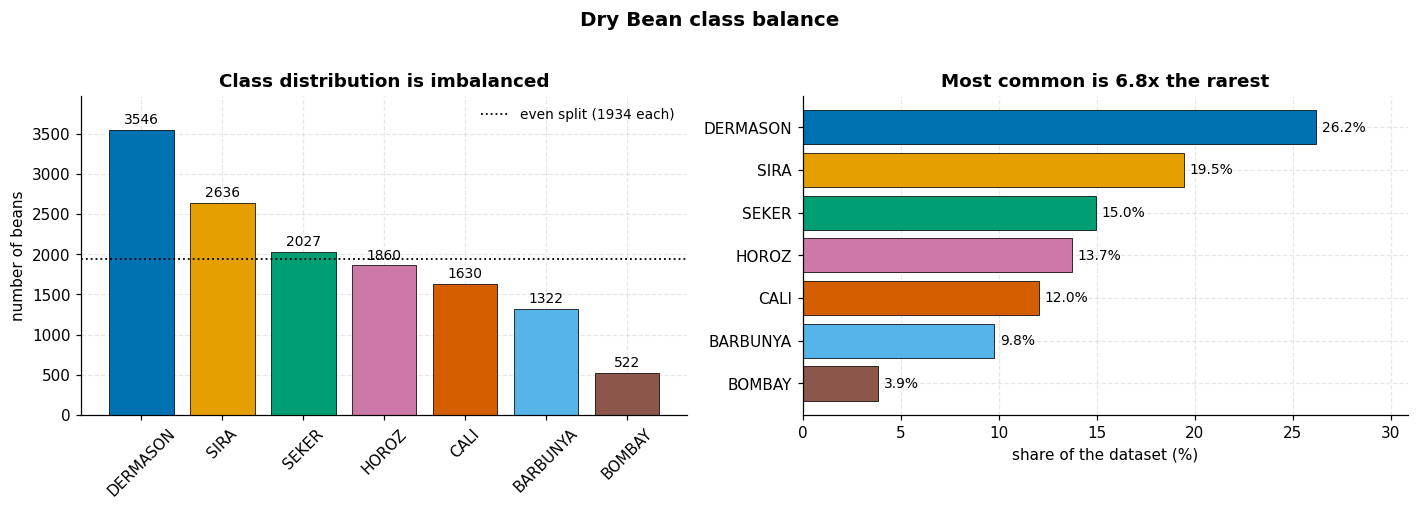

In [5]:
counts = y.value_counts().reindex(CLASS_ORDER)
distribution = pd.DataFrame({
    "n": counts,
    "percent": (100 * counts / len(y)).round(2),
})
imbalance_ratio = counts.max() / counts.min()
majority_baseline = counts.max() / len(y)

print(distribution.to_string())
print(f"\nimbalance ratio (most / least common) : {imbalance_ratio:.2f} : 1")
print(f"majority-class baseline accuracy      : {majority_baseline:.4f}")
print(f"a classifier must beat {majority_baseline:.1%} to be doing anything at all")

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13, 4.5))

bars = ax_left.bar(
    distribution.index, distribution["n"],
    color=[CLASS_COLORS[c] for c in distribution.index], edgecolor="black", linewidth=0.5,
)
ax_left.bar_label(bars, fmt="%d", padding=2, fontsize=9)
ax_left.set_ylabel("number of beans")
ax_left.set_title("Class distribution is imbalanced")
ax_left.tick_params(axis="x", rotation=45)
ax_left.set_ylim(0, distribution["n"].max() * 1.12)
ax_left.axhline(len(y) / len(CLASS_ORDER), color="black", linestyle=":", linewidth=1.2,
                label=f"even split ({len(y) // len(CLASS_ORDER)} each)")
ax_left.legend(fontsize=9)

# A horizontal view of the same thing makes the 6.8:1 spread easier to read.
ax_right.barh(
    distribution.index[::-1], distribution["percent"][::-1],
    color=[CLASS_COLORS[c] for c in distribution.index[::-1]],
    edgecolor="black", linewidth=0.5,
)
ax_right.set_xlabel("share of the dataset (%)")
ax_right.set_title(f"Most common is {imbalance_ratio:.1f}x the rarest")
for i, (cls, pct) in enumerate(zip(distribution.index[::-1], distribution["percent"][::-1])):
    ax_right.text(pct + 0.3, i, f"{pct:.1f}%", va="center", fontsize=9)
ax_right.set_xlim(0, distribution["percent"].max() * 1.18)

fig.suptitle("Dry Bean class balance", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

The imbalance is moderate rather than extreme, but it is real: BOMBAY is under 4% of the data while
DERMASON is over 26%. Two consequences follow and are used throughout the notebook:

- **Accuracy alone is not enough.** A model can score well by serving the big classes and
  neglecting BOMBAY. Every comparison below therefore reports **balanced accuracy** (the mean of
  the per-class recalls) and **macro F1** alongside accuracy, because those weight every class
  equally regardless of size.
- **Every split and fold is stratified**, so the rare class is represented in the same proportion
  everywhere.

### 3.2 Feature scales, why standardising is mandatory

The 16 measurements are recorded in completely different units: `Area` is a pixel count in the tens
of thousands, while the shape factors are ratios below 1. The figure below plots each feature's
range on a log axis.

,mean,std,min,median,max,skew
Area,53048.4604,29392.4383,20420.0000,44580.0000,254616.0000,2.9471
Perimeter,854.9934,214.7227,524.7360,793.8960,1985.3700,1.6280
MajorAxisLength,319.8956,85.8093,183.6012,296.4046,738.8602,1.3658
MinorAxisLength,202.3653,45.0516,122.5127,192.4911,460.1985,2.2320
AspectRation,1.5811,0.2452,1.0249,1.5499,2.4303,0.5890
Eccentricity,0.7503,0.0919,0.2190,0.7640,0.9114,-1.0649
ConvexArea,53767.9867,29844.2485,20684.0000,45122.0000,263261.0000,2.9361
EquivDiameter,253.0341,59.3077,161.2438,238.2457,569.3744,1.9473
Extent,0.7498,0.0489,0.5553,0.7599,0.8662,-0.8957
Solidity,0.9872,0.0047,0.9192,0.9883,0.9947,-2.5469


largest mean / smallest mean = 31274470 x


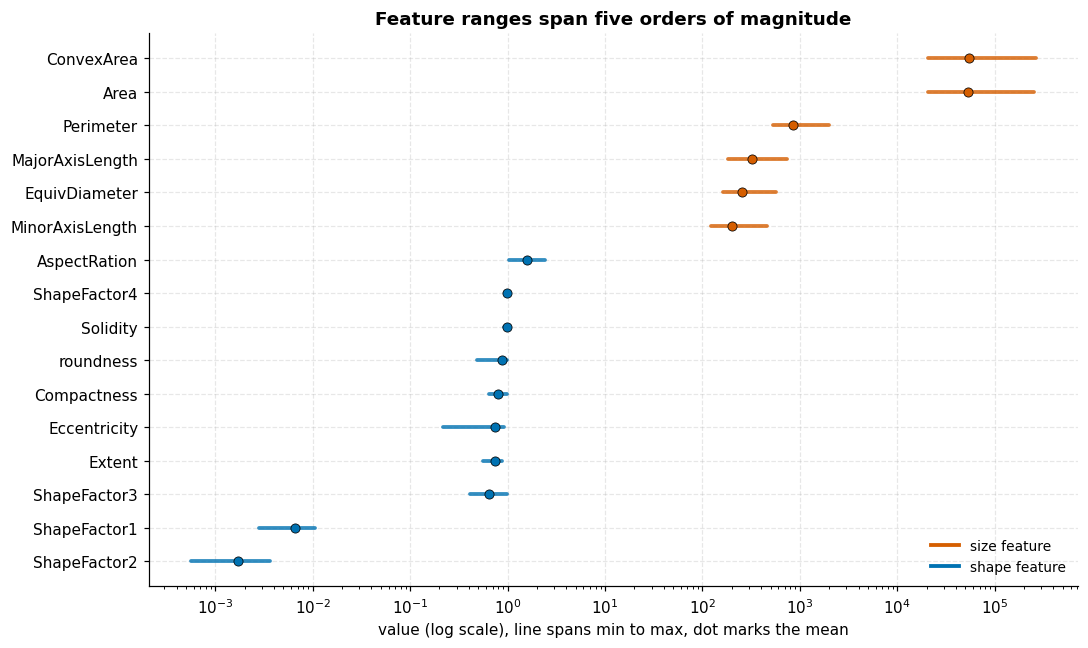

In [6]:
summary = pd.DataFrame({
    "mean": X.mean(), "std": X.std(), "min": X.min(),
    "median": X.median(), "max": X.max(), "skew": X.skew(),
}).loc[FEATURES]
display(summary.round(4))

spread = (summary["max"] / summary["min"]).sort_values()
print(f"largest mean / smallest mean = {summary['mean'].max() / summary['mean'].min():.0f} x")

fig, ax = plt.subplots(figsize=(10, 6))
order = summary["mean"].sort_values().index
for i, feature in enumerate(order):
    low, high, mean = summary.loc[feature, ["min", "max", "mean"]]
    colour = "#D55E00" if feature in SIZE_FEATURES else "#0072B2"
    ax.plot([low, high], [i, i], color=colour, linewidth=2.5, solid_capstyle="round", alpha=0.8)
    ax.plot(mean, i, "o", color=colour, markersize=6, markeredgecolor="black", markeredgewidth=0.5)

ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xscale("log")
ax.set_xlabel("value (log scale), line spans min to max, dot marks the mean")
ax.set_title("Feature ranges span five orders of magnitude")
handles = [
    plt.Line2D([], [], color="#D55E00", linewidth=2.5, label="size feature"),
    plt.Line2D([], [], color="#0072B2", linewidth=2.5, label="shape feature"),
]
ax.legend(handles=handles, loc="lower right", fontsize=9)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

This is the empirical justification for the `StandardScaler` in every pipeline. An unscaled
Euclidean distance between two beans is essentially the difference in their `Area`, because that
term is thousands of times larger than any shape factor, so an RBF kernel would see only size and
ignore shape entirely. Likewise, the L2 penalty in logistic regression shrinks coefficients toward
zero in proportion to their size, which penalises features measured in small units far more harshly
than features measured in large ones.

### 3.3 Feature redundancy

Several of these measurements are near-duplicates by construction. `Area` and `ConvexArea` differ
only by any concavities in the bean outline, and `EquivDiameter` is a deterministic function of
`Area`. The heatmap below shows the correlation structure, and the table lists every pair above
|r| = 0.95.

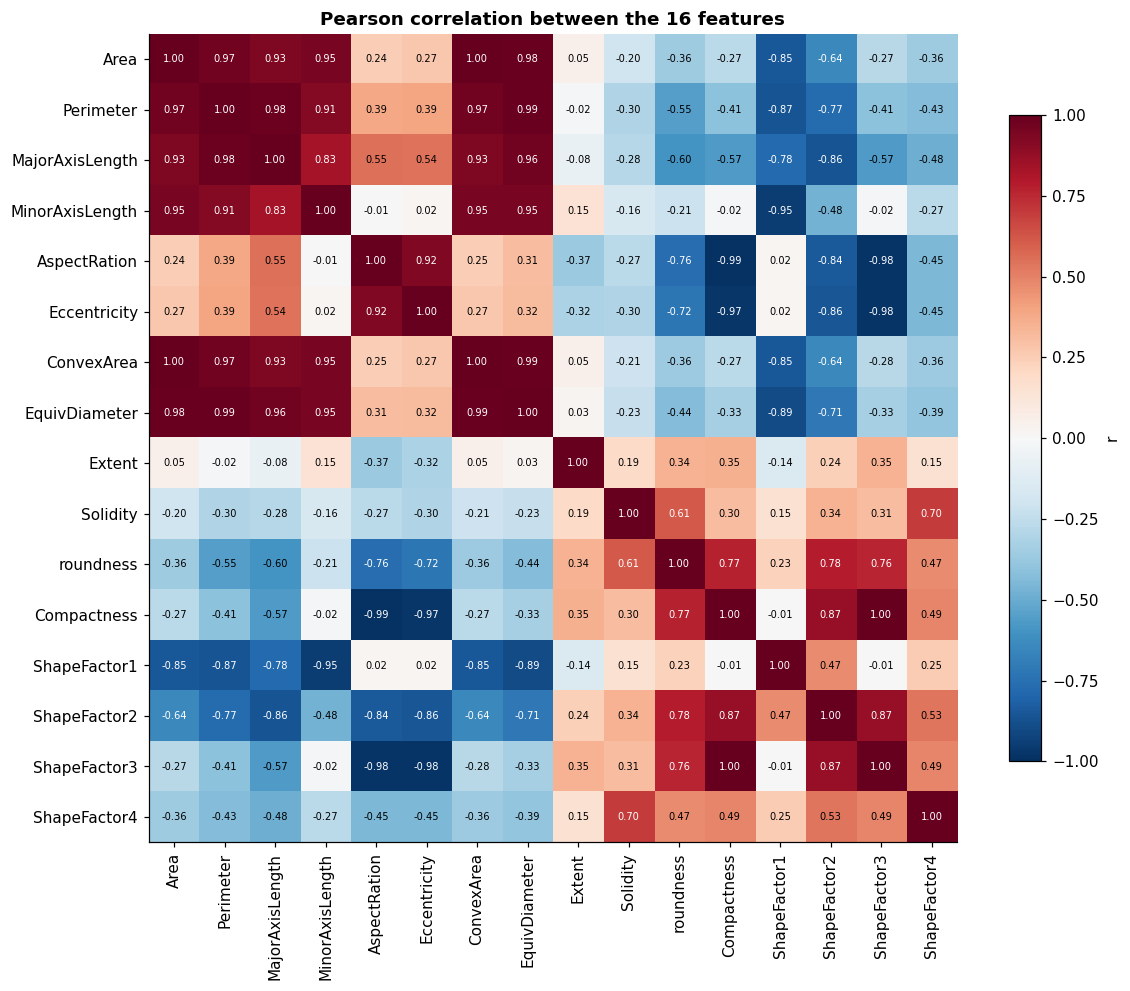

15 feature pairs exceed |r| = 0.95:



,feature_1,feature_2,r,group
0,Area,ConvexArea,0.9999,size-size
1,Compactness,ShapeFactor3,0.9987,shape-shape
2,Perimeter,EquivDiameter,0.9915,size-size
3,AspectRation,Compactness,-0.9876,shape-shape
4,ConvexArea,EquivDiameter,0.9853,size-size
5,Area,EquivDiameter,0.9850,size-size
6,Eccentricity,ShapeFactor3,-0.9811,shape-shape
7,AspectRation,ShapeFactor3,-0.9785,shape-shape
8,Perimeter,MajorAxisLength,0.9776,size-size
9,Eccentricity,Compactness,-0.9703,shape-shape


In [7]:
correlation = X.corr()

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(FEATURES, rotation=90)
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(FEATURES)

# Annotate every cell; white text on the dark extremes stays readable.
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(value) > 0.6 else "black")

ax.set_title("Pearson correlation between the 16 features")
fig.colorbar(image, ax=ax, shrink=0.8, label="r")
ax.grid(False)
fig.tight_layout()
plt.show()

# List the strongly correlated pairs from the upper triangle only.
pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        r = correlation.loc[a, b]
        if abs(r) > 0.95:
            group = "size-size" if a in SIZE_FEATURES and b in SIZE_FEATURES else (
                "shape-shape" if a in SHAPE_FEATURES and b in SHAPE_FEATURES else "mixed")
            pairs.append({"feature_1": a, "feature_2": b, "r": round(r, 4), "group": group})

high_correlation = pd.DataFrame(pairs).sort_values("r", key=abs, ascending=False).reset_index(drop=True)
print(f"{len(high_correlation)} feature pairs exceed |r| = 0.95:\n")
display(high_correlation)

This matters for interpretation rather than for accuracy. When two features carry almost the same
information, the fitted model can distribute weight between them almost arbitrarily, a large
positive coefficient on `Area` and a large negative one on `ConvexArea` can produce nearly the same
predictions as the reverse. The consequence is that **individual logistic-regression coefficients
cannot be read individually** as "this feature matters this much". Section 4.3 looks at what the
fit actually does with two interchangeable features, and uses permutation importance as a
cross-check.

### 3.4 Which features separate the classes?

The panels below show how each of six features is distributed within each variety. A feature is
useful exactly when its per-class curves sit apart from each other.

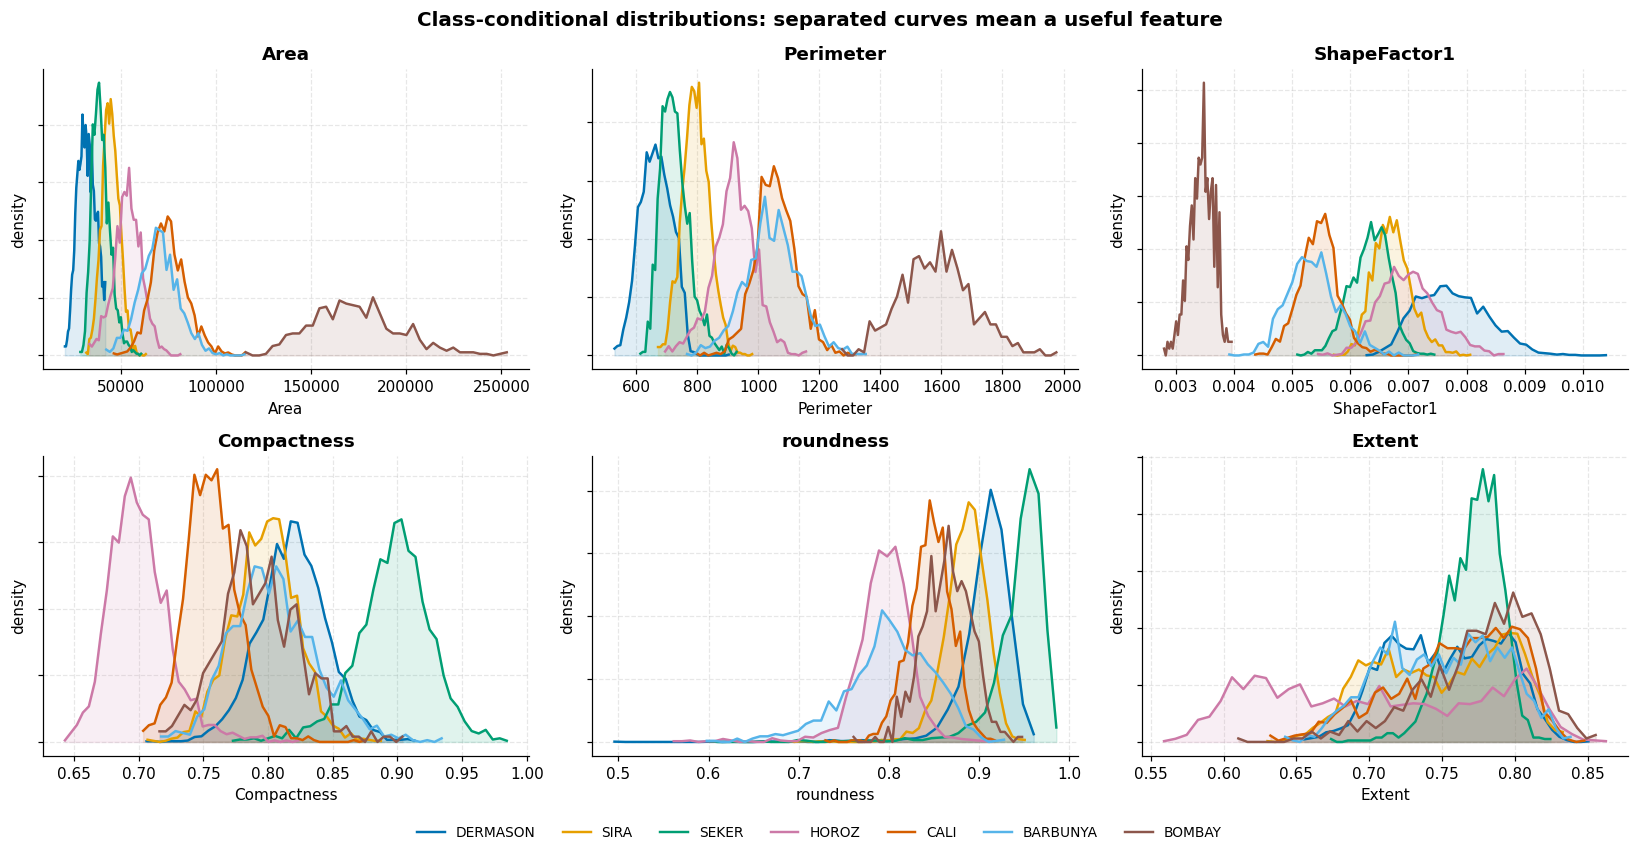

In [8]:
# Six features chosen to span the behaviours in the data: two raw size
# measurements, and four shape descriptors with visibly different quality.
eda_features = ["Area", "Perimeter", "ShapeFactor1", "Compactness", "roundness", "Extent"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, feature in zip(axes.ravel(), eda_features):
    for cls in CLASS_ORDER:
        values = clean.loc[clean[TARGET] == cls, feature]
        # A histogram-derived density keeps this dependency-free while still
        # showing the shape of each class-conditional distribution.
        density, edges = np.histogram(values, bins=40, density=True)
        centres = 0.5 * (edges[:-1] + edges[1:])
        ax.plot(centres, density, color=CLASS_COLORS[cls], linewidth=1.6, label=cls)
        ax.fill_between(centres, density, color=CLASS_COLORS[cls], alpha=0.12)
    ax.set_xlabel(feature)
    ax.set_ylabel("density")
    ax.set_title(feature)
    ax.set_yticklabels([])

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=7, fontsize=9, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("Class-conditional distributions: separated curves mean a useful feature",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

The contrast between the panels is the point. `Area` and `Perimeter` clearly isolate BOMBAY, whose
beans are much larger than every other variety, which is the first sign that the rarest class will
turn out to be the *easiest* one, not the hardest. `ShapeFactor1` and `Compactness` spread the
remaining varieties out. `Extent`, by contrast, puts every class on top of every other, and
Section 4 confirms quantitatively that it is the least useful of the sixteen.

### 3.5 Selected pairs of variables

Two pairs are plotted below: one chosen because the varieties separate well in it, and one chosen
because they overlap badly. The second is the more informative plot, because the overlap it shows
is what limits every model in this notebook.

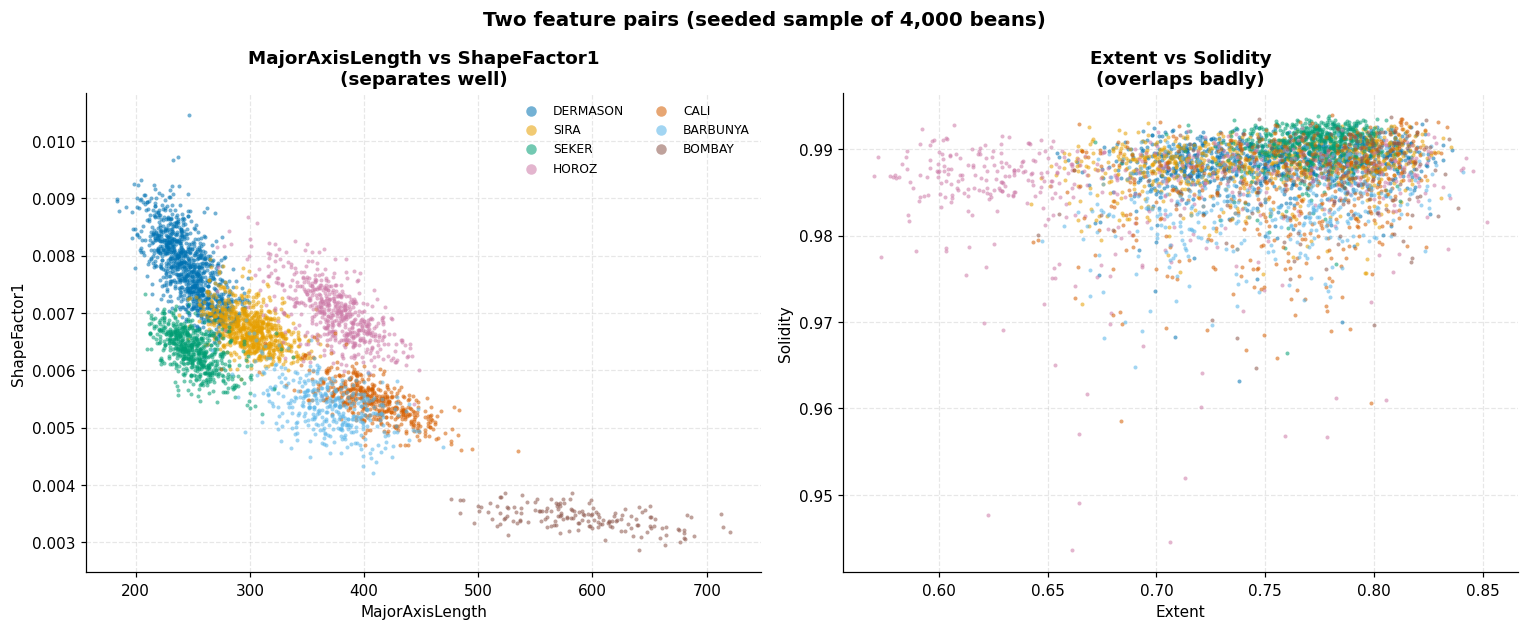

In [9]:
GOOD_PAIR = ("MajorAxisLength", "ShapeFactor1")
POOR_PAIR = ("Extent", "Solidity")

# 13.5k markers would be an unreadable smear, so a seeded sample is plotted.
sample = clean.sample(n=4000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
for ax, (xf, yf), label in zip(axes, [GOOD_PAIR, POOR_PAIR], ["separates well", "overlaps badly"]):
    for cls in CLASS_ORDER:
        subset = sample[sample[TARGET] == cls]
        ax.scatter(subset[xf], subset[yf], s=7, alpha=0.55,
                   color=CLASS_COLORS[cls], label=cls, linewidths=0)
    ax.set_xlabel(xf)
    ax.set_ylabel(yf)
    ax.set_title(f"{xf} vs {yf}\n({label})")

axes[0].legend(markerscale=2.6, fontsize=8, loc="best", ncol=2)
fig.suptitle(f"Two feature pairs (seeded sample of {len(sample):,} beans)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In the left panel the varieties form distinguishable bands, with BOMBAY sitting well away from
everything else. In the right panel they are piled on top of one another, so no decision boundary
drawn in that plane could do much. Section 6 returns to these same planes and draws the actual
boundaries each model learns in them.

### 3.6 How close to linearly separable is the problem?

A two-component PCA gives a quick view of the global structure. The scaler and the PCA are fitted
on the **training set only**, fitting them on all the data before the split would leak test
information into the projection.

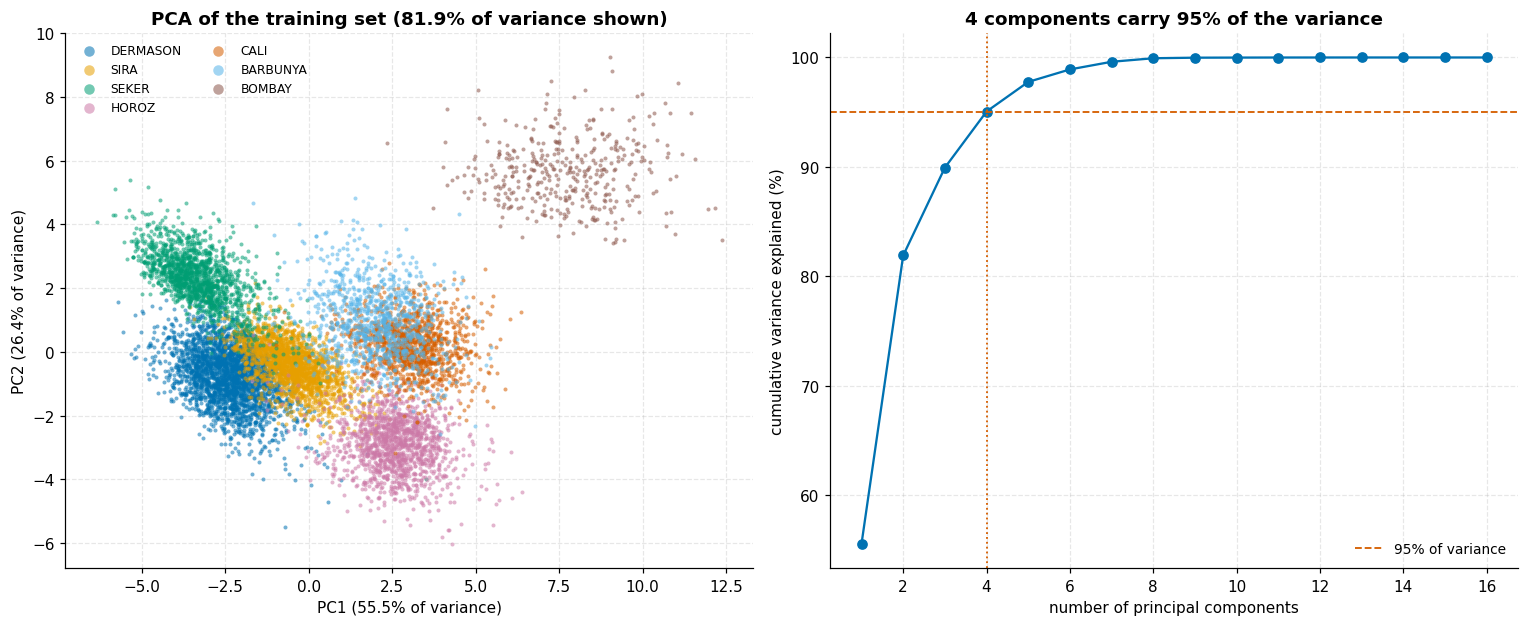

PC1 + PC2 explain 81.9% of the variance
4 of 16 components explain 95%, the 16 features hold far less than 16 dimensions of information


In [10]:
pca_pipeline = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2, random_state=RANDOM_STATE))])
train_projected = pca_pipeline.fit_transform(X_train)
explained = pca_pipeline.named_steps["pca"].explained_variance_ratio_

# How much structure the first components hold overall.
full_pca = Pipeline([("scaler", StandardScaler()), ("pca", PCA(random_state=RANDOM_STATE))]).fit(X_train)
cumulative = np.cumsum(full_pca.named_steps["pca"].explained_variance_ratio_)

fig, (ax_scatter, ax_scree) = plt.subplots(1, 2, figsize=(14, 5.8))
for cls in CLASS_ORDER:
    mask = (y_train == cls).to_numpy()
    ax_scatter.scatter(train_projected[mask, 0], train_projected[mask, 1], s=7, alpha=0.55,
                       color=CLASS_COLORS[cls], label=cls, linewidths=0)
ax_scatter.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax_scatter.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax_scatter.set_title(f"PCA of the training set ({explained.sum():.1%} of variance shown)")
ax_scatter.legend(markerscale=2.6, fontsize=8, ncol=2)

ax_scree.plot(range(1, len(cumulative) + 1), 100 * cumulative, "o-", color="#0072B2")
ax_scree.axhline(95, color="#D55E00", linestyle="--", linewidth=1.2, label="95% of variance")
n_95 = int(np.searchsorted(cumulative, 0.95) + 1)
ax_scree.axvline(n_95, color="#D55E00", linestyle=":", linewidth=1.2)
ax_scree.set_xlabel("number of principal components")
ax_scree.set_ylabel("cumulative variance explained (%)")
ax_scree.set_title(f"{n_95} components carry 95% of the variance")
ax_scree.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"PC1 + PC2 explain {explained.sum():.1%} of the variance")
print(f"{n_95} of 16 components explain 95%, the 16 features hold far less than 16 dimensions of information")

Two things stand out. First, BOMBAY is completely detached from the other varieties, confirming
that it should be trivial to classify. Second, the remaining six classes form a single connected
ribbon with neighbouring varieties blending into one another, especially in the dense region where
DERMASON and SIRA meet. That blending is a genuine property of the data and not a projection
artefact, and it is what caps every model in this notebook at roughly 92%.

The scree curve also shows that the 16 features carry far less than 16 dimensions of independent
information, which is the collinearity from Section 3.3 seen from another angle.

### 3.7 What the exploration establishes

| Finding | Consequence for the modelling |
|---|---|
| Classes imbalanced 6.8:1; majority baseline 26.2% | Report balanced accuracy and macro F1, not accuracy alone; stratify every split |
| Features span five orders of magnitude | Standardise inside every pipeline, or `Area` dominates the penalty and the kernel |
| Many pairs above \|r\| = 0.95 | Individual coefficients are unstable; verify importance with permutation tests too |
| BOMBAY is cleanly separated; DERMASON and SIRA overlap heavily | Expect near-perfect recall on the rare class and concentrated errors on one pair |
| Classes form one connected ribbon, nearly separable | A linear model should do well; a kernel may add a little, not a lot |

---
## 4. Which variables are predictive of the target variable?

**Project question 1.**

"Predictive" can mean several different things, and the methods that measure it disagree in
instructive ways. Six are used here, in increasing order of how much they account for the other
features:

| Method | What it measures | Blind spot |
|---|---|---|
| ANOVA F-statistic | How far apart the class means are, one feature at a time | Only linear, monotone separation |
| Mutual information | Any statistical dependence, one feature at a time | Needs more data; no direction |
| Single-feature CV accuracy | How well that feature alone actually classifies | Ignores combinations |
| Logistic-regression coefficients | Weight given once all features compete | Unstable under collinearity |
| Permutation importance | Accuracy lost when the feature is shuffled | Splits credit between duplicates |
| Forward selection | Whether the feature adds anything new | Greedy; order-dependent |

The first three are **marginal** (one feature in isolation) and the last three are **conditional**
(a feature's value given the others). With the collinearity found in Section 3.3, these two groups
should be expected to disagree, and the disagreement is itself the finding.

### 4.1 Univariate filters

Both filters are computed on the **training set only**, since using the test set to rank features
and then reporting test accuracy would leak.

,anova_f,anova_p,mutual_info,rank_anova_f,rank_mutual_info,rank_gap
Area,21742.7288,0.0,1.0308,1,4,-3
ConvexArea,21733.6437,0.0,1.0359,2,2,0
EquivDiameter,19027.4553,0.0,1.0316,3,3,0
Perimeter,18334.0050,0.0,1.0552,4,1,3
MinorAxisLength,16780.2486,0.0,0.9233,5,8,-3
MajorAxisLength,16119.4335,0.0,0.9935,6,5,1
ShapeFactor2,9142.6531,0.0,0.9447,7,6,1
ShapeFactor1,9115.5104,0.0,0.9255,8,7,1
AspectRation,7593.8770,0.0,0.8135,9,11,-2
Compactness,7486.5383,0.0,0.8270,10,10,0


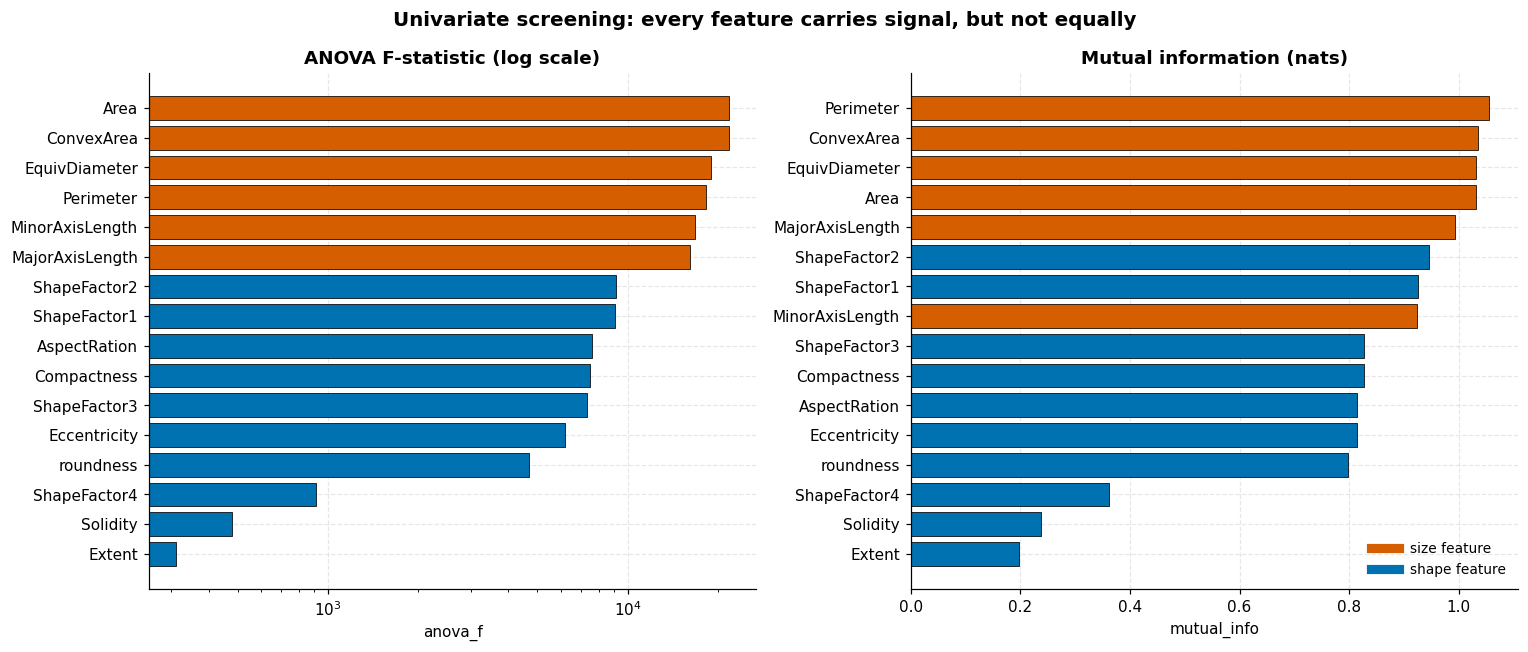

all 16 features reject independence at p < 0.001: True
weakest by both filters: Extent (F) / Extent (MI)


In [11]:
f_statistic, f_pvalue = f_classif(X_train, y_train)
mutual_info = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)

filters = pd.DataFrame({
    "anova_f": f_statistic,
    "anova_p": f_pvalue,
    "mutual_info": mutual_info,
}, index=FEATURES)
filters["rank_anova_f"] = filters["anova_f"].rank(ascending=False).astype(int)
filters["rank_mutual_info"] = filters["mutual_info"].rank(ascending=False).astype(int)
filters["rank_gap"] = filters["rank_anova_f"] - filters["rank_mutual_info"]

display(filters.sort_values("anova_f", ascending=False).round(4))

fig, (ax_f, ax_mi) = plt.subplots(1, 2, figsize=(14, 6))
for ax, column, title in [
    (ax_f, "anova_f", "ANOVA F-statistic (log scale)"),
    (ax_mi, "mutual_info", "Mutual information (nats)"),
]:
    ordered = filters[column].sort_values()
    colours = ["#D55E00" if f in SIZE_FEATURES else "#0072B2" for f in ordered.index]
    ax.barh(ordered.index, ordered.values, color=colours, edgecolor="black", linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel(column)
ax_f.set_xscale("log")
handles = [
    plt.Line2D([], [], color="#D55E00", linewidth=6, label="size feature"),
    plt.Line2D([], [], color="#0072B2", linewidth=6, label="shape feature"),
]
ax_mi.legend(handles=handles, loc="lower right", fontsize=9)
fig.suptitle("Univariate screening: every feature carries signal, but not equally",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"all 16 features reject independence at p < 0.001: "
      f"{bool((filters['anova_p'] < 0.001).all())}")
print(f"weakest by both filters: {filters['anova_f'].idxmin()} (F) / {filters['mutual_info'].idxmin()} (MI)")

Every feature is "significant" by the F-test, which is a good illustration of why statistical
significance is not the same as usefulness: with over 10,000 training rows, even a tiny difference
in class means produces a tiny p-value. The *size* of the statistic is what matters, and it spans
several orders of magnitude.

The two filters broadly agree, and both put `Extent` last.

### 4.2 How well does each feature do on its own?

An F-statistic is hard to interpret directly. Cross-validated accuracy from a single feature is
not, so it is a more honest answer to "is this variable predictive?".

,cv_accuracy,cv_std,rank_solo_cv,vs_baseline
Perimeter,0.6370,0.0071,1,0.3752
ConvexArea,0.6352,0.0051,2,0.3734
Area,0.6346,0.0050,3,0.3728
EquivDiameter,0.6337,0.0064,4,0.3718
MajorAxisLength,0.6141,0.0047,5,0.3522
ShapeFactor2,0.6068,0.0062,6,0.3449
Compactness,0.6053,0.0044,7,0.3435
ShapeFactor3,0.6047,0.0048,8,0.3429
Eccentricity,0.6019,0.0043,9,0.3400
AspectRation,0.6000,0.0050,10,0.3381


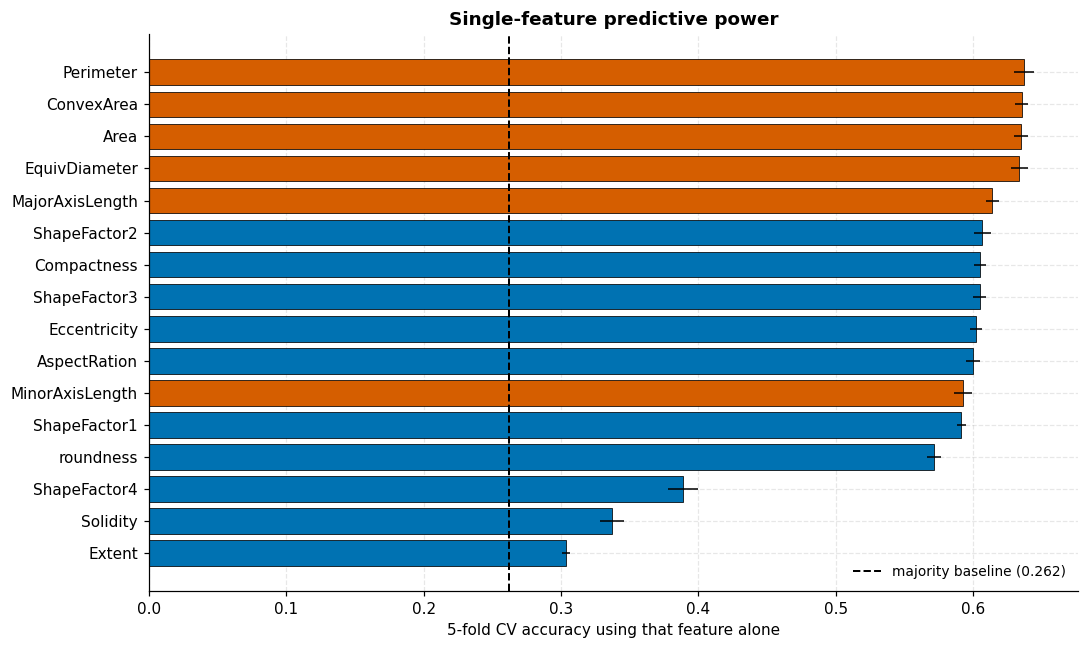

best single feature: Perimeter at 0.6370
  that is +0.3752 over the majority baseline
features no better than the baseline + 1 point: none


In [12]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

solo_scores = {}
for feature in FEATURES:
    scores = cross_val_score(
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
        X_train[[feature]], y_train, cv=cv, scoring="accuracy", n_jobs=N_JOBS,
    )
    solo_scores[feature] = (scores.mean(), scores.std())

solo = pd.DataFrame(solo_scores, index=["cv_accuracy", "cv_std"]).T.sort_values("cv_accuracy", ascending=False)
solo["rank_solo_cv"] = solo["cv_accuracy"].rank(ascending=False).astype(int)
solo["vs_baseline"] = solo["cv_accuracy"] - majority_baseline
display(solo.round(4))

fig, ax = plt.subplots(figsize=(10, 6))
ordered = solo.sort_values("cv_accuracy")
colours = ["#D55E00" if f in SIZE_FEATURES else "#0072B2" for f in ordered.index]
ax.barh(ordered.index, ordered["cv_accuracy"], xerr=ordered["cv_std"],
        color=colours, edgecolor="black", linewidth=0.5, error_kw={"linewidth": 1})
ax.axvline(majority_baseline, color="black", linestyle="--", linewidth=1.3,
           label=f"majority baseline ({majority_baseline:.3f})")
ax.set_xlabel("5-fold CV accuracy using that feature alone")
ax.set_title("Single-feature predictive power")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

best_solo = solo.index[0]
print(f"best single feature: {best_solo} at {solo.loc[best_solo, 'cv_accuracy']:.4f}")
print(f"  that is {solo.loc[best_solo, 'vs_baseline']:+.4f} over the majority baseline")
useless = solo[solo["cv_accuracy"] <= majority_baseline + 0.01]
print(f"features no better than the baseline + 1 point: {list(useless.index) or 'none'}")

### 4.3 Logistic-regression coefficients, and why they cannot be trusted alone

Because the features are standardised, the coefficients are directly comparable to each other.
`LogisticRegression` fits a **multinomial** model here (see Section 10.5), so `coef_` has one row
per class: 7 x 16 weights rather than a single ranking.

The second panel is the important one. The model is refitted on each cross-validation fold, and the
spread of each coefficient across those refits is plotted. A feature whose weight swings wildly
between near-identical training sets is not giving a stable answer about importance.

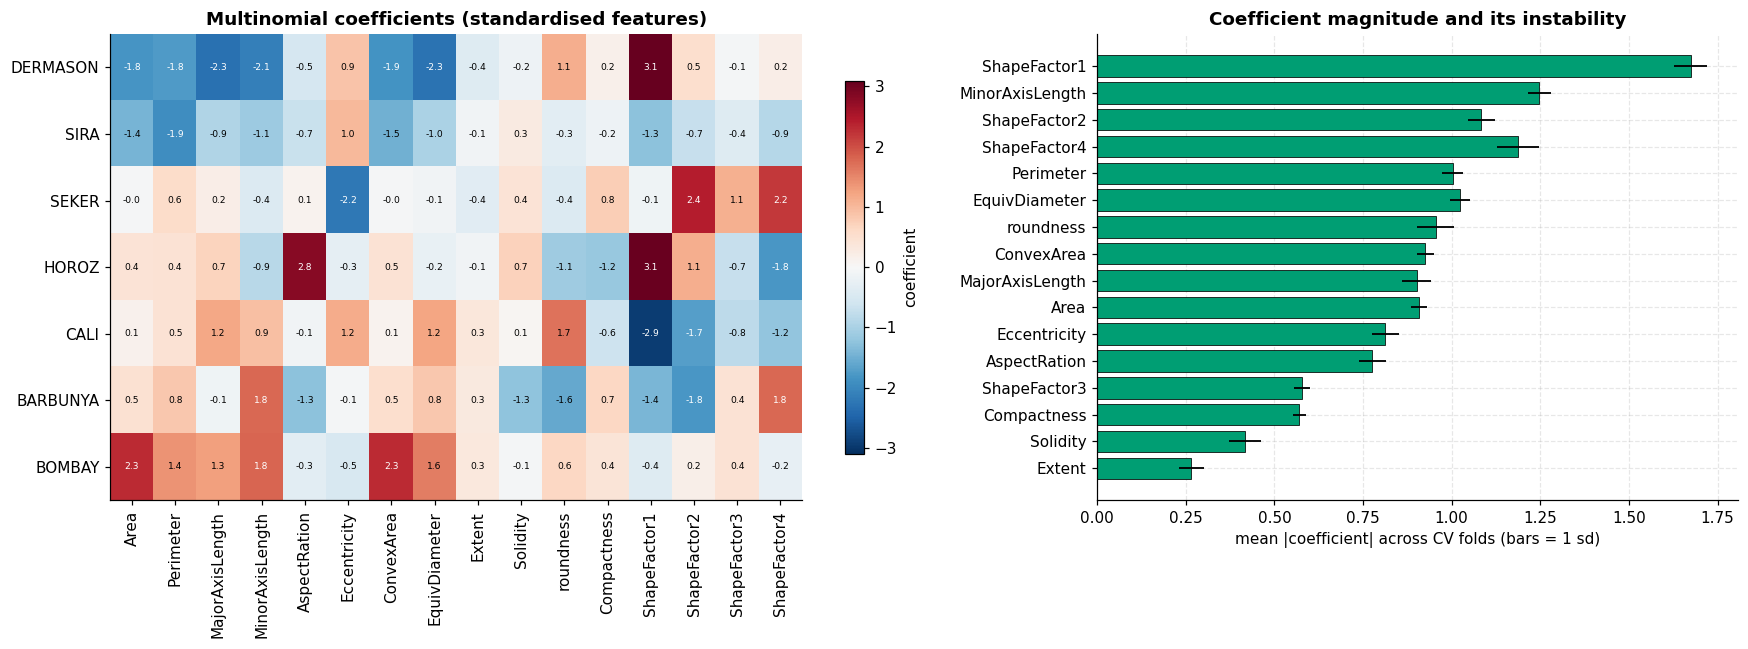

most unstable coefficients (highest std / mean across folds):


,fold_mean,fold_std,coef_variation
Extent,0.2661,0.0340,0.1278
Solidity,0.4183,0.0452,0.1080
roundness,0.9549,0.0527,0.0552
ShapeFactor4,1.1870,0.0604,0.0509
AspectRation,0.7765,0.0380,0.0489
Eccentricity,0.8123,0.0385,0.0473


In [13]:
logreg = Pipeline([("scaler", StandardScaler()),
                   ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
logreg.fit(X_train, y_train)
coefficients = pd.DataFrame(
    logreg.named_steps["clf"].coef_,
    index=logreg.named_steps["clf"].classes_,
    columns=FEATURES,
).reindex(CLASS_ORDER)

# Refit per fold to measure how stable each coefficient is.
fold_coefficients = []
for train_index, _ in cv.split(X_train, y_train):
    fold_model = Pipeline([("scaler", StandardScaler()),
                           ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])
    fold_model.fit(X_train.iloc[train_index], y_train.iloc[train_index])
    fold_coefficients.append(np.abs(fold_model.named_steps["clf"].coef_).mean(axis=0))
fold_coefficients = np.vstack(fold_coefficients)

stability = pd.DataFrame({
    "mean_abs_coef": np.abs(coefficients.values).mean(axis=0),
    "fold_mean": fold_coefficients.mean(axis=0),
    "fold_std": fold_coefficients.std(axis=0),
}, index=FEATURES)
stability["coef_variation"] = stability["fold_std"] / stability["fold_mean"]
stability["rank_logreg_coef"] = stability["mean_abs_coef"].rank(ascending=False).astype(int)

fig, (ax_heat, ax_stab) = plt.subplots(1, 2, figsize=(16, 6),
                                       gridspec_kw={"width_ratios": [1.35, 1]})

limit = np.abs(coefficients.values).max()
image = ax_heat.imshow(coefficients.values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax_heat.set_xticks(range(len(FEATURES)))
ax_heat.set_xticklabels(FEATURES, rotation=90)
ax_heat.set_yticks(range(len(CLASS_ORDER)))
ax_heat.set_yticklabels(CLASS_ORDER)
for i in range(len(CLASS_ORDER)):
    for j in range(len(FEATURES)):
        value = coefficients.values[i, j]
        ax_heat.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=6,
                     color="white" if abs(value) > 0.55 * limit else "black")
ax_heat.set_title("Multinomial coefficients (standardised features)")
ax_heat.grid(False)
fig.colorbar(image, ax=ax_heat, shrink=0.8, label="coefficient")

ordered = stability.sort_values("mean_abs_coef")
ax_stab.barh(ordered.index, ordered["fold_mean"], xerr=ordered["fold_std"],
             color="#009E73", edgecolor="black", linewidth=0.5, error_kw={"linewidth": 1.2})
ax_stab.set_xlabel("mean |coefficient| across CV folds (bars = 1 sd)")
ax_stab.set_title("Coefficient magnitude and its instability")
fig.tight_layout()
plt.show()

print("most unstable coefficients (highest std / mean across folds):")
display(stability.sort_values("coef_variation", ascending=False)
        .head(6)[["fold_mean", "fold_std", "coef_variation"]].round(4))

In [14]:
# Area and ConvexArea correlate at r = 0.99994, so in principle the fit could
# trade weight between them almost freely. Refitting on bootstrap resamples
# shows what the L2 penalty actually does with that freedom.
#
# The coefficients are read from a SINGLE class row. A multinomial model's
# coefficients sum to zero across the classes, so averaging over classes would
# cancel every feature to zero and measure nothing.
PAIR = ("Area", "ConvexArea")
FOCUS_CLASS = "DERMASON"
print(f"r({PAIR[0]}, {PAIR[1]}) = {X[PAIR[0]].corr(X[PAIR[1]]):.6f}")
print(f"coefficients read from the {FOCUS_CLASS} row\n")

# Two penalty strengths: the default, and a much weaker one. If the even split
# is an effect of regularisation, weakening it should loosen the split.
bootstrap_summaries = []
for penalty_C in (1.0, 1000.0):
    rows = []
    boot_rng = np.random.default_rng(RANDOM_STATE)
    for _ in range(12):
        index = boot_rng.choice(len(X_train), size=len(X_train), replace=True)
        model = Pipeline([("scaler", StandardScaler()),
                          ("clf", LogisticRegression(C=penalty_C, max_iter=5000,
                                                     random_state=RANDOM_STATE))])
        model.fit(X_train.iloc[index], y_train.iloc[index])
        class_row = list(model.named_steps["clf"].classes_).index(FOCUS_CLASS)
        weights = model.named_steps["clf"].coef_[class_row]
        rows.append({PAIR[0]: weights[FEATURES.index(PAIR[0])],
                     PAIR[1]: weights[FEATURES.index(PAIR[1])]})
    frame = pd.DataFrame(rows)
    frame["sum"] = frame[PAIR[0]] + frame[PAIR[1]]
    bootstrap_summaries.append({
        "C": penalty_C,
        "mean_first": frame[PAIR[0]].mean(),
        "mean_second": frame[PAIR[1]].mean(),
        "sd_first": frame[PAIR[0]].std(),
        "sd_second": frame[PAIR[1]].std(),
        "sd_of_sum": frame["sum"].std(),
        "corr_across_resamples": frame[PAIR[0]].corr(frame[PAIR[1]]),
    })
    if penalty_C == 1.0:
        default_frame = frame

print("the 12 resampled fits at the default C=1.0:")
display(default_frame.round(3))
print("\nsummary (first = Area, second = ConvexArea):")
display(pd.DataFrame(bootstrap_summaries).set_index("C").round(4))

r(Area, ConvexArea) = 0.999940
coefficients read from the DERMASON row



the 12 resampled fits at the default C=1.0:


,Area,ConvexArea,sum
0,-1.605,-1.620,-3.225
1,-1.777,-1.802,-3.579
2,-1.801,-1.807,-3.608
3,-1.779,-1.803,-3.582
4,-1.848,-1.862,-3.710
5,-1.661,-1.682,-3.343
6,-1.831,-1.835,-3.667
7,-1.717,-1.741,-3.458
8,-1.629,-1.636,-3.264
9,-1.936,-1.952,-3.888



summary (first = Area, second = ConvexArea):


,mean_first,mean_second,sd_first,sd_second,sd_of_sum,corr_across_resamples
C,,,,,,
1.0,-1.7725,-1.7881,0.1016,0.101,0.2025,0.9974
1000.0,-8.4180,-9.9965,3.9810,4.456,8.4134,0.9888


This result is worth reading closely, because it is **not** the textbook one.

The classic warning about collinearity is that the fit will "seesaw": a large positive weight on
one feature offset by a large negative weight on its near-duplicate, swinging arbitrarily from one
sample to the next. That does not happen here. The two coefficients come out **almost identical to
each other in every resample**, they move **together** rather than in opposition (their correlation
across resamples is strongly positive, not negative), and each is individually stable to within a
few percent of its value.

The reason is the **L2 penalty**, which scikit-learn applies by default. Among all the weight
combinations that fit the data about equally well, the ridge penalty prefers the one with the
smallest sum of squares, and for two interchangeable features that is the one which **splits the
weight evenly between them**. Regularisation resolves the indeterminacy that would otherwise leave
the coefficients arbitrary. Weakening the penalty, in the second row of the summary table, loosens
that grip.

So the genuine interpretive hazard on this dataset is not instability but **double counting**.
`Area` and `ConvexArea` each receive about half of one feature's worth of influence, so reading the
two coefficients as independent evidence counts the same underlying measurement, how big the bean
is, twice over. That is exactly the distortion that shows up in Section 4.6, where the size
features rank high marginally and drop once the other features are accounted for, and it is why
permutation importance is reported next as a cross-check: shuffling either feature alone barely
hurts, because the model reads the same information from its twin.

### 4.4 Permutation importance

Permutation importance shuffles one column of the **held-out test set** and measures how much
accuracy is lost. It is model-agnostic, so the same procedure can be applied to the linear model
and to the RBF SVM and the answers compared, a feature can be worthless to a linear model and
still matter to a kernel one.

The known caveat: when two features are near-duplicates, shuffling either one alone barely hurts,
because the model reads the information from the other. Both can therefore look unimportant despite
the pair being essential.

Logistic Regression: computed over 16 features x 5 repeats


RBF SVM: computed over 16 features x 5 repeats


,perm_logreg,perm_logreg_std,perm_rbf,perm_rbf_std,rank_perm_logreg,rank_perm_rbf
roundness,0.0675,0.0052,0.0761,0.0039,6,1
ShapeFactor4,0.0796,0.0033,0.0679,0.0015,5,2
ShapeFactor1,0.1953,0.0046,0.0646,0.0049,1,3
MinorAxisLength,0.0319,0.0020,0.0278,0.0031,11,4
Eccentricity,0.0946,0.0023,0.0248,0.0009,3,5
Perimeter,0.0383,0.0034,0.0240,0.0034,10,6
EquivDiameter,0.0280,0.0022,0.0200,0.0018,12,7
ShapeFactor3,0.0194,0.0021,0.0183,0.0016,13,8
AspectRation,0.0972,0.0016,0.0177,0.0007,2,9
Compactness,0.0156,0.0032,0.0173,0.0023,14,10


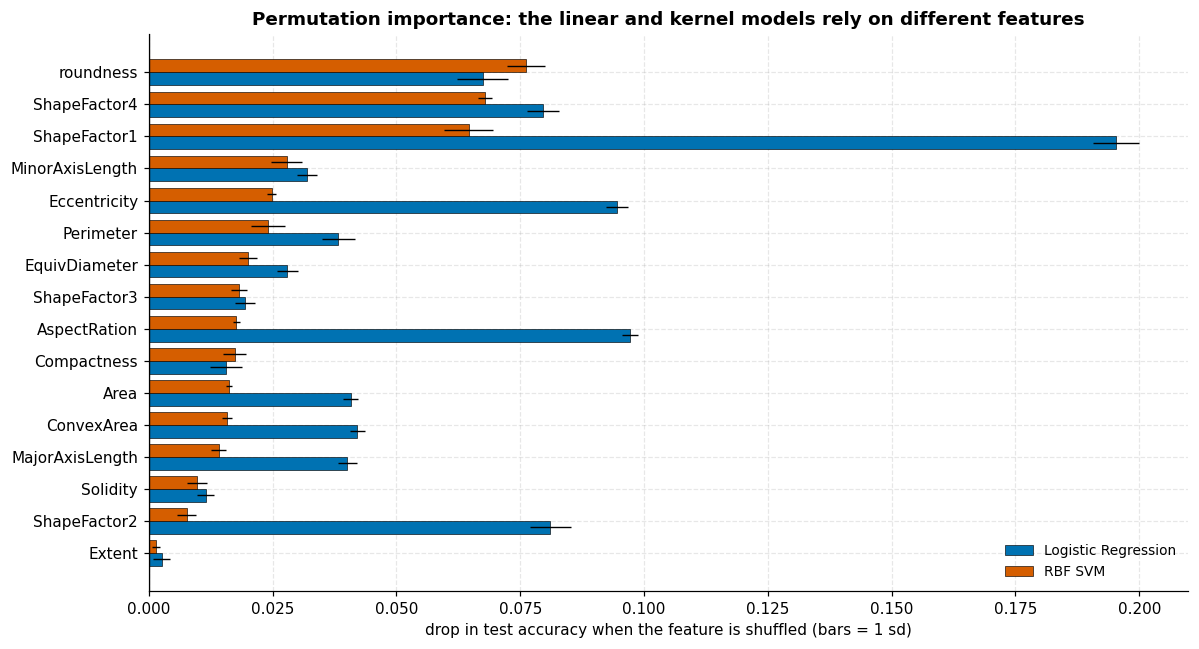

largest rank disagreements between the two models:
  ShapeFactor2     logreg rank  4  vs  RBF rank 15
  MinorAxisLength  logreg rank 11  vs  RBF rank  4
  AspectRation     logreg rank  2  vs  RBF rank  9
  ConvexArea       logreg rank  7  vs  RBF rank 12


In [15]:
rbf_default = Pipeline([("scaler", StandardScaler()),
                        ("clf", SVC(kernel="rbf", random_state=RANDOM_STATE, cache_size=500))])
rbf_default.fit(X_train, y_train)

# n_repeats is kept modest: each repeat costs one full predict pass per feature,
# and RBF prediction is the slow part.
permutation_results = {}
for name, model in [("Logistic Regression", logreg), ("RBF SVM", rbf_default)]:
    result = permutation_importance(
        model, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE,
        scoring="accuracy", n_jobs=N_JOBS,
    )
    permutation_results[name] = result
    print(f"{name}: computed over {len(FEATURES)} features x 5 repeats")

permutation = pd.DataFrame({
    "perm_logreg": permutation_results["Logistic Regression"].importances_mean,
    "perm_logreg_std": permutation_results["Logistic Regression"].importances_std,
    "perm_rbf": permutation_results["RBF SVM"].importances_mean,
    "perm_rbf_std": permutation_results["RBF SVM"].importances_std,
}, index=FEATURES)
permutation["rank_perm_logreg"] = permutation["perm_logreg"].rank(ascending=False).astype(int)
permutation["rank_perm_rbf"] = permutation["perm_rbf"].rank(ascending=False).astype(int)
display(permutation.sort_values("perm_rbf", ascending=False).round(4))

fig, ax = plt.subplots(figsize=(11, 6))
positions = np.arange(len(FEATURES))
ordered = permutation.sort_values("perm_rbf")
height = 0.4
ax.barh(positions - height / 2, ordered["perm_logreg"], height, xerr=ordered["perm_logreg_std"],
        label="Logistic Regression", color=MODEL_COLORS["Logistic Regression"],
        edgecolor="black", linewidth=0.4, error_kw={"linewidth": 0.9})
ax.barh(positions + height / 2, ordered["perm_rbf"], height, xerr=ordered["perm_rbf_std"],
        label="RBF SVM", color=MODEL_COLORS["RBF SVM"],
        edgecolor="black", linewidth=0.4, error_kw={"linewidth": 0.9})
ax.set_yticks(positions)
ax.set_yticklabels(ordered.index)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("drop in test accuracy when the feature is shuffled (bars = 1 sd)")
ax.set_title("Permutation importance: the linear and kernel models rely on different features")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

disagreement = (permutation["rank_perm_logreg"] - permutation["rank_perm_rbf"]).abs().sort_values(ascending=False)
print("largest rank disagreements between the two models:")
for feature in disagreement.head(4).index:
    print(f"  {feature:16s} logreg rank {permutation.loc[feature, 'rank_perm_logreg']:2d}"
          f"  vs  RBF rank {permutation.loc[feature, 'rank_perm_rbf']:2d}")

### 4.5 How many features are actually needed?

Ranking features says which ones matter; it does not say how many are needed. Two incremental
curves answer that. The first adds features in ANOVA order, cheap, but it adds redundant features
early because the F-test does not know about correlation. The second is a **greedy forward
selection** that re-evaluates every remaining candidate at each step and keeps whichever adds most,
so it naturally avoids near-duplicates.

Both use cross-validation **on the training set only**, so the test set stays untouched.

greedy search capped at 8 features to bound runtime; ANOVA-order curve covers all 16


strategy,ANOVA order,greedy forward
n_features,,
1,0.6322,0.6374
2,0.6371,0.8883
3,0.6343,0.9071
4,0.7999,0.9186
5,0.9017,0.9214
6,0.9050,0.9230
7,0.9071,0.9238
8,0.9086,0.9251
9,0.9085,NaN


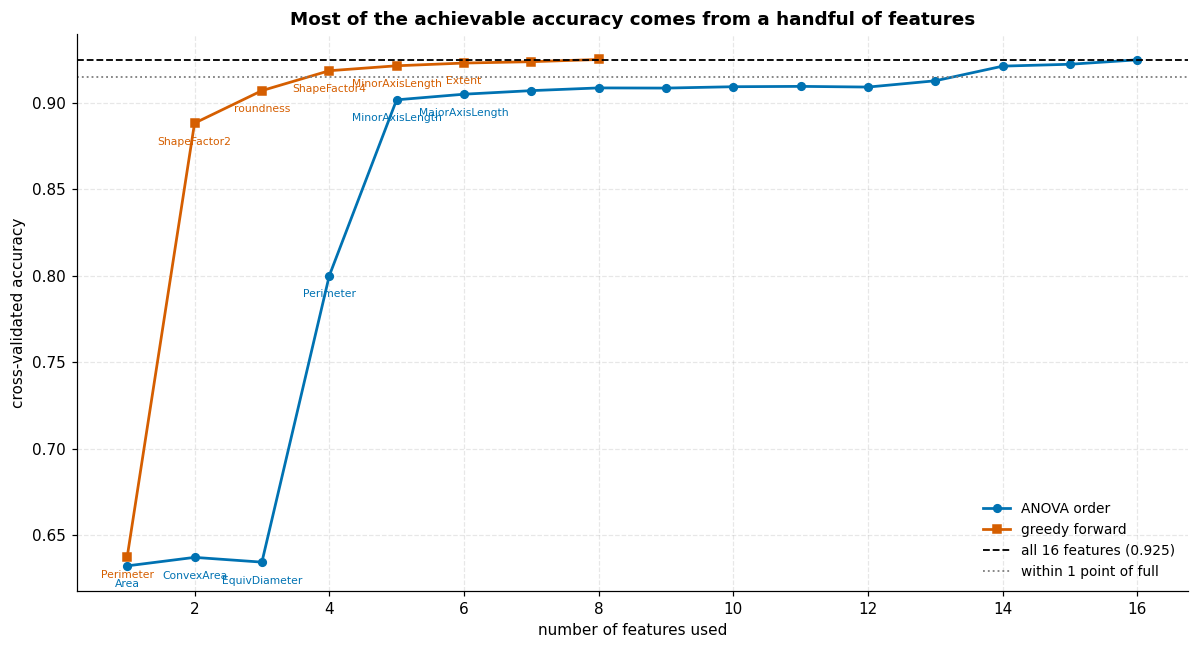

ANOVA order     : 14 features reach within 1 point of the full-feature score (0.9212 vs 0.9249)
greedy forward  : 4 features reach within 1 point of the full-feature score (0.9186 vs 0.9249)


In [16]:
def cv_accuracy(columns: list[str], folds: int = 3) -> float:
    """Mean CV accuracy of logistic regression restricted to these columns."""
    return cross_val_score(
        Pipeline([("scaler", StandardScaler()),
                  ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
        X_train[columns], y_train,
        cv=StratifiedKFold(n_splits=folds, shuffle=True, random_state=RANDOM_STATE),
        scoring="accuracy", n_jobs=N_JOBS,
    ).mean()


# Curve 1: ANOVA order, all 16 steps.
anova_order = filters.sort_values("anova_f", ascending=False).index.tolist()
anova_curve = [
    {"n_features": k, "added": anova_order[k - 1], "cv_accuracy": cv_accuracy(anova_order[:k]),
     "strategy": "ANOVA order"}
    for k in range(1, len(anova_order) + 1)
]

# Curve 2: greedy forward selection, capped at 8 features to bound the runtime
# (a full 16-step greedy search would need 136 subset evaluations).
GREEDY_STEPS = 8
selected, remaining, greedy_curve = [], FEATURES.copy(), []
for step in range(GREEDY_STEPS):
    scored = [(cv_accuracy(selected + [candidate]), candidate) for candidate in remaining]
    best_score, best_feature = max(scored)
    selected.append(best_feature)
    remaining.remove(best_feature)
    greedy_curve.append({"n_features": step + 1, "added": best_feature,
                         "cv_accuracy": best_score, "strategy": "greedy forward"})

print(f"greedy search capped at {GREEDY_STEPS} features to bound runtime; "
      f"ANOVA-order curve covers all {len(FEATURES)}")

selection = pd.DataFrame(anova_curve + greedy_curve)
full_score = selection.loc[selection["strategy"] == "ANOVA order", "cv_accuracy"].iloc[-1]
display(selection.pivot_table(index="n_features", columns="strategy", values="cv_accuracy").round(4))

fig, ax = plt.subplots(figsize=(11, 6))
for strategy, colour, marker in [("ANOVA order", "#0072B2", "o"), ("greedy forward", "#D55E00", "s")]:
    part = selection[selection["strategy"] == strategy]
    ax.plot(part["n_features"], part["cv_accuracy"], marker=marker, color=colour,
            linewidth=1.8, markersize=5, label=strategy)
    for _, row in part.iterrows():
        if row["n_features"] <= 6:
            ax.annotate(row["added"], (row["n_features"], row["cv_accuracy"]),
                        textcoords="offset points", xytext=(0, -14), ha="center",
                        fontsize=7, rotation=0, color=colour)

ax.axhline(full_score, color="black", linestyle="--", linewidth=1.2,
           label=f"all 16 features ({full_score:.3f})")
ax.axhline(full_score - 0.01, color="grey", linestyle=":", linewidth=1.2,
           label="within 1 point of full")
ax.set_xlabel("number of features used")
ax.set_ylabel("cross-validated accuracy")
ax.set_title("Most of the achievable accuracy comes from a handful of features")
ax.legend(fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

for strategy in ["ANOVA order", "greedy forward"]:
    part = selection[selection["strategy"] == strategy]
    within = part[part["cv_accuracy"] >= full_score - 0.01]
    if len(within):
        k = int(within["n_features"].min())
        print(f"{strategy:16s}: {k} features reach within 1 point of the full-feature score "
              f"({part.set_index('n_features').loc[k, 'cv_accuracy']:.4f} vs {full_score:.4f})")
    else:
        print(f"{strategy:16s}: never reaches within 1 point within the steps computed")

The two curves separate exactly as predicted. The ANOVA-ordered curve stalls for its first three
steps, because the F-test's top features (`Area`, `ConvexArea`, `EquivDiameter`) are three
near-copies of the same measurement, adding the second and third contributes almost nothing. The
greedy curve climbs much faster, since after taking a size feature it immediately reaches for a
*shape* feature that carries different information.

The practical conclusion is that a small handful of well-chosen features recovers nearly all of the
achievable accuracy, and that **what a feature adds depends on what is already in the model**, a
point no single-feature ranking can express.

### 4.6 Consolidated answer

The table below puts every method's rank side by side, with the marginal methods separated from the
conditional ones.

,rank_anova_f,rank_mutual_info,rank_solo_cv,rank_logreg_coef,coef_variation,rank_perm_logreg,rank_perm_rbf,greedy_step,group,mean_rank_marginal,mean_rank_conditional,mean_rank_overall
Perimeter,4,1,1,5,0.03,10,6,1.0,size,2.00,7.00,4.50
ShapeFactor1,8,7,12,1,0.03,1,3,8.0,shape,9.00,1.67,5.33
ConvexArea,2,2,2,8,0.02,7,12,NaN,size,2.00,9.00,5.50
EquivDiameter,3,3,4,6,0.03,12,7,NaN,size,3.33,8.33,5.83
Area,1,4,3,10,0.03,8,11,NaN,size,2.67,9.67,6.17
MinorAxisLength,5,8,11,2,0.03,11,4,5.0,size,8.00,5.67,6.83
ShapeFactor2,7,6,6,3,0.04,4,15,2.0,shape,6.33,7.33,6.83
MajorAxisLength,6,5,5,9,0.05,9,13,NaN,size,5.33,10.33,7.83
Eccentricity,12,12,9,11,0.05,3,5,NaN,shape,11.00,6.33,8.67
AspectRation,9,11,10,12,0.05,2,9,NaN,shape,10.00,7.67,8.83


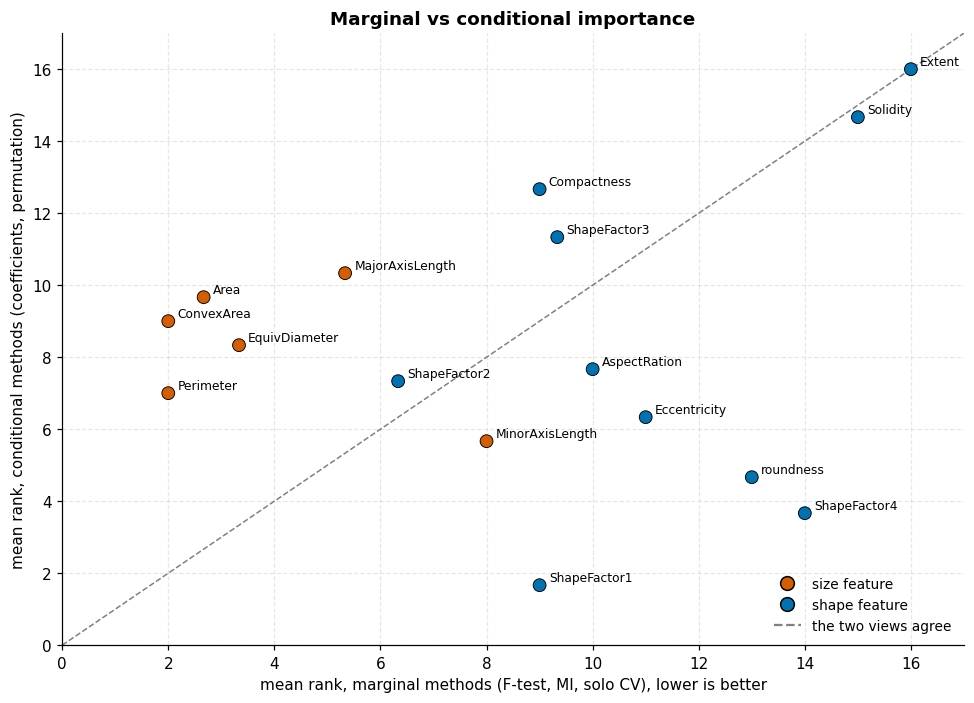

most predictive overall : Perimeter, ShapeFactor1, ConvexArea, EquivDiameter, Area
least predictive overall: Compactness, Solidity, Extent


In [17]:
greedy_order = {row["added"]: row["n_features"] for row in greedy_curve}
consolidated = pd.concat([
    filters[["rank_anova_f", "rank_mutual_info"]],
    solo[["rank_solo_cv"]],
    stability[["rank_logreg_coef", "coef_variation"]],
    permutation[["rank_perm_logreg", "rank_perm_rbf"]],
], axis=1)
consolidated["greedy_step"] = [greedy_order.get(f, np.nan) for f in consolidated.index]
consolidated["group"] = ["size" if f in SIZE_FEATURES else "shape" for f in consolidated.index]

marginal = ["rank_anova_f", "rank_mutual_info", "rank_solo_cv"]
conditional = ["rank_logreg_coef", "rank_perm_logreg", "rank_perm_rbf"]
consolidated["mean_rank_marginal"] = consolidated[marginal].mean(axis=1)
consolidated["mean_rank_conditional"] = consolidated[conditional].mean(axis=1)
consolidated["mean_rank_overall"] = consolidated[marginal + conditional].mean(axis=1)
consolidated = consolidated.sort_values("mean_rank_overall")

display(consolidated.round(2))

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.scatter(consolidated["mean_rank_marginal"], consolidated["mean_rank_conditional"],
           s=70, c=["#D55E00" if g == "size" else "#0072B2" for g in consolidated["group"]],
           edgecolor="black", linewidth=0.6, zorder=3)
for feature, row in consolidated.iterrows():
    ax.annotate(feature, (row["mean_rank_marginal"], row["mean_rank_conditional"]),
                textcoords="offset points", xytext=(6, 3), fontsize=8)
limits = [0, len(FEATURES) + 1]
ax.plot(limits, limits, color="grey", linestyle="--", linewidth=1, zorder=1,
        label="the two views agree")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_xlabel("mean rank, marginal methods (F-test, MI, solo CV), lower is better")
ax.set_ylabel("mean rank, conditional methods (coefficients, permutation)")
ax.set_title("Marginal vs conditional importance")
handles = [
    plt.Line2D([], [], marker="o", color="w", markerfacecolor="#D55E00", markersize=9,
               markeredgecolor="black", label="size feature"),
    plt.Line2D([], [], marker="o", color="w", markerfacecolor="#0072B2", markersize=9,
               markeredgecolor="black", label="shape feature"),
    plt.Line2D([], [], color="grey", linestyle="--", label="the two views agree"),
]
ax.legend(handles=handles, fontsize=9, loc="lower right")
fig.tight_layout()
plt.show()

top_overall = consolidated.head(5).index.tolist()
bottom_overall = consolidated.tail(3).index.tolist()
print(f"most predictive overall : {', '.join(top_overall)}")
print(f"least predictive overall: {', '.join(bottom_overall)}")

### 4.7 Answer to the question

**Which variables are predictive?** Taking the methods together:

- **The strongest predictors combine one size measurement with one shape descriptor.** `Perimeter`
  and the size group separate the large varieties, above all BOMBAY, while `ShapeFactor1`,
  `Compactness` and `roundness` distinguish varieties of similar size by their outline. Neither
  group is sufficient alone, which is why greedy selection alternates between them.
- **The size features are individually strong but collectively redundant.** They dominate the
  marginal rankings and fall in the conditional ones: points sitting well below the diagonal in the
  last figure are features whose apparent importance is really shared with a near-duplicate.
- **`Extent` and `Solidity` carry the least usable signal.** `Extent` is last or near-last by every
  method, and alone it barely beats the majority baseline.
- **A handful of features is enough.** The greedy curve reaches within a point of the full
  16-feature score well before using all of them, so the remaining features are mostly refinement.
- **The linear and kernel models lean on different features**, visible in the permutation ranks.
  Features whose relationship with the target is not monotone are worth more to the RBF SVM than to
  logistic regression.

The methodological lesson is that **no single importance measure is trustworthy on collinear data**.
Had only the coefficients been consulted, the conclusions would have been unstable; had only the
F-test been consulted, three copies of "how big is the bean" would have looked like the three most
important variables.

---
## 5. Can logistic regression or a linear SVM predict well?

**Project question 2.**

"Predict well" needs a reference point, so this section builds three of them: a trivial baseline, a
tuned version of each of the four models, and a statistical test of whether the differences between
them are real or just fold-to-fold noise.

The protocol matters as much as the numbers:

- Hyper-parameters are chosen by **5-fold stratified cross-validation on the training set only**.
- The **test set is used once**, at the end, for the final table.
- Because the classes are imbalanced, every comparison reports **balanced accuracy** and **macro
  F1** next to accuracy.

### 5.1 Baselines

A classifier has to beat the best uninformed guess. `DummyClassifier` provides three.

In [18]:
baselines = {}
for strategy in ["most_frequent", "stratified", "uniform"]:
    dummy = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE)
    dummy.fit(X_train, y_train)
    predicted = dummy.predict(X_test)
    baselines[f"dummy ({strategy})"] = {
        "accuracy": accuracy_score(y_test, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
        "macro_f1": f1_score(y_test, predicted, average="macro", zero_division=0),
    }

baseline_frame = pd.DataFrame(baselines).T
display(baseline_frame.round(4))
print(f"the number to beat on accuracy is {baseline_frame['accuracy'].max():.4f}")
print(f"note that balanced accuracy for any uninformed guess sits near 1/7 = {1 / 7:.4f}")

,accuracy,balanced_accuracy,macro_f1
dummy (most_frequent),0.2620,0.1429,0.0593
dummy (stratified),0.1760,0.1438,0.1437
dummy (uniform),0.1359,0.1317,0.1265


the number to beat on accuracy is 0.2620
note that balanced accuracy for any uninformed guess sits near 1/7 = 0.1429


### 5.2 Hyper-parameter search

Each model gets a grid over the parameter that governs its capacity. The grids are deliberately
modest so the search does not dominate the runtime, and the two SVC kernels additionally get their
shape parameters.

`refit` is on **accuracy**, but balanced accuracy is also recorded so it can be checked whether
optimising the two would have led to different choices.

In [19]:
PARAM_GRIDS = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    "Linear SVM": {"clf__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    "Polynomial SVM": {"clf__C": [0.1, 1.0, 10.0], "clf__degree": [2, 3, 4],
                       "clf__coef0": [0.0, 1.0]},
    "RBF SVM": {"clf__C": [0.1, 1.0, 10.0, 100.0],
                "clf__gamma": ["scale", 0.01, 0.1, 1.0]},
}


def base_estimator(name: str):
    """A fresh, unfitted pipeline for the named model."""
    if name == "Logistic Regression":
        clf = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    elif name == "Linear SVM":
        clf = LinearSVC(dual="auto", max_iter=20000, random_state=RANDOM_STATE)
    elif name == "Polynomial SVM":
        clf = SVC(kernel="poly", coef0=1.0, cache_size=500, random_state=RANDOM_STATE)
    elif name == "RBF SVM":
        clf = SVC(kernel="rbf", cache_size=500, random_state=RANDOM_STATE)
    else:
        raise ValueError(name)
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


MODEL_NAMES = list(PARAM_GRIDS)
search_rows, best_params, tuned_models = [], {}, {}

for name in MODEL_NAMES:
    search = GridSearchCV(
        base_estimator(name), PARAM_GRIDS[name], cv=cv, n_jobs=N_JOBS,
        scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
        refit="accuracy", return_train_score=False,
    )
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    results = search.cv_results_
    best = search.best_index_
    # Which settings would have been chosen had balanced accuracy been optimised?
    balanced_choice = int(np.argmax(results["mean_test_balanced_accuracy"]))

    best_params[name] = search.best_params_
    tuned_models[name] = search.best_estimator_
    search_rows.append({
        "model": name,
        "candidates": len(results["params"]),
        "fits": len(results["params"]) * CV_FOLDS,
        "best_params": ", ".join(f"{k.replace('clf__', '')}={v}" for k, v in search.best_params_.items()),
        "cv_accuracy": results["mean_test_accuracy"][best],
        "cv_accuracy_sd": results["std_test_accuracy"][best],
        "cv_balanced_accuracy": results["mean_test_balanced_accuracy"][best],
        "same_choice_if_balanced": balanced_choice == best,
        "search_seconds": elapsed,
    })
    print(f"{name:21s} best {search_rows[-1]['best_params']:30s} "
          f"cv={search_rows[-1]['cv_accuracy']:.4f}  ({elapsed:5.1f}s)")

search_frame = pd.DataFrame(search_rows).set_index("model")
display(search_frame.round(4))
print(f"\noptimising balanced accuracy instead would have changed the choice for: "
      f"{[n for n in MODEL_NAMES if not search_frame.loc[n, 'same_choice_if_balanced']] or 'no model'}")

Logistic Regression   best C=100.0                        cv=0.9259  (  0.9s)


Linear SVM            best C=100.0                        cv=0.9220  (  0.7s)


Polynomial SVM        best C=10.0, coef0=1.0, degree=4    cv=0.9334  (  6.7s)


RBF SVM               best C=10.0, gamma=0.1              cv=0.9346  (  9.6s)


,candidates,fits,best_params,cv_accuracy,cv_accuracy_sd,cv_balanced_accuracy,same_choice_if_balanced,search_seconds
model,,,,,,,,
Logistic Regression,5,25,C=100.0,0.9259,0.0061,0.9365,True,0.9104
Linear SVM,5,25,C=100.0,0.9220,0.0073,0.9330,True,0.6998
Polynomial SVM,18,90,"C=10.0, coef0=1.0, degree=4",0.9334,0.0043,0.9427,True,6.7424
RBF SVM,16,80,"C=10.0, gamma=0.1",0.9346,0.0062,0.9442,True,9.5678



optimising balanced accuracy instead would have changed the choice for: no model


Both linear models choose the **largest** `C` offered, meaning they want the *least*
regularisation available, a sign they are limited by the straightness of their boundary rather
than by overfitting. Section 7 confirms this from the learning curves.

### 5.3 Performance on the held-out test set

This is the one time the test set is used. The confidence interval is the normal approximation to a
binomial proportion, `p +/- 1.96 * sqrt(p(1-p)/n)` with `n = 3386`, which is appropriate here
because the test predictions are independent given the fitted model.

,accuracy,ci_low,ci_high,balanced_accuracy,macro_f1,weighted_f1,cohen_kappa,errors
model,,,,,,,,
Logistic Regression,0.9209,0.9118,0.9299,0.9321,0.9328,0.9211,0.9043,268
Linear SVM,0.9158,0.9065,0.9252,0.9270,0.9282,0.9162,0.8982,285
Polynomial SVM,0.9256,0.9167,0.9344,0.9356,0.9371,0.9257,0.9099,252
RBF SVM,0.9253,0.9164,0.9341,0.9358,0.9366,0.9253,0.9096,253


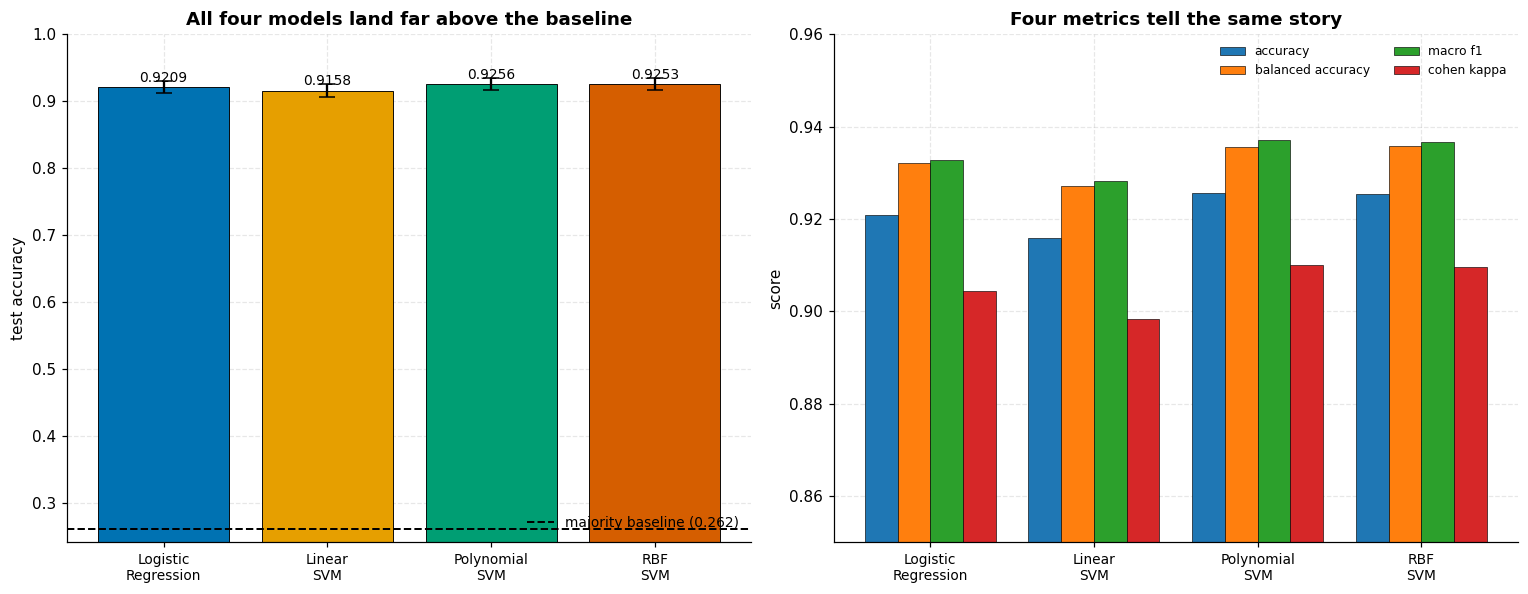

best on test accuracy : Polynomial SVM (0.9256)
spread across all four: 0.0097 (0.97 percentage points)
all four confidence intervals overlap: True


In [20]:
def accuracy_interval(accuracy: float, n: int) -> tuple[float, float]:
    """95% normal-approximation confidence interval for a proportion."""
    half_width = 1.96 * np.sqrt(accuracy * (1 - accuracy) / n)
    return accuracy - half_width, accuracy + half_width


test_rows, predictions = [], {}
for name, model in tuned_models.items():
    predicted = model.predict(X_test)
    predictions[name] = predicted
    accuracy = accuracy_score(y_test, predicted)
    low, high = accuracy_interval(accuracy, len(y_test))
    test_rows.append({
        "model": name,
        "accuracy": accuracy,
        "ci_low": low,
        "ci_high": high,
        "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
        "macro_f1": f1_score(y_test, predicted, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_test, predicted, average="weighted", zero_division=0),
        "cohen_kappa": cohen_kappa_score(y_test, predicted),
        "errors": int((predicted != y_test).sum()),
    })

test_frame = pd.DataFrame(test_rows).set_index("model")
display(test_frame.round(4))

fig, (ax_acc, ax_metrics) = plt.subplots(1, 2, figsize=(14, 5.5))

positions = np.arange(len(MODEL_NAMES))
accuracies = test_frame.loc[MODEL_NAMES, "accuracy"]
errors = np.array([
    accuracies - test_frame.loc[MODEL_NAMES, "ci_low"],
    test_frame.loc[MODEL_NAMES, "ci_high"] - accuracies,
])
ax_acc.bar(positions, accuracies, yerr=errors, capsize=5,
           color=[MODEL_COLORS[n] for n in MODEL_NAMES], edgecolor="black", linewidth=0.6)
ax_acc.axhline(baseline_frame["accuracy"].max(), color="black", linestyle="--", linewidth=1.3,
               label=f"majority baseline ({baseline_frame['accuracy'].max():.3f})")
ax_acc.set_xticks(positions)
ax_acc.set_xticklabels([n.replace(" ", "\n") for n in MODEL_NAMES], fontsize=9)
# A zoomed y-axis would exaggerate differences of a few tenths of a point, so
# the axis starts at the baseline to keep the comparison honest.
ax_acc.set_ylim(baseline_frame["accuracy"].max() - 0.02, 1.0)
ax_acc.set_ylabel("test accuracy")
ax_acc.set_title("All four models land far above the baseline")
ax_acc.legend(fontsize=9, loc="lower right")
for position, value in zip(positions, accuracies):
    ax_acc.text(position, value + 0.008, f"{value:.4f}", ha="center", fontsize=9)

metric_names = ["accuracy", "balanced_accuracy", "macro_f1", "cohen_kappa"]
width = 0.2
for offset, metric in zip(np.linspace(-1.5, 1.5, len(metric_names)) * width, metric_names):
    ax_metrics.bar(positions + offset, test_frame.loc[MODEL_NAMES, metric], width,
                   label=metric.replace("_", " "), edgecolor="black", linewidth=0.4)
ax_metrics.set_xticks(positions)
ax_metrics.set_xticklabels([n.replace(" ", "\n") for n in MODEL_NAMES], fontsize=9)
ax_metrics.set_ylim(0.85, 0.96)
ax_metrics.set_ylabel("score")
ax_metrics.set_title("Four metrics tell the same story")
ax_metrics.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()

best_model = test_frame["accuracy"].idxmax()
spread = test_frame["accuracy"].max() - test_frame["accuracy"].min()
print(f"best on test accuracy : {best_model} ({test_frame.loc[best_model, 'accuracy']:.4f})")
print(f"spread across all four: {spread:.4f} ({spread * 100:.2f} percentage points)")
print(f"all four confidence intervals overlap: "
      f"{bool(test_frame['ci_low'].max() < test_frame['ci_high'].min())}")

Note that **balanced accuracy is higher than plain accuracy** for every model. That is the opposite
of the usual worry about imbalanced data, and it happens because the rare class here is the *easy*
one: BOMBAY is large and distinctive, so averaging the per-class recalls equally rewards the model
for a class it gets almost perfectly right, while plain accuracy is dominated by the big, difficult
DERMASON/SIRA pair.

### 5.4 Where the errors are

The aggregate scores hide the structure of the mistakes. Each matrix below is **row-normalised**,
so each row shows how the beans of one true variety were distributed across predictions, and the
diagonal is that class's recall.

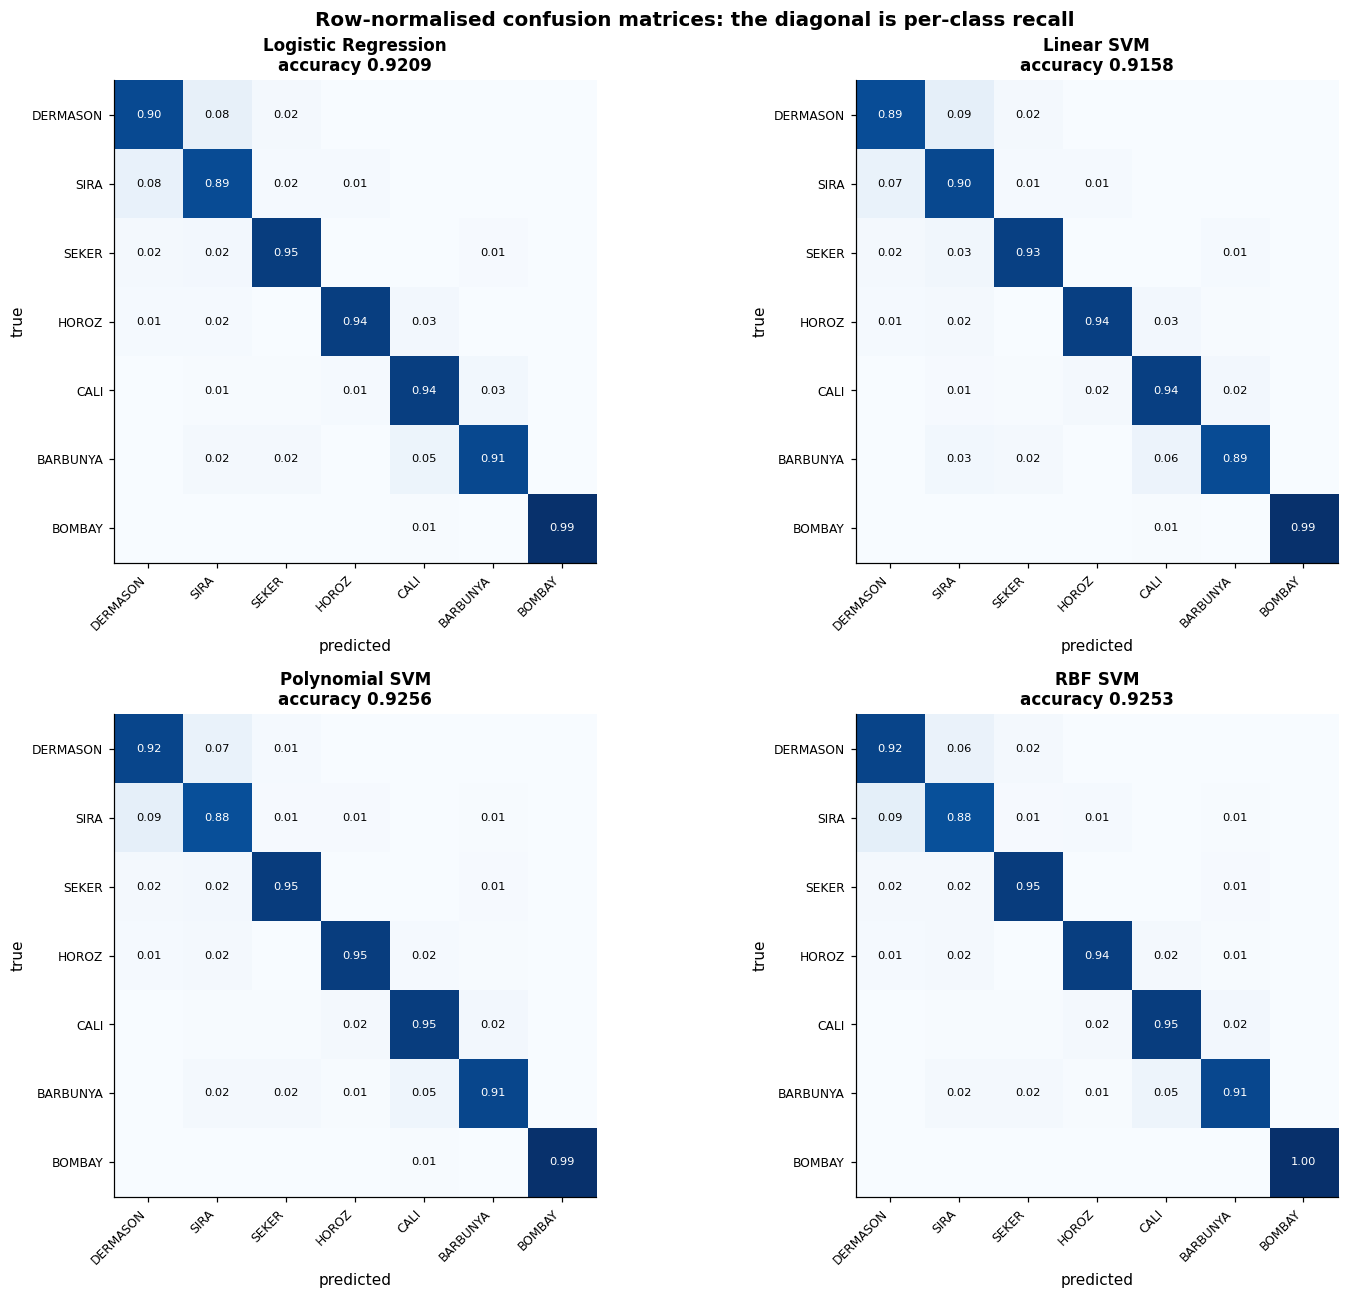

,Logistic Regression,Linear SVM,Polynomial SVM,RBF SVM,total,share_of_all_errors
DERMASON <-> SIRA,122,123,119,116,480,0.453686
CALI <-> BARBUNYA,30,29,25,26,110,0.103970
DERMASON <-> SEKER,25,30,21,23,99,0.093573
SIRA <-> SEKER,22,24,19,17,82,0.077505
HOROZ <-> CALI,18,20,14,15,67,0.063327
SIRA <-> HOROZ,16,18,16,17,67,0.063327
SEKER <-> BARBUNYA,12,14,10,11,47,0.044423
SIRA <-> BARBUNYA,8,12,10,10,40,0.037807


the single worst pair is DERMASON <-> SIRA, carrying 45.4% of all errors made by all four models


In [21]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, name in zip(axes.ravel(), MODEL_NAMES):
    matrix = confusion_matrix(y_test, predictions[name], labels=CLASS_ORDER, normalize="true")
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASS_ORDER)))
    ax.set_xticklabels(CLASS_ORDER, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(CLASS_ORDER)))
    ax.set_yticklabels(CLASS_ORDER, fontsize=8)
    for i in range(len(CLASS_ORDER)):
        for j in range(len(CLASS_ORDER)):
            if matrix[i, j] >= 0.005:
                ax.text(j, i, f"{matrix[i, j]:.2f}", ha="center", va="center", fontsize=7.5,
                        color="white" if matrix[i, j] > 0.5 else "black")
    ax.set_title(f"{name}\naccuracy {test_frame.loc[name, 'accuracy']:.4f}", fontsize=11)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.grid(False)

fig.suptitle("Row-normalised confusion matrices: the diagonal is per-class recall",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

# Aggregate the off-diagonal mass by unordered class pair.
pair_errors = {}
for name in MODEL_NAMES:
    matrix = confusion_matrix(y_test, predictions[name], labels=CLASS_ORDER)
    for i, first in enumerate(CLASS_ORDER):
        for j, second in enumerate(CLASS_ORDER):
            if i < j:
                key = f"{first} <-> {second}"
                pair_errors.setdefault(key, {})[name] = int(matrix[i, j] + matrix[j, i])

confusion_frame = pd.DataFrame(pair_errors).T
confusion_frame["total"] = confusion_frame.sum(axis=1)
confusion_frame = confusion_frame.sort_values("total", ascending=False)
confusion_frame["share_of_all_errors"] = confusion_frame["total"] / confusion_frame["total"].sum()
display(confusion_frame.head(8))

worst_pair = confusion_frame.index[0]
print(f"the single worst pair is {worst_pair}, carrying "
      f"{confusion_frame.loc[worst_pair, 'share_of_all_errors']:.1%} of all errors made by all four models")

,Logistic Regression,Linear SVM,Polynomial SVM,RBF SVM,test_n
DERMASON,0.9126,0.9085,0.9177,0.9185,887
SIRA,0.8722,0.8680,0.8737,0.8758,659
SEKER,0.9393,0.9312,0.9479,0.9470,507
HOROZ,0.9554,0.9499,0.9565,0.9533,465
CALI,0.9322,0.9320,0.9428,0.9416,408
BARBUNYA,0.9214,0.9116,0.9247,0.9202,330
BOMBAY,0.9961,0.9961,0.9961,1.0000,130


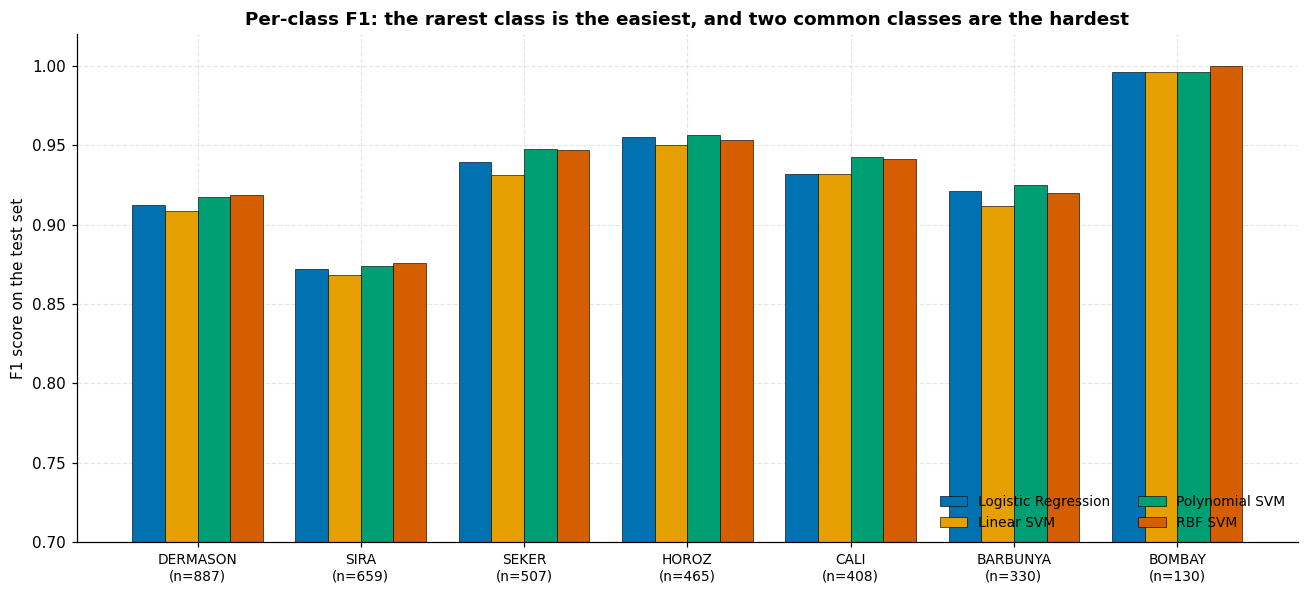

per-class F1 averaged over the four models, best to worst:
BOMBAY      0.9971
HOROZ       0.9538
SEKER       0.9414
CALI        0.9372
BARBUNYA    0.9195
DERMASON    0.9143
SIRA        0.8724


In [22]:
per_class = pd.DataFrame({
    name: f1_score(y_test, predictions[name], labels=CLASS_ORDER, average=None, zero_division=0)
    for name in MODEL_NAMES
}, index=CLASS_ORDER)
per_class["test_n"] = [int((y_test == c).sum()) for c in CLASS_ORDER]
display(per_class.round(4))

fig, ax = plt.subplots(figsize=(12, 5.5))
positions = np.arange(len(CLASS_ORDER))
width = 0.2
for offset, name in zip(np.linspace(-1.5, 1.5, len(MODEL_NAMES)) * width, MODEL_NAMES):
    ax.bar(positions + offset, per_class[name], width, label=name,
           color=MODEL_COLORS[name], edgecolor="black", linewidth=0.4)
ax.set_xticks(positions)
ax.set_xticklabels([f"{c}\n(n={int(per_class.loc[c, 'test_n'])})" for c in CLASS_ORDER], fontsize=9)
ax.set_ylabel("F1 score on the test set")
ax.set_ylim(0.7, 1.02)
ax.set_title("Per-class F1: the rarest class is the easiest, and two common classes are the hardest")
ax.legend(fontsize=9, ncol=2, loc="lower right")
fig.tight_layout()
plt.show()

print("per-class F1 averaged over the four models, best to worst:")
print(per_class[MODEL_NAMES].mean(axis=1).sort_values(ascending=False).round(4).to_string())

### 5.5 Are the differences real?

Comparing single test scores is not enough: a gap of a few tenths of a point could easily be noise.
Each tuned model is therefore scored on the **same** repeated stratified cross-validation folds
(5 folds x 3 repeats = 15 scores each), which allows a **paired** comparison on identical data.

Two honest caveats are attached to the p-values:

1. **CV folds are not independent**, the training sets overlap heavily between folds, so the
   paired t-test's independence assumption is violated and these p-values are optimistic. They
   indicate consistency, not a rigorous significance level.
2. **Six pairwise comparisons** are made, so the significance threshold is corrected with Holm's
   method to control the family-wise error rate.

Logistic Regression   0.9257 +/- 0.0073  (n=15 folds)


Linear SVM            0.9223 +/- 0.0080  (n=15 folds)


Polynomial SVM        0.9320 +/- 0.0058  (n=15 folds)


RBF SVM               0.9324 +/- 0.0062  (n=15 folds)


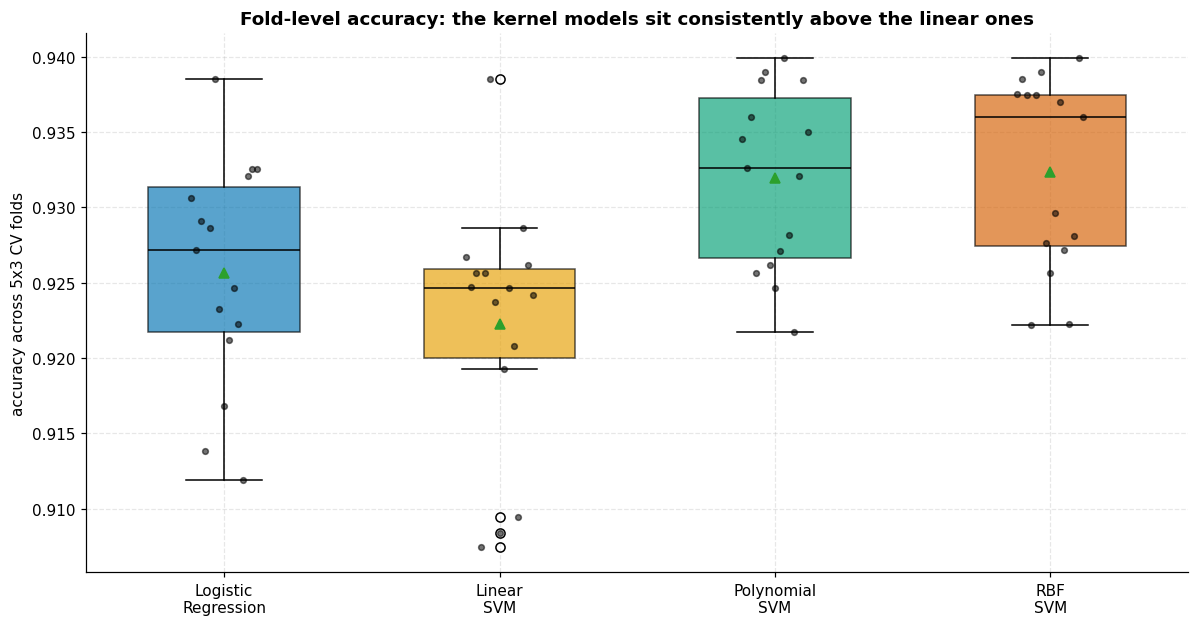

In [23]:
repeated_cv = RepeatedStratifiedKFold(n_splits=CV_FOLDS, n_repeats=CV_REPEATS,
                                      random_state=RANDOM_STATE)
fold_scores = {}
for name, model in tuned_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=repeated_cv,
                             scoring="accuracy", n_jobs=N_JOBS)
    fold_scores[name] = scores
    print(f"{name:21s} {scores.mean():.4f} +/- {scores.std():.4f}  (n={len(scores)} folds)")

fold_frame = pd.DataFrame(fold_scores)

fig, ax = plt.subplots(figsize=(11, 5.8))
parts = ax.boxplot([fold_frame[n] for n in MODEL_NAMES], tick_labels=[n.replace(" ", "\n") for n in MODEL_NAMES],
                   patch_artist=True, widths=0.55, showmeans=True)
for patch, name in zip(parts["boxes"], MODEL_NAMES):
    patch.set_facecolor(MODEL_COLORS[name])
    patch.set_alpha(0.65)
for median in parts["medians"]:
    median.set_color("black")
# Overlay the individual folds so the reader sees the actual spread, not just a summary.
for position, name in enumerate(MODEL_NAMES, start=1):
    jitter = np.linspace(-0.12, 0.12, len(fold_frame))
    ax.scatter(position + jitter, fold_frame[name], s=14, color="black", alpha=0.55, zorder=3)
ax.set_ylabel(f"accuracy across {CV_FOLDS}x{CV_REPEATS} CV folds")
ax.set_title("Fold-level accuracy: the kernel models sit consistently above the linear ones")
fig.tight_layout()
plt.show()

In [24]:
def holm_correct(pvalues: list[float]) -> list[float]:
    """Holm step-down adjustment, controlling the family-wise error rate."""
    order = np.argsort(pvalues)
    adjusted = np.empty(len(pvalues))
    running = 0.0
    for rank, index in enumerate(order):
        value = (len(pvalues) - rank) * pvalues[index]
        running = max(running, value)        # enforce monotonicity
        adjusted[index] = min(1.0, running)
    return adjusted.tolist()


comparison_rows = []
for i, first in enumerate(MODEL_NAMES):
    for second in MODEL_NAMES[i + 1:]:
        differences = fold_frame[second] - fold_frame[first]
        t_statistic, t_p = stats.ttest_rel(fold_frame[second], fold_frame[first])
        wilcoxon_p = stats.wilcoxon(fold_frame[second], fold_frame[first]).pvalue
        comparison_rows.append({
            "comparison": f"{second} - {first}",
            "mean_difference": differences.mean(),
            "sd": differences.std(),
            "wins": int((differences > 0).sum()),
            "losses": int((differences < 0).sum()),
            "ttest_p": t_p,
            "wilcoxon_p": wilcoxon_p,
        })

comparisons = pd.DataFrame(comparison_rows)
comparisons["ttest_p_holm"] = holm_correct(comparisons["ttest_p"].tolist())
comparisons["wilcoxon_p_holm"] = holm_correct(comparisons["wilcoxon_p"].tolist())
comparisons["significant_at_5pct"] = comparisons["wilcoxon_p_holm"] < 0.05
display(comparisons.set_index("comparison").round(5))

print("\nreading of the table:")
for _, row in comparisons.iterrows():
    verdict = "significant" if row["significant_at_5pct"] else "NOT significant"
    print(f"  {row['comparison']:46s} {row['mean_difference']:+.4f}  {verdict}")

,mean_difference,sd,wins,losses,ttest_p,wilcoxon_p,ttest_p_holm,wilcoxon_p_holm,significant_at_5pct
comparison,,,,,,,,,
Linear SVM - Logistic Regression,-0.00341,0.00285,1,12,0.00038,0.00185,0.00077,0.00491,True
Polynomial SVM - Logistic Regression,0.00630,0.00418,14,0,0.00004,0.00098,0.00013,0.00491,True
RBF SVM - Logistic Regression,0.00669,0.00427,14,1,0.00003,0.00120,0.00011,0.00491,True
Polynomial SVM - Linear SVM,0.00971,0.00509,15,0,0.00000,0.00065,0.00002,0.00392,True
RBF SVM - Linear SVM,0.01011,0.00519,14,1,0.00000,0.00098,0.00002,0.00491,True
RBF SVM - Polynomial SVM,0.00039,0.00259,9,5,0.56596,0.48964,0.56596,0.48964,False



reading of the table:
  Linear SVM - Logistic Regression               -0.0034  significant
  Polynomial SVM - Logistic Regression           +0.0063  significant
  RBF SVM - Logistic Regression                  +0.0067  significant
  Polynomial SVM - Linear SVM                    +0.0097  significant
  RBF SVM - Linear SVM                           +0.0101  significant
  RBF SVM - Polynomial SVM                       +0.0004  NOT significant


### 5.6 Answer to the question

**Can logistic regression or a linear SVM predict well?** Yes, and the qualification matters.

- **Both linear models predict well in absolute terms.** They reach roughly 92% accuracy against a
  26% baseline, with Cohen's kappa around 0.90, so about nine tenths of the agreement that
  remains after accounting for chance. For a seven-class problem from 16 cheap measurements, that
  is a strong result, and it means the varieties are *very nearly* linearly separable.
- **The kernel SVMs are better, consistently but slightly.** The paired comparisons show the RBF
  and polynomial SVMs beating both linear models on nearly every fold, and the difference survives
  the Holm correction. The gap is real, but it is under one percentage point.
- **The two kernel SVMs are statistically indistinguishable from each other.** Their comparison is
  the one that fails to reach significance, which is taken up in Section 8.
- **The errors are concentrated, not spread out.** DERMASON versus SIRA alone accounts for a little
  under half of every model's mistakes. Those two varieties genuinely overlap in these 16
  measurements, which caps every model here at around 92-93%. Getting past that ceiling would need
  better *features*, colour, texture, mass, not a better classifier.
- **Choosing between them is therefore not purely an accuracy question.** A fraction of a point
  favours the RBF SVM; interpretability, model size and prediction speed all favour logistic
  regression. Sections 7 and 10 quantify that trade-off.

---
## 6. Plots of selected pairs of variables, and where the decision boundary falls

**Project question 3.**

> **An important caveat, stated up front.** Every model in this section is trained on **only the two
> features being plotted**. That is the one honest way to draw a decision boundary in two
> dimensions: the line you see is then genuinely the boundary that model learned. The common
> alternative, training on all 16 features and slicing the surface at the median of the other 14, > produces a picture that is not the model's boundary anywhere in particular, because moving along
> the unplotted dimensions moves the boundary too.
>
> The cost of doing it properly is that these two-feature models are **weaker than the real
> models** from Section 5. Their accuracies are reported in each panel title so the gap is visible,
> and the full 16-feature accuracy is printed alongside for comparison.

In [25]:
# Three pairs spanning the range of behaviour seen in Section 3:
#   - a pair where the varieties separate cleanly,
#   - a pair of one size and one shape feature, which curve differently,
#   - a pair chosen because the classes overlap almost completely.
BOUNDARY_PAIRS = [
    ("MajorAxisLength", "ShapeFactor1"),
    ("Perimeter", "Compactness"),
    ("Extent", "Solidity"),
]

# The 2-D models are fitted on a seeded subsample, and the mesh is kept at
# 200x200. Both bounds exist because an RBF SVM must evaluate its kernel at
# every mesh point against every support vector, which is the slow step here.
BOUNDARY_TRAIN_N = 3000
MESH_STEPS = 200

boundary_rng = np.random.default_rng(RANDOM_STATE)
subsample_index = boundary_rng.choice(len(X_train), size=BOUNDARY_TRAIN_N, replace=False)
X_boundary = X_train.iloc[subsample_index]
y_boundary = y_train.iloc[subsample_index]

print(f"2-D models trained on a seeded subsample of {BOUNDARY_TRAIN_N:,} of {len(X_train):,} "
      f"training rows, with a {MESH_STEPS}x{MESH_STEPS} mesh")
print("(both limits are for runtime; the 16-feature models in Section 5 used the full training set)")

# For reference: what the same four models achieve with all 16 features.
full_reference = {name: test_frame.loc[name, "accuracy"] for name in MODEL_NAMES}
print("\nfull 16-feature test accuracy, for comparison:")
for name, value in full_reference.items():
    print(f"  {name:21s} {value:.4f}")

2-D models trained on a seeded subsample of 3,000 of 10,157 training rows, with a 200x200 mesh
(both limits are for runtime; the 16-feature models in Section 5 used the full training set)

full 16-feature test accuracy, for comparison:
  Logistic Regression   0.9209
  Linear SVM            0.9158
  Polynomial SVM        0.9256
  RBF SVM               0.9253


row 1: MajorAxisLength vs ShapeFactor1 done


row 2: Perimeter vs Compactness done


row 3: Extent vs Solidity done


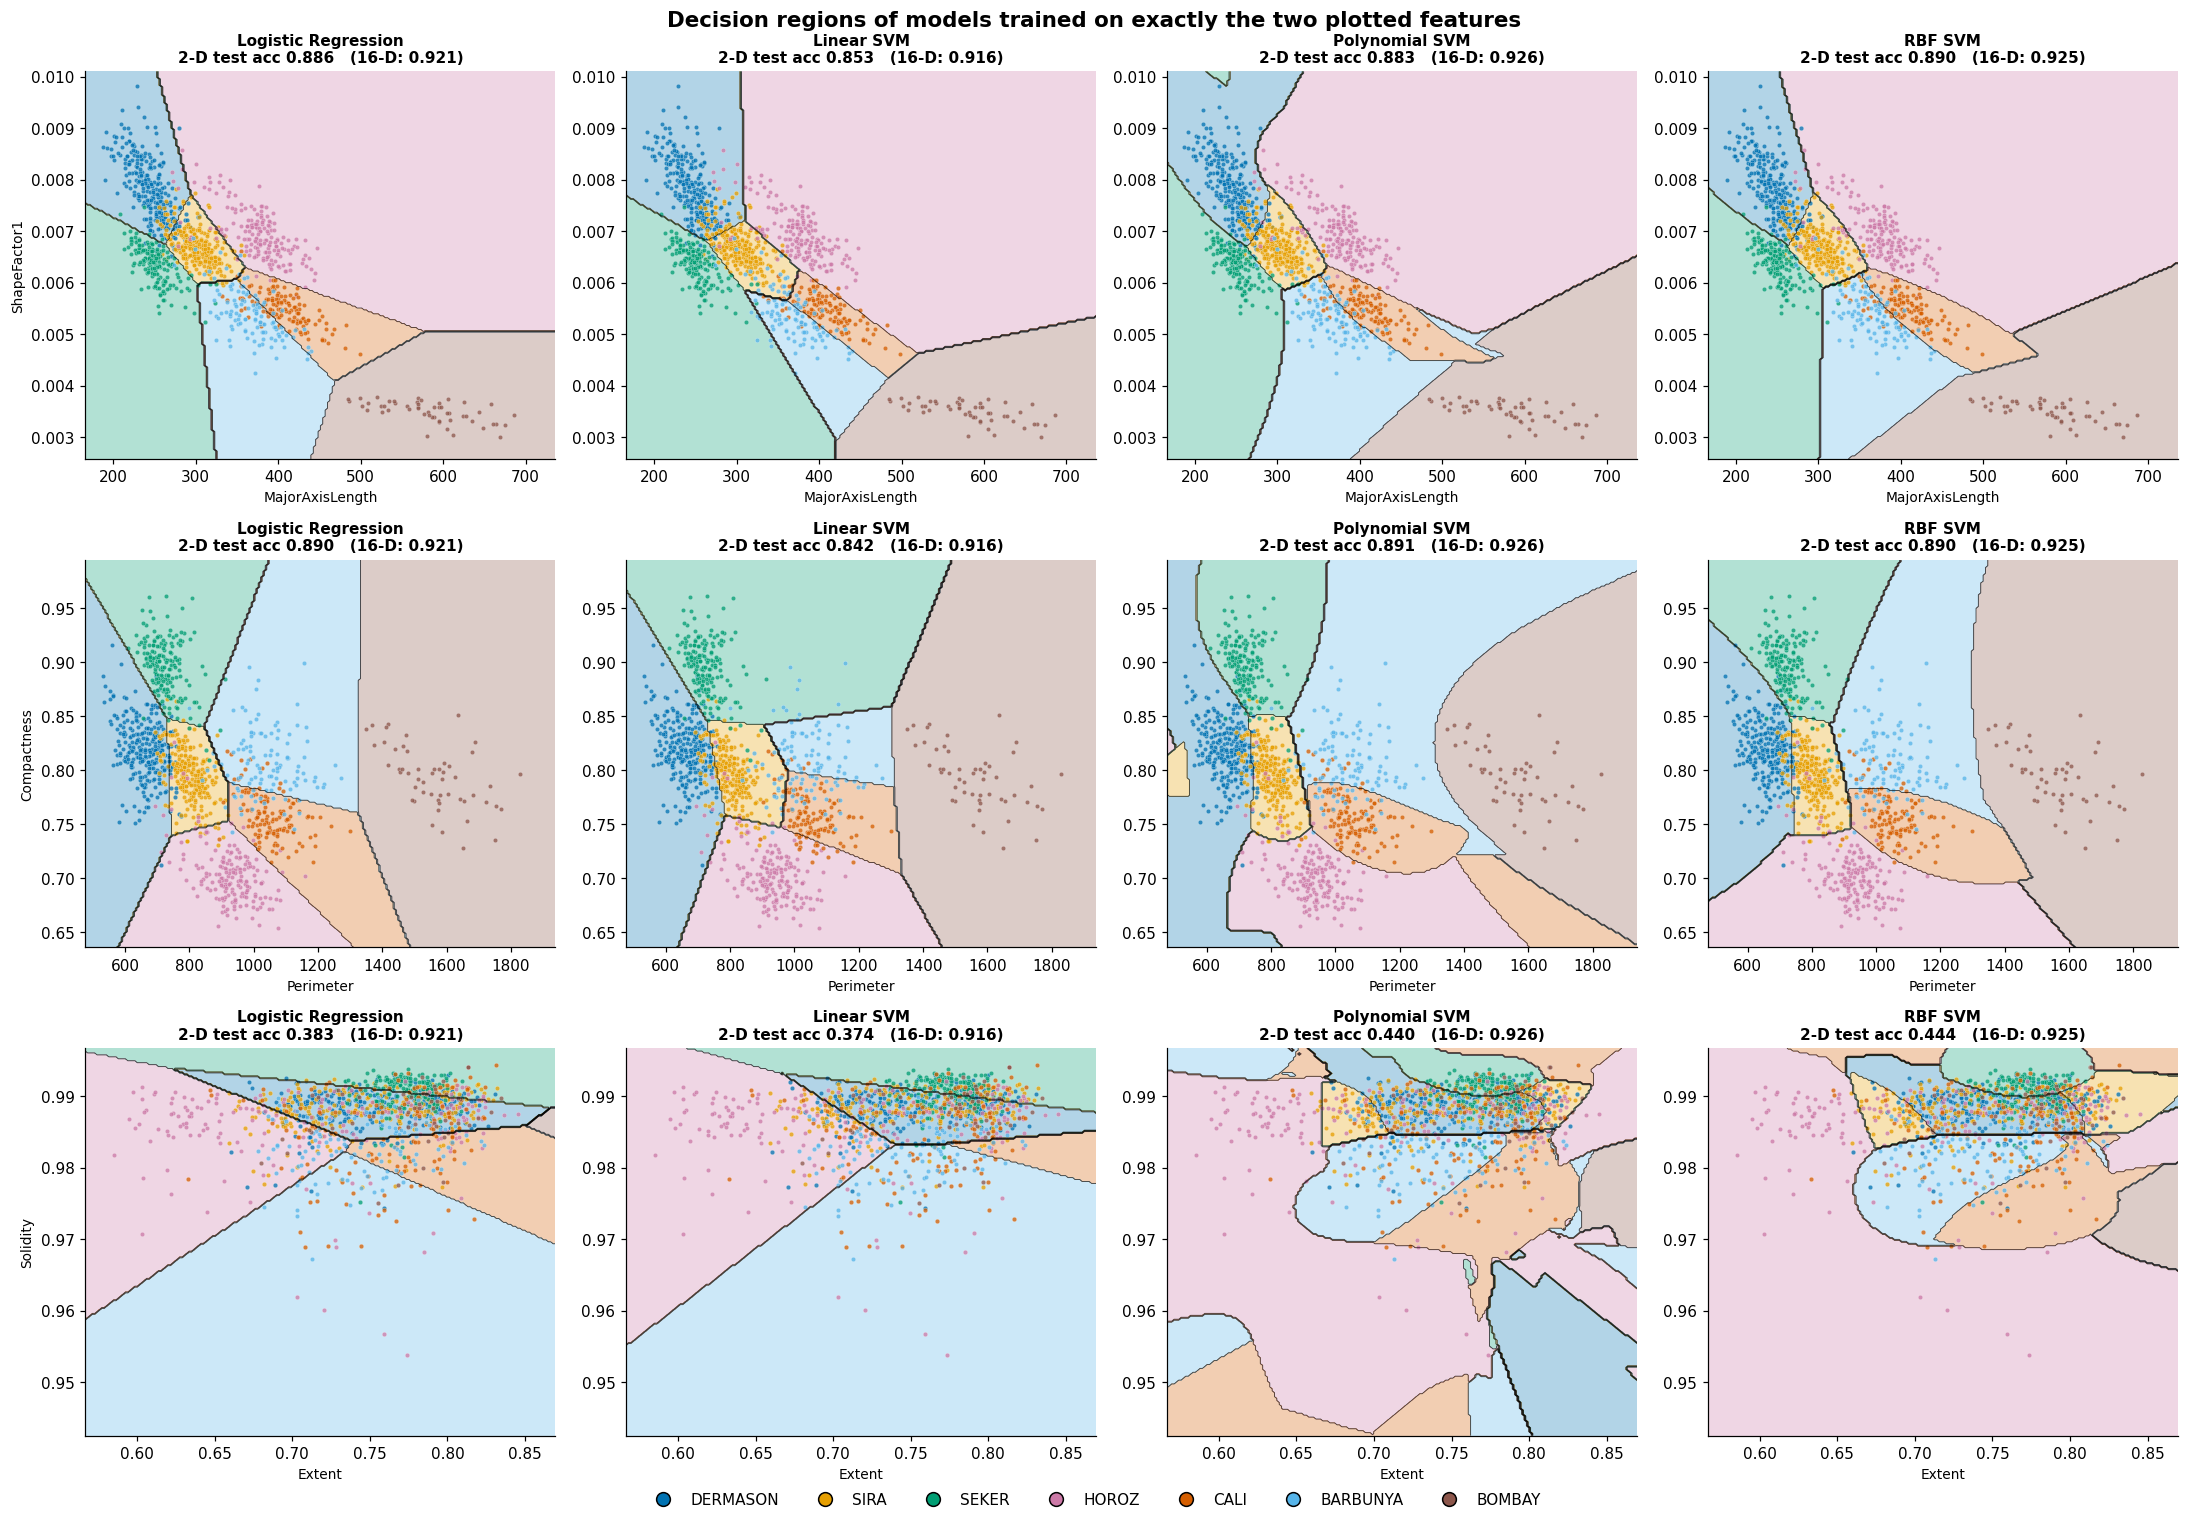

In [26]:
def fit_pair_models(x_feature: str, y_feature: str) -> dict:
    """Fit all four models on just these two features, returning model and scores."""
    columns = [x_feature, y_feature]
    fitted = {}
    for name in MODEL_NAMES:
        model = base_estimator(name).set_params(**best_params[name])
        model.fit(X_boundary[columns], y_boundary)
        fitted[name] = {
            "model": model,
            "train_accuracy": model.score(X_boundary[columns], y_boundary),
            "test_accuracy": model.score(X_test[columns], y_test),
        }
    return fitted


def plot_regions(ax, model, x_feature: str, y_feature: str, scatter_n: int = 1200) -> None:
    """Fill the decision regions and overlay a sample of the training points."""
    columns = [x_feature, y_feature]
    x_values = X_boundary[x_feature]
    y_values = X_boundary[y_feature]
    x_pad = 0.04 * (x_values.max() - x_values.min())
    y_pad = 0.04 * (y_values.max() - y_values.min())

    # The mesh is built in the ORIGINAL feature units and handed to the
    # pipeline, which standardises it exactly as it did the training data.
    # That keeps the axis ticks interpretable as real measurements.
    grid_x, grid_y = np.meshgrid(
        np.linspace(x_values.min() - x_pad, x_values.max() + x_pad, MESH_STEPS),
        np.linspace(y_values.min() - y_pad, y_values.max() + y_pad, MESH_STEPS),
    )
    mesh = pd.DataFrame({x_feature: grid_x.ravel(), y_feature: grid_y.ravel()})
    predicted = model.predict(mesh)

    # Map class names onto the fixed CLASS_ORDER indices so the region colours
    # match the scatter colours and every other figure in the notebook.
    code_of = {cls: i for i, cls in enumerate(CLASS_ORDER)}
    region = np.array([code_of[p] for p in predicted]).reshape(grid_x.shape)

    colormap = mpl.colors.ListedColormap([CLASS_COLORS[c] for c in CLASS_ORDER])
    ax.contourf(grid_x, grid_y, region, levels=np.arange(-0.5, len(CLASS_ORDER) + 0.5),
                cmap=colormap, alpha=0.3)
    ax.contour(grid_x, grid_y, region, levels=np.arange(-0.5, len(CLASS_ORDER) + 0.5),
               colors="black", linewidths=0.6, alpha=0.65)

    shown = X_boundary.sample(n=min(scatter_n, len(X_boundary)), random_state=RANDOM_STATE)
    for cls in CLASS_ORDER:
        mask = (y_boundary.loc[shown.index] == cls).to_numpy()
        if mask.any():
            ax.scatter(shown[x_feature][mask], shown[y_feature][mask], s=9, alpha=0.75,
                       color=CLASS_COLORS[cls], edgecolor="white", linewidth=0.2, label=cls)
    ax.set_xlim(grid_x.min(), grid_x.max())
    ax.set_ylim(grid_y.min(), grid_y.max())


pair_models = {}
fig, axes = plt.subplots(len(BOUNDARY_PAIRS), len(MODEL_NAMES),
                         figsize=(5 * len(MODEL_NAMES), 4.6 * len(BOUNDARY_PAIRS)))
for row, (x_feature, y_feature) in enumerate(BOUNDARY_PAIRS):
    fitted = fit_pair_models(x_feature, y_feature)
    pair_models[(x_feature, y_feature)] = fitted
    for column, name in enumerate(MODEL_NAMES):
        ax = axes[row, column]
        plot_regions(ax, fitted[name]["model"], x_feature, y_feature)
        ax.set_title(f"{name}\n2-D test acc {fitted[name]['test_accuracy']:.3f}"
                     f"   (16-D: {full_reference[name]:.3f})", fontsize=10)
        ax.set_xlabel(x_feature, fontsize=9)
        if column == 0:
            ax.set_ylabel(y_feature, fontsize=9)
        else:
            ax.set_ylabel("")
        ax.grid(False)
    print(f"row {row + 1}: {x_feature} vs {y_feature} done")

handles = [plt.Line2D([], [], marker="o", color="w", markerfacecolor=CLASS_COLORS[c],
                      markersize=9, markeredgecolor="black", label=c) for c in CLASS_ORDER]
fig.legend(handles=handles, loc="lower center", ncol=7, fontsize=10, bbox_to_anchor=(0.5, -0.015))
fig.suptitle("Decision regions of models trained on exactly the two plotted features",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

In [27]:
pair_summary = pd.DataFrame([
    {
        "pair": f"{x} vs {y}",
        "model": name,
        "train_accuracy": info[name]["train_accuracy"],
        "test_accuracy": info[name]["test_accuracy"],
        "full_16d_test": full_reference[name],
        "lost_by_using_2_features": full_reference[name] - info[name]["test_accuracy"],
    }
    for (x, y), info in pair_models.items() for name in MODEL_NAMES
])
display(pair_summary.pivot_table(index="pair", columns="model", values="test_accuracy").round(4))

best_pair = pair_summary.groupby("pair")["test_accuracy"].max().idxmax()
worst_pair_2d = pair_summary.groupby("pair")["test_accuracy"].max().idxmin()
print(f"best two-feature pair : {best_pair} "
      f"({pair_summary.groupby('pair')['test_accuracy'].max().max():.4f})")
print(f"worst two-feature pair: {worst_pair_2d} "
      f"({pair_summary.groupby('pair')['test_accuracy'].max().min():.4f})")
print(f"\nwithin a pair, the gap between the best and worst of the four models is at most "
      f"{pair_summary.groupby('pair')['test_accuracy'].agg(lambda s: s.max() - s.min()).max():.4f}")

model,Linear SVM,Logistic Regression,Polynomial SVM,RBF SVM
pair,,,,
Extent vs Solidity,0.3742,0.3828,0.4398,0.4436
MajorAxisLength vs ShapeFactor1,0.8526,0.8863,0.8830,0.8895
Perimeter vs Compactness,0.8423,0.8904,0.8907,0.8895


best two-feature pair : Perimeter vs Compactness (0.8907)
worst two-feature pair: Extent vs Solidity (0.4436)

within a pair, the gap between the best and worst of the four models is at most 0.0694


Reading the rows of that figure:

- **`MajorAxisLength` vs `ShapeFactor1`** is the informative plane. The varieties form diagonal
  bands, and all four models carve them into broadly similar strips. BOMBAY occupies its own
  corner, cleanly fenced off by every model.
- **`Perimeter` vs `Compactness`** shows the clearest *difference between models*. The two linear
  models can only lay down straight cuts, so they must approximate a curved class boundary with a
  polygon; the RBF SVM bends its boundary to follow it.
- **`Extent` vs `Solidity`** is the control case. The classes are piled on top of one another, and
  accuracy falls to roughly 0.37-0.44, still above the 0.262 majority baseline, so these two
  features are not quite worthless, but less than half of what the better pairs achieve. The
  panels show large regions assigned to the big classes with only crude structure between them. No
  decision boundary can rescue features that barely separate the classes, which is the visual
  counterpart of the ranking in Section 4.

Comparing panel titles with the 16-feature figures in brackets shows what two features cost: a
substantial drop, confirming that the real work in this problem is done by *combinations* of
measurements rather than by any single pair.

### 6.2 Where exactly is the boundary? A binary close-up

The multi-class panels show regions but not *margins*. Reducing to the two genuinely confusable
varieties, DERMASON and SIRA, which Section 5.4 showed carry 45% of all errors, makes the
mechanics visible: the decision line, the two margin lines at `decision_function = +/-1`, and the
support vectors that define them.

`SVC(kernel="linear")` is used here rather than `LinearSVC` for one specific reason: `LinearSVC`
solves the primal problem and does not expose `support_vectors_`, so the support vectors could not
be drawn.

training points in the two classes : 1,351
support vectors                    : 277 (20.5% of them)
per class                          : {'DERMASON': np.int32(139), 'SIRA': np.int32(138)}
binary test accuracy on this pair  : 0.9036


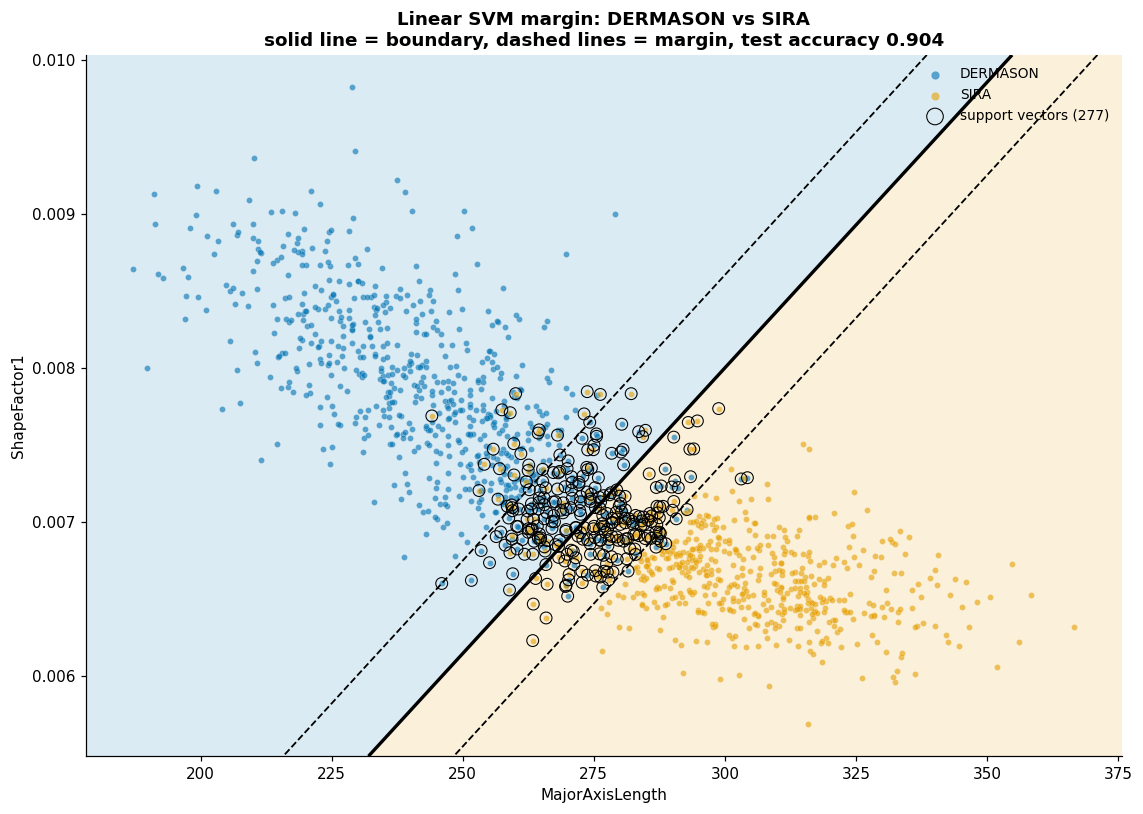

In [28]:
CLOSEUP_CLASSES = ["DERMASON", "SIRA"]
CLOSEUP_PAIR = ("MajorAxisLength", "ShapeFactor1")

binary_mask = y_boundary.isin(CLOSEUP_CLASSES).to_numpy()
X_binary = X_boundary.loc[binary_mask, list(CLOSEUP_PAIR)]
y_binary = y_boundary.loc[binary_mask]

binary_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", SVC(kernel="linear", C=1.0, random_state=RANDOM_STATE)),
]).fit(X_binary, y_binary)

test_binary_mask = y_test.isin(CLOSEUP_CLASSES).to_numpy()
binary_test_accuracy = binary_svm.score(
    X_test.loc[test_binary_mask, list(CLOSEUP_PAIR)], y_test[test_binary_mask]
)

support_count = int(binary_svm.named_steps["clf"].n_support_.sum())
print(f"training points in the two classes : {len(X_binary):,}")
print(f"support vectors                    : {support_count:,} "
      f"({support_count / len(X_binary):.1%} of them)")
print(f"per class                          : {dict(zip(binary_svm.named_steps['clf'].classes_, binary_svm.named_steps['clf'].n_support_))}")
print(f"binary test accuracy on this pair  : {binary_test_accuracy:.4f}")

fig, ax = plt.subplots(figsize=(10.5, 7.5))

x_values, y_values = X_binary[CLOSEUP_PAIR[0]], X_binary[CLOSEUP_PAIR[1]]
x_pad = 0.05 * (x_values.max() - x_values.min())
y_pad = 0.05 * (y_values.max() - y_values.min())
grid_x, grid_y = np.meshgrid(
    np.linspace(x_values.min() - x_pad, x_values.max() + x_pad, 300),
    np.linspace(y_values.min() - y_pad, y_values.max() + y_pad, 300),
)
mesh = pd.DataFrame({CLOSEUP_PAIR[0]: grid_x.ravel(), CLOSEUP_PAIR[1]: grid_y.ravel()})
distance = binary_svm.decision_function(mesh).reshape(grid_x.shape)

ax.contourf(grid_x, grid_y, distance, levels=[-1e9, 0, 1e9],
            colors=[CLASS_COLORS[CLOSEUP_CLASSES[0]], CLASS_COLORS[CLOSEUP_CLASSES[1]]], alpha=0.14)
# The decision boundary, plus the two margin lines one unit either side of it.
ax.contour(grid_x, grid_y, distance, levels=[0], colors="black", linewidths=2.2)
ax.contour(grid_x, grid_y, distance, levels=[-1, 1], colors="black",
           linewidths=1.2, linestyles="--")

for cls in CLOSEUP_CLASSES:
    mask = (y_binary == cls).to_numpy()
    ax.scatter(x_values[mask], y_values[mask], s=16, alpha=0.6, color=CLASS_COLORS[cls],
               edgecolor="white", linewidth=0.2, label=cls)

# Ring the support vectors: these are the only points that define the boundary.
support = binary_svm.named_steps["clf"].support_
ax.scatter(x_values.iloc[support], y_values.iloc[support], s=60, facecolors="none",
           edgecolors="black", linewidths=0.7, label=f"support vectors ({support_count:,})")

ax.set_xlabel(CLOSEUP_PAIR[0])
ax.set_ylabel(CLOSEUP_PAIR[1])
ax.set_title(f"Linear SVM margin: {CLOSEUP_CLASSES[0]} vs {CLOSEUP_CLASSES[1]}\n"
             f"solid line = boundary, dashed lines = margin, test accuracy {binary_test_accuracy:.3f}")
ax.legend(fontsize=9, loc="upper right", markerscale=1.4)
ax.grid(False)
fig.tight_layout()
plt.show()

The informative number here is **how many points are support vectors**: about one training point
in five sits on or inside the margin. In a cleanly separable problem only a handful of points would
qualify, so a fifth is a lot, it is the formal statement of what the scatter plot shows. These two
varieties interpenetrate in this plane, and the boundary is pinned down by a wide band of difficult
points rather than by a few extremes. The support-vector fraction is therefore a direct,
quantitative measure of class overlap, and, as Section 10 shows, it is also what makes kernel SVMs
slow to predict.

### 6.3 How the hyper-parameter changes the boundary's shape

`gamma` sets the radius of influence of each training point in an RBF kernel. Sweeping it from very
small to very large walks the model from underfitting to memorising, and the shape of the boundary
makes that visible in a way a single accuracy number does not. Train and test accuracy are printed
on each panel so the overfitting is legible as numbers too.

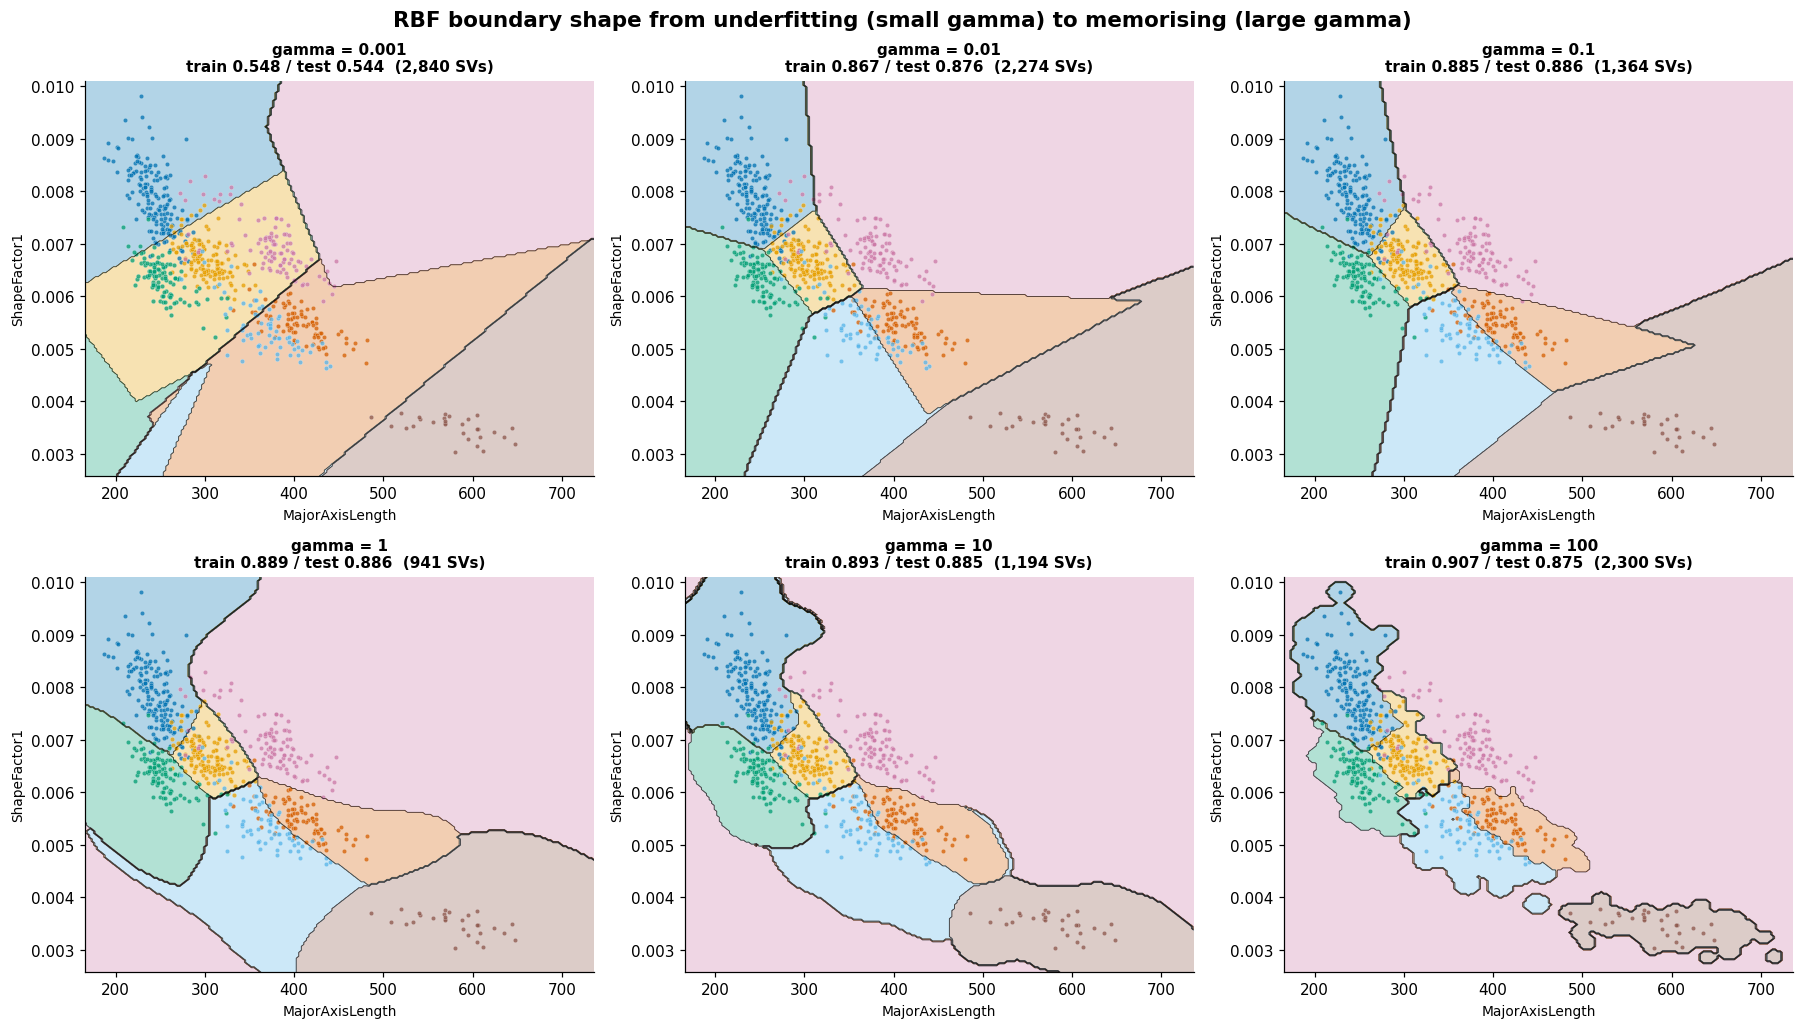

,train_accuracy,test_accuracy,gap,support_vectors
gamma,,,,
0.001,0.5483,0.5440,0.0043,2840
0.010,0.8673,0.8760,-0.0086,2274
0.100,0.8847,0.8860,-0.0013,1364
1.000,0.8890,0.8860,0.0030,941
10.000,0.8930,0.8845,0.0085,1194
100.000,0.9070,0.8748,0.0322,2300


best test accuracy at gamma = 0.1 (0.8860)
at gamma = 100: train 0.9070 but test 0.8748  -> gap 0.0322


In [29]:
GAMMA_VALUES = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
SWEEP_PAIR = ("MajorAxisLength", "ShapeFactor1")

sweep_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16.5, 9.5))
for ax, gamma in zip(axes.ravel(), GAMMA_VALUES):
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=1.0, gamma=gamma, cache_size=500, random_state=RANDOM_STATE)),
    ]).fit(X_boundary[list(SWEEP_PAIR)], y_boundary)

    train_accuracy = model.score(X_boundary[list(SWEEP_PAIR)], y_boundary)
    test_accuracy = model.score(X_test[list(SWEEP_PAIR)], y_test)
    n_support = int(model.named_steps["clf"].n_support_.sum())
    sweep_rows.append({"gamma": gamma, "train_accuracy": train_accuracy,
                       "test_accuracy": test_accuracy, "gap": train_accuracy - test_accuracy,
                       "support_vectors": n_support})

    plot_regions(ax, model, *SWEEP_PAIR, scatter_n=700)
    ax.set_title(f"gamma = {gamma:g}\ntrain {train_accuracy:.3f} / test {test_accuracy:.3f}"
                 f"  ({n_support:,} SVs)", fontsize=10)
    ax.set_xlabel(SWEEP_PAIR[0], fontsize=9)
    ax.set_ylabel(SWEEP_PAIR[1], fontsize=9)
    ax.grid(False)

fig.suptitle("RBF boundary shape from underfitting (small gamma) to memorising (large gamma)",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

sweep = pd.DataFrame(sweep_rows).set_index("gamma")
display(sweep.round(4))
best_gamma = sweep["test_accuracy"].idxmax()
print(f"best test accuracy at gamma = {best_gamma:g} ({sweep.loc[best_gamma, 'test_accuracy']:.4f})")
print(f"at gamma = {sweep.index[-1]:g}: train {sweep.iloc[-1]['train_accuracy']:.4f} "
      f"but test {sweep.iloc[-1]['test_accuracy']:.4f}  -> gap {sweep.iloc[-1]['gap']:.4f}")

### 6.4 Answer to the question

**What do the plots look like, and where is the boundary?**

- **In a good pair the classes form diagonal bands**, and all four models cut them in similar
  places. The boundary sits where the bands meet, and the models differ only in whether they can
  curve.
- **The models differ most where the true boundary is curved.** Logistic regression and the linear
  SVM must approximate a curve with straight segments; the kernel SVMs follow it. This is the
  visual explanation of the small but consistent accuracy advantage measured in Section 5.
- **In a bad pair there is no useful boundary to find**, and every model degenerates to predicting
  the majority class over almost the whole plane.
- **The margin is wide and crowded for the hard pair.** A large fraction of DERMASON and SIRA
  training points are support vectors, which quantifies their overlap and explains why this one
  pair dominates the error budget.
- **`gamma` controls boundary shape directly.** Small values give an almost linear boundary that
  badly underfits; large values give disconnected islands drawn around individual training points,
  with training accuracy climbing while test accuracy falls. The best value sits in between, the
  bias-variance trade-off of Section 7, seen as geometry.
- **The support-vector count is U-shaped in `gamma`**, which is worth noticing. It is highest at
  both extremes and lowest in the middle: an underfitting model has almost every point inside its
  margin, an overfitting one needs a point to anchor each island, and the best-generalising model
  in between is also the most economical. The cheapest model to evaluate happens to be the one that
  generalises best.

---
## 7. Generalisability and the bias-variance trade-off

**Project question 4.**

Section 5 established that the four models score within a point of each other. That makes the
*reason* for choosing one more interesting than the score itself, and the bias-variance
decomposition is the right language for it:

- **Bias** is error from a model being too rigid to represent the true boundary. It shows up as
  training and validation scores that plateau together at a mediocre level, the model cannot fit
  the data even when it can see it.
- **Variance** is error from a model being too sensitive to its particular training sample. It
  shows up as a persistent gap between training and validation scores, and as predictions that
  change when the model is refitted on a different sample.

Four different measurements follow, because each exposes a different part of the picture.

A note on cost: the learning and validation curves below use **3-fold** cross-validation rather
than 5, because they refit the models dozens of times. The final comparison tables use the full
5-fold protocol from Section 5.

### 7.1 Learning curves

A learning curve refits each model at increasing training-set sizes. Its shape answers two
questions at once: is this model limited by bias or by variance, and would collecting more data
help?

Logistic Regression   final train 0.9278  cv 0.9256  gap +0.0022


Linear SVM            final train 0.9229  cv 0.9226  gap +0.0002


Polynomial SVM        final train 0.9467  cv 0.9303  gap +0.0164


RBF SVM               final train 0.9456  cv 0.9333  gap +0.0122


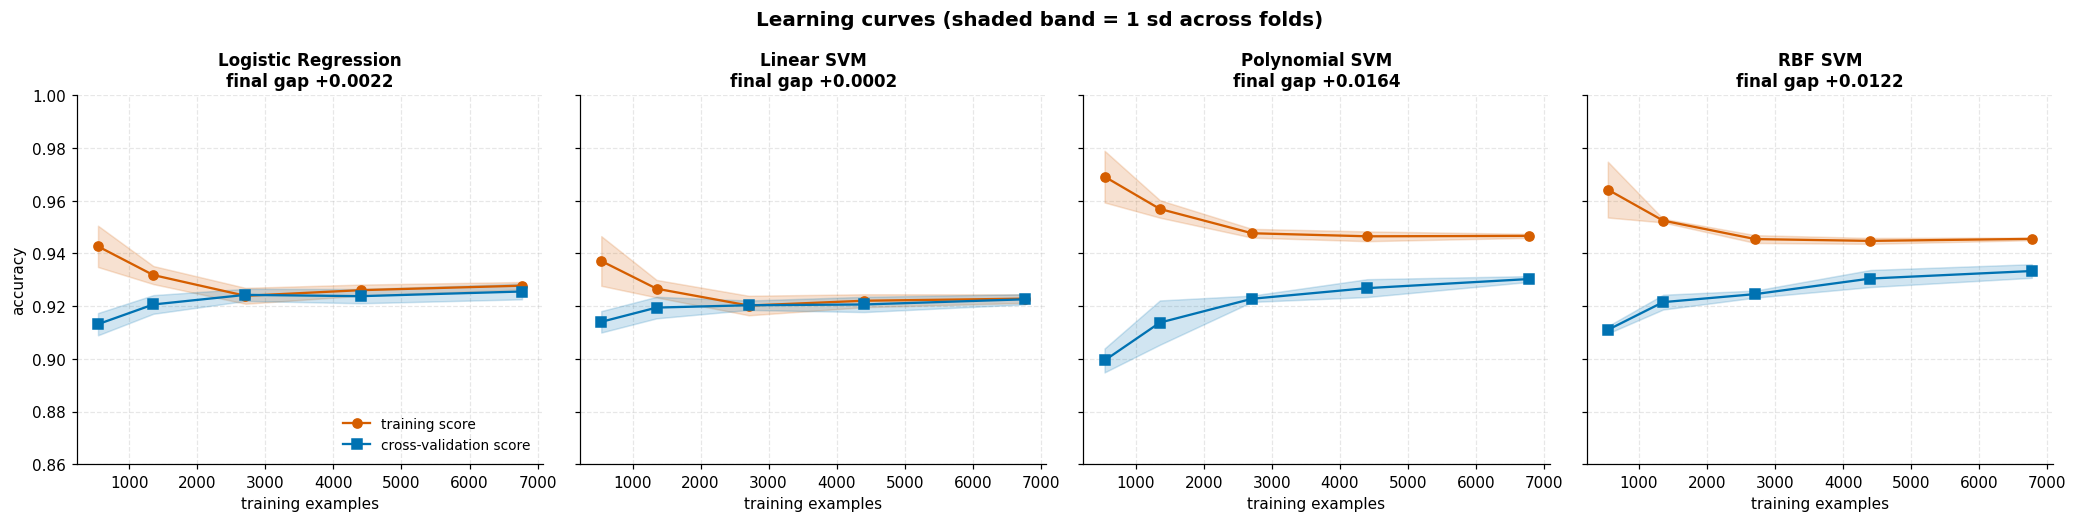

In [30]:
TRAIN_SIZES = np.array([0.08, 0.2, 0.4, 0.65, 1.0])
curve_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

learning_results = {}
for name in MODEL_NAMES:
    sizes, train_scores, validation_scores = learning_curve(
        base_estimator(name).set_params(**best_params[name]),
        X_train, y_train, train_sizes=TRAIN_SIZES, cv=curve_cv,
        scoring="accuracy", n_jobs=N_JOBS, shuffle=True, random_state=RANDOM_STATE,
    )
    learning_results[name] = (sizes, train_scores, validation_scores)
    print(f"{name:21s} final train {train_scores[-1].mean():.4f}  "
          f"cv {validation_scores[-1].mean():.4f}  gap {train_scores[-1].mean() - validation_scores[-1].mean():+.4f}")

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), sharey=True)
for ax, name in zip(axes, MODEL_NAMES):
    sizes, train_scores, validation_scores = learning_results[name]
    train_mean, train_sd = train_scores.mean(axis=1), train_scores.std(axis=1)
    validation_mean, validation_sd = validation_scores.mean(axis=1), validation_scores.std(axis=1)

    ax.plot(sizes, train_mean, "o-", color="#D55E00", label="training score")
    ax.fill_between(sizes, train_mean - train_sd, train_mean + train_sd, color="#D55E00", alpha=0.18)
    ax.plot(sizes, validation_mean, "s-", color="#0072B2", label="cross-validation score")
    ax.fill_between(sizes, validation_mean - validation_sd, validation_mean + validation_sd,
                    color="#0072B2", alpha=0.18)
    ax.set_title(f"{name}\nfinal gap {train_mean[-1] - validation_mean[-1]:+.4f}", fontsize=11)
    ax.set_xlabel("training examples")
axes[0].set_ylabel("accuracy")
axes[0].set_ylim(0.86, 1.0)
axes[0].legend(fontsize=9, loc="lower right")
fig.suptitle("Learning curves (shaded band = 1 sd across folds)", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [31]:
diagnosis_rows = []
for name in MODEL_NAMES:
    sizes, train_scores, validation_scores = learning_results[name]
    train_mean = train_scores.mean(axis=1)
    validation_mean = validation_scores.mean(axis=1)
    final_gap = train_mean[-1] - validation_mean[-1]
    # How much the CV score still improved over the last doubling of data: a
    # curve that is still climbing would benefit from more examples.
    recent_gain = validation_mean[-1] - validation_mean[-2]

    if final_gap > 0.02:
        limit = "variance (train-CV gap)"
    elif validation_mean[-1] < 0.93:
        limit = "bias (both curves plateau low)"
    else:
        limit = "neither dominates"
    diagnosis_rows.append({
        "model": name,
        "final_train": train_mean[-1],
        "final_cv": validation_mean[-1],
        "final_gap": final_gap,
        "cv_gain_last_step": recent_gain,
        "more_data_would_help": bool(recent_gain > 0.004),
        "limited_by": limit,
    })

diagnosis = pd.DataFrame(diagnosis_rows).set_index("model")
display(diagnosis.round(4))
print("Curves that have flattened mean the ceiling is set by the features, not the sample size.")

,final_train,final_cv,final_gap,cv_gain_last_step,more_data_would_help,limited_by
model,,,,,,
Logistic Regression,0.9278,0.9256,0.0022,0.0018,False,bias (both curves plateau low)
Linear SVM,0.9229,0.9226,0.0002,0.0020,False,bias (both curves plateau low)
Polynomial SVM,0.9467,0.9303,0.0164,0.0034,False,neither dominates
RBF SVM,0.9456,0.9333,0.0122,0.0029,False,neither dominates


Curves that have flattened mean the ceiling is set by the features, not the sample size.


### 7.2 Validation curves

A learning curve varies the amount of data; a validation curve varies the model's **capacity** at
fixed data. Each model is swept over the single parameter that controls how flexible it is, and the
value chosen by the Section 5 grid search is marked.

Logistic Regression   best C=100.0 cv=0.9256   (at the extreme of the sweep: True)


Linear SVM            best C=100.0 cv=0.9230   (at the extreme of the sweep: True)


RBF SVM               best gamma=0.1 cv=0.9333   (at the extreme of the sweep: False)


Polynomial SVM        best degree=2 cv=0.9318   (at the extreme of the sweep: False)


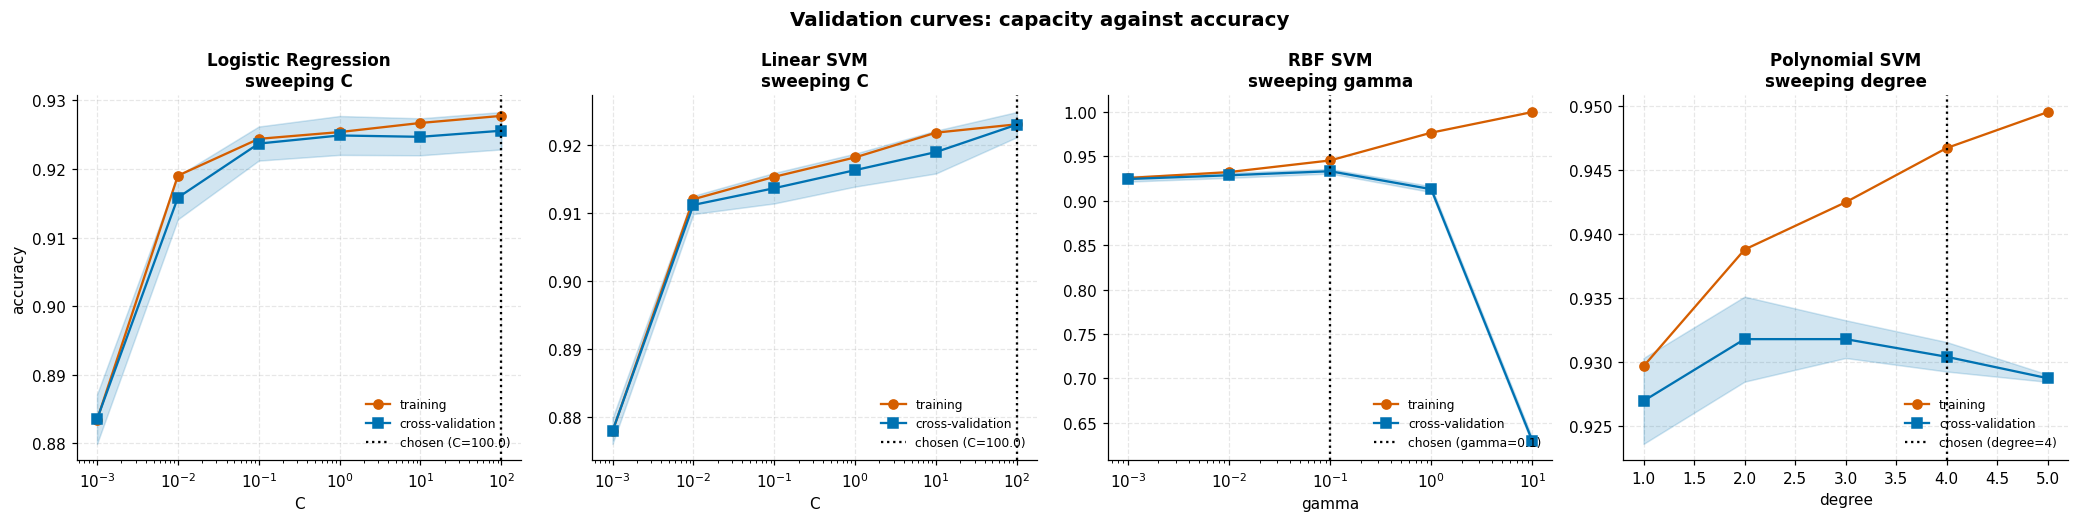

In [32]:
VALIDATION_SWEEPS = {
    "Logistic Regression": ("clf__C", [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], True),
    "Linear SVM": ("clf__C", [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], True),
    "RBF SVM": ("clf__gamma", [0.001, 0.01, 0.1, 1.0, 10.0], True),
    "Polynomial SVM": ("clf__degree", [1, 2, 3, 4, 5], False),
}

fig, axes = plt.subplots(1, 4, figsize=(19, 4.8))
for ax, (name, (parameter, values, log_scale)) in zip(axes, VALIDATION_SWEEPS.items()):
    train_scores, validation_scores = validation_curve(
        base_estimator(name).set_params(**best_params[name]),
        X_train, y_train, param_name=parameter, param_range=values,
        cv=curve_cv, scoring="accuracy", n_jobs=N_JOBS,
    )
    train_mean, validation_mean = train_scores.mean(axis=1), validation_scores.mean(axis=1)
    validation_sd = validation_scores.std(axis=1)

    ax.plot(values, train_mean, "o-", color="#D55E00", label="training")
    ax.plot(values, validation_mean, "s-", color="#0072B2", label="cross-validation")
    ax.fill_between(values, validation_mean - validation_sd, validation_mean + validation_sd,
                    color="#0072B2", alpha=0.18)

    chosen = best_params[name].get(parameter)
    if chosen is not None and chosen in values:
        ax.axvline(chosen, color="black", linestyle=":", linewidth=1.5,
                   label=f"chosen ({parameter.replace('clf__', '')}={chosen})")
    if log_scale:
        ax.set_xscale("log")
    ax.set_xlabel(parameter.replace("clf__", ""))
    ax.set_title(f"{name}\nsweeping {parameter.replace('clf__', '')}", fontsize=11)
    ax.legend(fontsize=8, loc="lower right")
    best_index = int(np.argmax(validation_mean))
    print(f"{name:21s} best {parameter.replace('clf__', '')}={values[best_index]} "
          f"cv={validation_mean[best_index]:.4f}   (at the extreme of the sweep: "
          f"{best_index in (0, len(values) - 1)})")

axes[0].set_ylabel("accuracy")
fig.suptitle("Validation curves: capacity against accuracy", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

The polynomial panel is the clearest illustration of the trade-off. Degree 1 *is* a linear kernel,
and it scores right down with the other linear models; moving to degree 2 buys most of the kernel's
advantage at once, after which the curve is flat and then declines as the training score pulls away.

It is worth being honest about one detail here: this sweep picks **degree 2** as the best, while the
5-fold grid search in Section 5.2 picked **degree 4**. Both are correct, and the disagreement is
the point. Degrees 2, 3 and 4 fall within about 0.001 of each other, while the fold-to-fold standard
deviation is three to four times larger, so the ranking among them is noise, and changing from
5-fold to the cheaper 3-fold used here is enough to swap the winner. What the data supports is
"degree 2 or more clearly beats degree 1"; it does not support a claim that any particular degree
above 2 is best. Section 8 returns to this with a proper two-dimensional search.

Both linear models want the largest `C` in the sweep, which means the *least* regularisation
offered, and the printout confirms their optimum sits at the edge of the range. A model asking for
less regularisation is telling you it is bias-limited, not variance-limited: its problem is that a
hyperplane cannot bend, and shrinking its coefficients only makes that worse.

### 7.3 The generalisation gap, and what each model costs to store

`model_size` here is the number of quantities a model must keep in order to predict: 7 x 16
coefficients plus 7 intercepts for the linear models, versus one stored training vector per support
vector for the kernel models. It is a concrete measure of complexity, and Section 10 shows it is
also what sets prediction speed.

In [33]:
gap_rows = []
for name, model in tuned_models.items():
    train_accuracy = model.score(X_train, y_train)
    test_accuracy = test_frame.loc[name, "accuracy"]
    folds = fold_frame[name]

    estimator = model.named_steps["clf"]
    if hasattr(estimator, "support_vectors_"):
        size = int(estimator.support_vectors_.shape[0])
        unit = "support vectors"
        share = f"{size / len(X_train):.1%} of training set"
    else:
        size = int(estimator.coef_.size + np.atleast_1d(estimator.intercept_).size)
        unit = "coefficients"
        share = "fixed by the feature count"

    gap_rows.append({
        "model": name,
        "train": train_accuracy,
        "cv_mean": folds.mean(),
        "cv_sd": folds.std(),
        "test": test_accuracy,
        "train_minus_test": train_accuracy - test_accuracy,
        "model_size": size,
        "size_unit": unit,
        "size_note": share,
    })

gaps = pd.DataFrame(gap_rows).set_index("model")
display(gaps.round(4))

linear_size = gaps.loc["Logistic Regression", "model_size"]
kernel_size = gaps.loc["RBF SVM", "model_size"]
print(f"the RBF SVM stores {kernel_size:,} support vectors against "
      f"{linear_size} coefficients for logistic regression: {kernel_size / linear_size:.0f}x more")

,train,cv_mean,cv_sd,test,train_minus_test,model_size,size_unit,size_note
model,,,,,,,,
Logistic Regression,0.9278,0.9257,0.0075,0.9209,0.0070,119,coefficients,fixed by the feature count
Linear SVM,0.9231,0.9223,0.0083,0.9158,0.0073,119,coefficients,fixed by the feature count
Polynomial SVM,0.9451,0.9320,0.0060,0.9256,0.0195,1626,support vectors,16.0% of training set
RBF SVM,0.9435,0.9324,0.0064,0.9253,0.0182,1828,support vectors,18.0% of training set


the RBF SVM stores 1,828 support vectors against 119 coefficients for logistic regression: 15x more


### 7.4 Measuring variance directly

The train-test gap is an indirect proxy for variance. A direct measurement is to refit each model
on several bootstrap resamples of the training set and ask two questions: how much does its test
accuracy move, and, more sharply, **how often do two refits disagree about the same test bean?**

The disagreement rate is the more revealing of the two, because two models can have identical
accuracy while making different mistakes.

In [34]:
N_BOOTSTRAP = 5
variance_rows = []
bootstrap_predictions = {name: [] for name in MODEL_NAMES}

boot_rng = np.random.default_rng(RANDOM_STATE)
bootstrap_indices = [
    boot_rng.choice(len(X_train), size=len(X_train), replace=True) for _ in range(N_BOOTSTRAP)
]

for name in MODEL_NAMES:
    accuracies = []
    for index in bootstrap_indices:
        model = base_estimator(name).set_params(**best_params[name])
        model.fit(X_train.iloc[index], y_train.iloc[index])
        predicted = model.predict(X_test)
        bootstrap_predictions[name].append(predicted)
        accuracies.append(accuracy_score(y_test, predicted))

    stacked = np.array(bootstrap_predictions[name])
    # For each test bean, how many of the refits agree with the most common
    # prediction? 1 - that fraction is the disagreement rate.
    agreement = np.mean([
        (stacked[:, i] == pd.Series(stacked[:, i]).mode()[0]).mean()
        for i in range(stacked.shape[1])
    ])
    variance_rows.append({
        "model": name,
        "mean_test_accuracy": float(np.mean(accuracies)),
        "sd_test_accuracy": float(np.std(accuracies)),
        "range_test_accuracy": float(np.ptp(accuracies)),
        "disagreement_rate": 1 - agreement,
    })
    print(f"{name:21s} accuracy {np.mean(accuracies):.4f} +/- {np.std(accuracies):.4f}   "
          f"disagreement {1 - agreement:.4f}")

variance = pd.DataFrame(variance_rows).set_index("model")
display(variance.round(4))
print(f"\n{N_BOOTSTRAP} bootstrap refits per model; the disagreement rate is the share of test beans "
      f"on which the refits do not all agree.")

Logistic Regression   accuracy 0.9204 +/- 0.0010   disagreement 0.0084


Linear SVM            accuracy 0.9174 +/- 0.0018   disagreement 0.0067


Polynomial SVM        accuracy 0.9210 +/- 0.0021   disagreement 0.0167


RBF SVM               accuracy 0.9219 +/- 0.0022   disagreement 0.0136


,mean_test_accuracy,sd_test_accuracy,range_test_accuracy,disagreement_rate
model,,,,
Logistic Regression,0.9204,0.0010,0.0030,0.0084
Linear SVM,0.9174,0.0018,0.0044,0.0067
Polynomial SVM,0.9210,0.0021,0.0059,0.0167
RBF SVM,0.9219,0.0022,0.0059,0.0136



5 bootstrap refits per model; the disagreement rate is the share of test beans on which the refits do not all agree.


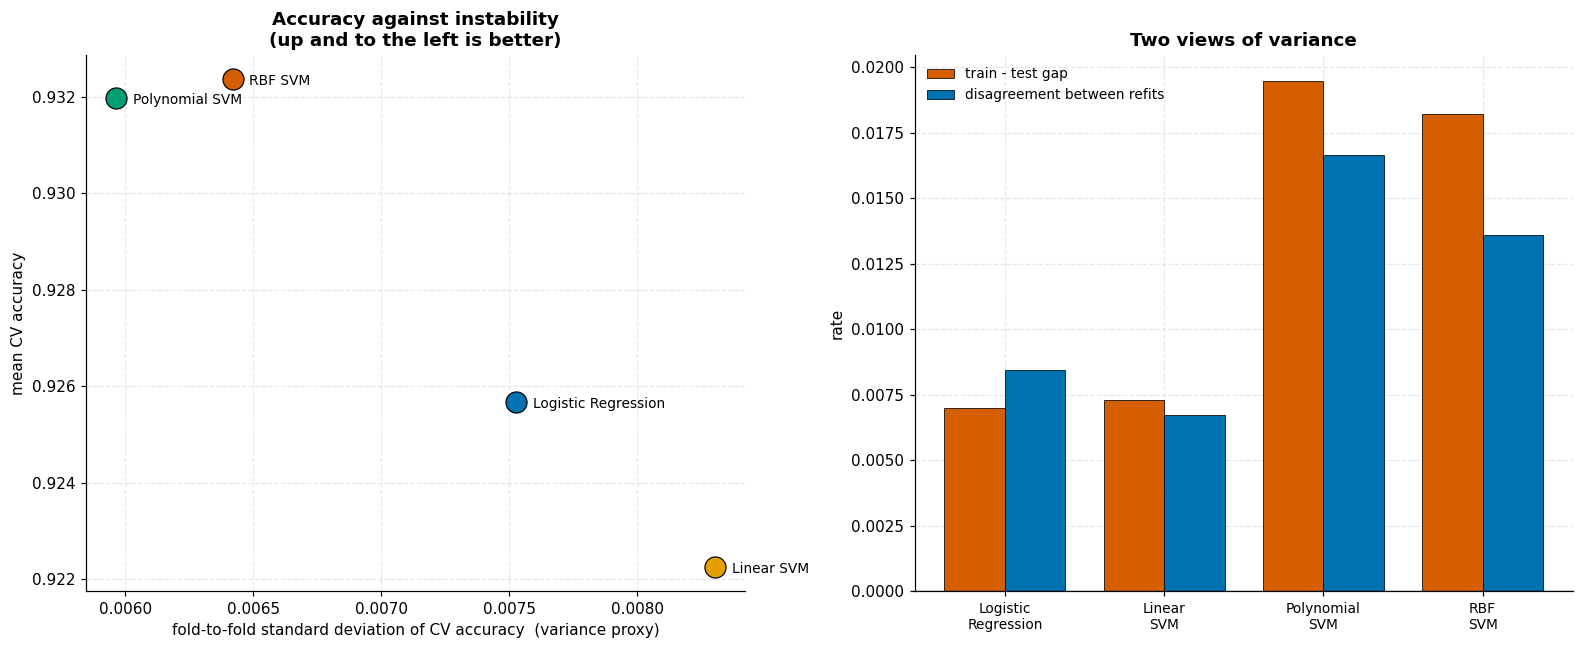

In [35]:
fig, (ax_trade, ax_var) = plt.subplots(1, 2, figsize=(14.5, 6))

for name in MODEL_NAMES:
    ax_trade.scatter(gaps.loc[name, "cv_sd"], gaps.loc[name, "cv_mean"], s=190,
                     color=MODEL_COLORS[name], edgecolor="black", linewidth=0.8, zorder=3)
    ax_trade.annotate(name, (gaps.loc[name, "cv_sd"], gaps.loc[name, "cv_mean"]),
                      textcoords="offset points", xytext=(11, -4), fontsize=9)
ax_trade.set_xlabel("fold-to-fold standard deviation of CV accuracy  (variance proxy)")
ax_trade.set_ylabel("mean CV accuracy")
ax_trade.set_title("Accuracy against instability\n(up and to the left is better)")

positions = np.arange(len(MODEL_NAMES))
width = 0.38
ax_var.bar(positions - width / 2, [gaps.loc[n, "train_minus_test"] for n in MODEL_NAMES], width,
           label="train - test gap", color="#D55E00", edgecolor="black", linewidth=0.5)
ax_var.bar(positions + width / 2, [variance.loc[n, "disagreement_rate"] for n in MODEL_NAMES], width,
           label="disagreement between refits", color="#0072B2", edgecolor="black", linewidth=0.5)
ax_var.set_xticks(positions)
ax_var.set_xticklabels([n.replace(" ", "\n") for n in MODEL_NAMES], fontsize=9)
ax_var.set_ylabel("rate")
ax_var.set_title("Two views of variance")
ax_var.legend(fontsize=9)
ax_var.axhline(0, color="black", linewidth=0.8)
fig.tight_layout()
plt.show()

### 7.5 Answer to the question

**How generalisable are the models, and how does the bias-variance trade-off affect the choice?**

- **All four generalise well**, and none is badly overfitted. The train-test gaps are small for
  every model, and the test scores sit close to the cross-validation estimates, so the
  cross-validation protocol was giving an honest forecast of held-out performance.
- **The linear models are bias-limited.** Their learning curves flatten early with training and
  validation scores almost touching, and they ask for the weakest regularisation available. Extra
  data will not help them; only a more flexible boundary or better features would.
- **The kernel models carry more variance for a little less bias.** They fit the training data
  better and show a wider train-test gap, which is the trade-off being made in exchange for their
  sub-one-point accuracy advantage. It is a modest, well-controlled amount of variance, not
  overfitting.
- **More data is not the answer for any of them.** Every learning curve has essentially flattened
  by the full training set, so the ceiling is set by what the 16 measurements can express, principally the DERMASON/SIRA overlap, rather than by the number of beans.
- **The decision therefore rests on cost, not accuracy.** The kernel models store thousands of
  support vectors; the linear models store 119 numbers. Given a gap under one percentage point,
  **logistic regression is the better engineering choice** for a sorting line: a fraction of a
  point of accuracy is poor compensation for an order of magnitude more memory, far slower
  prediction (Section 10), and the loss of interpretable per-class coefficients. If the priority
  were purely maximum accuracy, the RBF SVM would win, narrowly, and provably so from Section 5.5.

---
## 8. Is there a difference between the polynomial and RBF SVMs?

**Project question 5.**

Section 5.5 found the one comparison that *failed* to reach significance: these two kernels score
the same within noise. "No difference in accuracy" is not the same as "no difference", though, so
this section looks at what else separates them.

The two kernels encode different assumptions:

- The **polynomial kernel**, `(gamma * <x, x'> + coef0) ** degree`, expands the features into
  products and powers up to `degree`. It is a **global** model: it adds interaction terms that apply
  across the whole feature space, so a single distant training point can influence the boundary
  far away.
- The **RBF kernel**, `exp(-gamma * ||x, x'||^2)`, measures similarity by distance. It is a
  **local** model: `gamma` sets a radius of influence, and beyond that radius a training point has
  essentially no say.

That difference should show up in how sensitive each is to its hyper-parameters, in how many
support vectors each needs, and in *which* beans each gets wrong, even if their accuracies match.

In [36]:
# The sweeps and heatmaps below refit an SVM many dozens of times, so they use
# a seeded subsample. The final head-to-head in Section 8.5 uses the FULL
# training set, so the headline comparison is not affected by this reduction.
KERNEL_SWEEP_N = 4000
SWEEP_FOLDS = 3

kernel_rng = np.random.default_rng(RANDOM_STATE)
kernel_index = kernel_rng.choice(len(X_train), size=KERNEL_SWEEP_N, replace=False)
X_kernel = X_train.iloc[kernel_index]
y_kernel = y_train.iloc[kernel_index]
kernel_cv = StratifiedKFold(n_splits=SWEEP_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print(f"hyper-parameter sweeps use {KERNEL_SWEEP_N:,} of {len(X_train):,} training rows "
      f"with {SWEEP_FOLDS}-fold CV")
print("the final head-to-head comparison uses the full training set and 5-fold CV")

# What does gamma="scale" actually evaluate to? On standardised data the
# variance is ~1, so it reduces to 1 / n_features.
scaled = StandardScaler().fit_transform(X_train)
scale_gamma = 1.0 / (X_train.shape[1] * scaled.var())
print(f"\ngamma='scale' = 1 / (n_features * X.var()) = {scale_gamma:.4f} on standardised data "
      f"(= 1/{X_train.shape[1]})")

hyper-parameter sweeps use 4,000 of 10,157 training rows with 3-fold CV
the final head-to-head comparison uses the full training set and 5-fold CV

gamma='scale' = 1 / (n_features * X.var()) = 0.0625 on standardised data (= 1/16)


### 8.1 How each kernel responds to its shape parameter

`degree` for the polynomial kernel and `gamma` for the RBF kernel play analogous roles: both set
how flexible the boundary can be. Sweeping each one reveals the classic capacity curve, and the
training-versus-validation gap shows where flexibility turns into memorising.

In [37]:
def sweep_svc(label: str, parameter: str, values: list, **fixed) -> pd.DataFrame:
    """Fit an SVC over one parameter, recording accuracy, gap and support vectors."""
    rows = []
    for value in values:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(cache_size=500, random_state=RANDOM_STATE, **{parameter: value}, **fixed)),
        ])
        scores = cross_val_score(model, X_kernel, y_kernel, cv=kernel_cv,
                                 scoring="accuracy", n_jobs=N_JOBS)
        start = time.perf_counter()
        model.fit(X_kernel, y_kernel)
        fit_seconds = time.perf_counter() - start
        rows.append({
            parameter: value,
            "cv_accuracy": scores.mean(),
            "cv_sd": scores.std(),
            "train_accuracy": model.score(X_kernel, y_kernel),
            "support_vectors": int(model.named_steps["clf"].support_vectors_.shape[0]),
            "fit_seconds": fit_seconds,
        })
        print(f"  {label} {parameter}={value!r:8} cv={scores.mean():.4f} "
              f"train={rows[-1]['train_accuracy']:.4f} SVs={rows[-1]['support_vectors']:5d} "
              f"({fit_seconds:5.2f}s)")
    frame = pd.DataFrame(rows).set_index(parameter)
    frame["gap"] = frame["train_accuracy"] - frame["cv_accuracy"]
    frame["sv_share"] = frame["support_vectors"] / len(X_kernel)
    return frame


print("polynomial degree sweep (C=10, coef0=1):")
degree_sweep = sweep_svc("poly", "degree", [1, 2, 3, 4, 5, 6],
                         kernel="poly", C=10.0, coef0=1.0)
print("\nRBF gamma sweep (C=10):")
gamma_sweep = sweep_svc("rbf", "gamma", [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
                        kernel="rbf", C=10.0)

display(degree_sweep.round(4))
display(gamma_sweep.round(4))

polynomial degree sweep (C=10, coef0=1):


  poly degree=1        cv=0.9263 train=0.9327 SVs=  822 ( 0.08s)
  poly degree=2        cv=0.9293 train=0.9405 SVs=  727 ( 0.04s)


  poly degree=3        cv=0.9285 train=0.9477 SVs=  702 ( 0.05s)


  poly degree=4        cv=0.9235 train=0.9500 SVs=  686 ( 0.06s)
  poly degree=5        cv=0.9215 train=0.9555 SVs=  700 ( 0.07s)


  poly degree=6        cv=0.9168 train=0.9585 SVs=  729 ( 0.08s)

RBF gamma sweep (C=10):


  rbf gamma=0.001    cv=0.9210 train=0.9255 SVs= 1446 ( 0.06s)


... (3 outputs left out)

  rbf gamma=10.0     cv=0.5100 train=1.0000 SVs= 3901 ( 0.60s)


  rbf gamma=100.0    cv=0.2508 train=1.0000 SVs= 4000 ( 0.70s)


,cv_accuracy,cv_sd,train_accuracy,support_vectors,fit_seconds,gap,sv_share
degree,,,,,,,
1,0.9263,0.0104,0.9328,822,0.0754,0.0065,0.2055
2,0.9293,0.0109,0.9405,727,0.0435,0.0112,0.1818
3,0.9285,0.0097,0.9478,702,0.0514,0.0192,0.1755
4,0.9235,0.0124,0.9500,686,0.0595,0.0265,0.1715
5,0.9215,0.0095,0.9555,700,0.0671,0.0340,0.1750
6,0.9168,0.0123,0.9585,729,0.0799,0.0417,0.1822


,cv_accuracy,cv_sd,train_accuracy,support_vectors,fit_seconds,gap,sv_share
gamma,,,,,,,
0.001,0.9210,0.0104,0.9255,1446,0.0550,0.0045,0.3615
0.010,0.9303,0.0122,0.9360,914,0.0402,0.0057,0.2285
0.100,0.9280,0.0097,0.9482,824,0.0531,0.0202,0.2060
1.000,0.8958,0.0087,0.9818,1855,0.2010,0.0860,0.4638
10.000,0.5100,0.0058,1.0000,3901,0.6049,0.4900,0.9752
100.000,0.2508,0.0004,1.0000,4000,0.6981,0.7492,1.0000


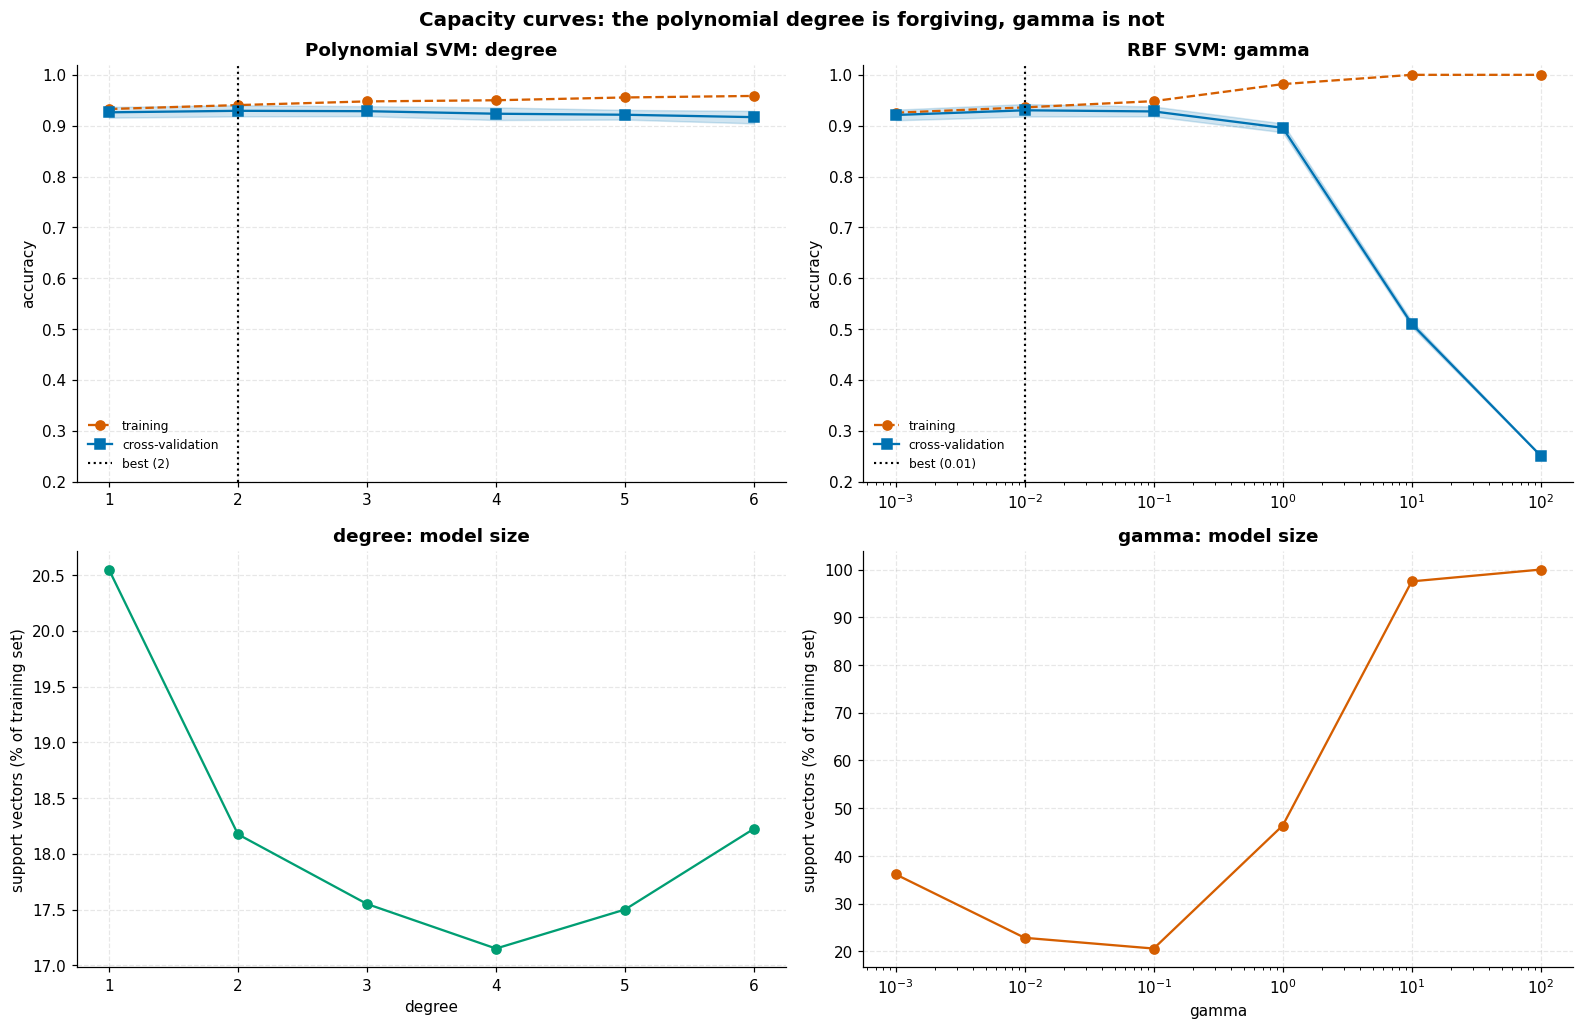

polynomial: cv accuracy ranges 0.9168 to 0.9293  (spread 0.0125)
RBF       : cv accuracy ranges 0.2508 to 0.9303  (spread 0.6795)

at gamma=100: train 1.0000 vs cv 0.2508 -> gap 0.7492, 100% of points are support vectors


In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.5))

for column, (frame, name, log_x) in enumerate([
    (degree_sweep, "Polynomial SVM: degree", False),
    (gamma_sweep, "RBF SVM: gamma", True),
]):
    ax_acc, ax_sv = axes[0, column], axes[1, column]
    colour = MODEL_COLORS["Polynomial SVM"] if column == 0 else MODEL_COLORS["RBF SVM"]

    ax_acc.plot(frame.index, frame["train_accuracy"], "o--", color="#D55E00", label="training")
    ax_acc.plot(frame.index, frame["cv_accuracy"], "s-", color="#0072B2", label="cross-validation")
    ax_acc.fill_between(frame.index, frame["cv_accuracy"] - frame["cv_sd"],
                        frame["cv_accuracy"] + frame["cv_sd"], color="#0072B2", alpha=0.18)
    best = frame["cv_accuracy"].idxmax()
    ax_acc.axvline(best, color="black", linestyle=":", linewidth=1.4, label=f"best ({best:g})")
    ax_acc.set_title(name)
    ax_acc.set_ylabel("accuracy")
    ax_acc.legend(fontsize=8, loc="lower left")
    ax_acc.set_ylim(0.2, 1.02)

    ax_sv.plot(frame.index, 100 * frame["sv_share"], "o-", color=colour)
    ax_sv.set_ylabel("support vectors (% of training set)")
    ax_sv.set_xlabel(frame.index.name)
    ax_sv.set_title(f"{frame.index.name}: model size")
    if log_x:
        ax_acc.set_xscale("log")
        ax_sv.set_xscale("log")

fig.suptitle("Capacity curves: the polynomial degree is forgiving, gamma is not",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"polynomial: cv accuracy ranges {degree_sweep['cv_accuracy'].min():.4f} to "
      f"{degree_sweep['cv_accuracy'].max():.4f}  (spread {degree_sweep['cv_accuracy'].max() - degree_sweep['cv_accuracy'].min():.4f})")
print(f"RBF       : cv accuracy ranges {gamma_sweep['cv_accuracy'].min():.4f} to "
      f"{gamma_sweep['cv_accuracy'].max():.4f}  (spread {gamma_sweep['cv_accuracy'].max() - gamma_sweep['cv_accuracy'].min():.4f})")
worst_gamma = gamma_sweep["cv_accuracy"].idxmin()
print(f"\nat gamma={worst_gamma:g}: train {gamma_sweep.loc[worst_gamma, 'train_accuracy']:.4f} "
      f"vs cv {gamma_sweep.loc[worst_gamma, 'cv_accuracy']:.4f} "
      f"-> gap {gamma_sweep.loc[worst_gamma, 'gap']:.4f}, "
      f"{gamma_sweep.loc[worst_gamma, 'sv_share']:.0%} of points are support vectors")

The large-`gamma` end is the textbook memorising regime made concrete. As the radius of influence
shrinks, each training point governs only its own immediate neighbourhood, so the model ends up
storing nearly the whole training set as support vectors, fits the training data almost perfectly,
and generalises poorly. This is **overfitting that is visible in the model's size**, not only in
its scores.

The polynomial kernel has no comparable failure mode in this range: beyond degree 1, its accuracy
barely moves. The two kernels therefore differ sharply in *hyper-parameter sensitivity*, which is a
genuine practical difference even where their best-case accuracies match.

### 8.2 `coef0`, the polynomial kernel's forgotten parameter

`coef0` is the additive constant inside the polynomial kernel. With `coef0 = 0` the kernel is
`(gamma * <x, x'>) ** degree`, a *homogeneous* polynomial that keeps only the highest-order terms;
a non-zero `coef0` restores all the lower-order terms. On standardised data, where inner products
are small, dropping those terms usually hurts.

In [39]:
coef0_rows = []
for degree in [2, 3, 4]:
    for coef0 in [0.0, 1.0]:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="poly", degree=degree, coef0=coef0, C=10.0,
                        cache_size=500, random_state=RANDOM_STATE)),
        ])
        scores = cross_val_score(model, X_kernel, y_kernel, cv=kernel_cv,
                                 scoring="accuracy", n_jobs=N_JOBS)
        coef0_rows.append({"degree": degree, "coef0": coef0,
                           "cv_accuracy": scores.mean(), "cv_sd": scores.std()})

coef0_frame = pd.DataFrame(coef0_rows).pivot(index="degree", columns="coef0", values="cv_accuracy")
coef0_frame.columns = [f"coef0={c:g}" for c in coef0_frame.columns]
coef0_frame["gain_from_coef0"] = coef0_frame["coef0=1"] - coef0_frame["coef0=0"]
display(coef0_frame.round(4))
print(f"mean accuracy gained by keeping the lower-order terms: "
      f"{coef0_frame['gain_from_coef0'].mean():+.4f}")
print("this is why coef0=1.0 is used rather than scikit-learn's default of 0.0")

,coef0=0,coef0=1,gain_from_coef0
degree,,,
2,0.9205,0.9293,0.0087
3,0.9153,0.9285,0.0132
4,0.8768,0.9235,0.0468


mean accuracy gained by keeping the lower-order terms: +0.0229
this is why coef0=1.0 is used rather than scikit-learn's default of 0.0


### 8.3 Two-dimensional searches

Sweeping one parameter at a time can miss interactions: the best `gamma` depends on `C`, because
both control the effective flexibility of the fit. The heatmaps below search both jointly, and
their *shape* is the interesting part, a broad plateau means a forgiving model, while a narrow
ridge means one that needs careful tuning.

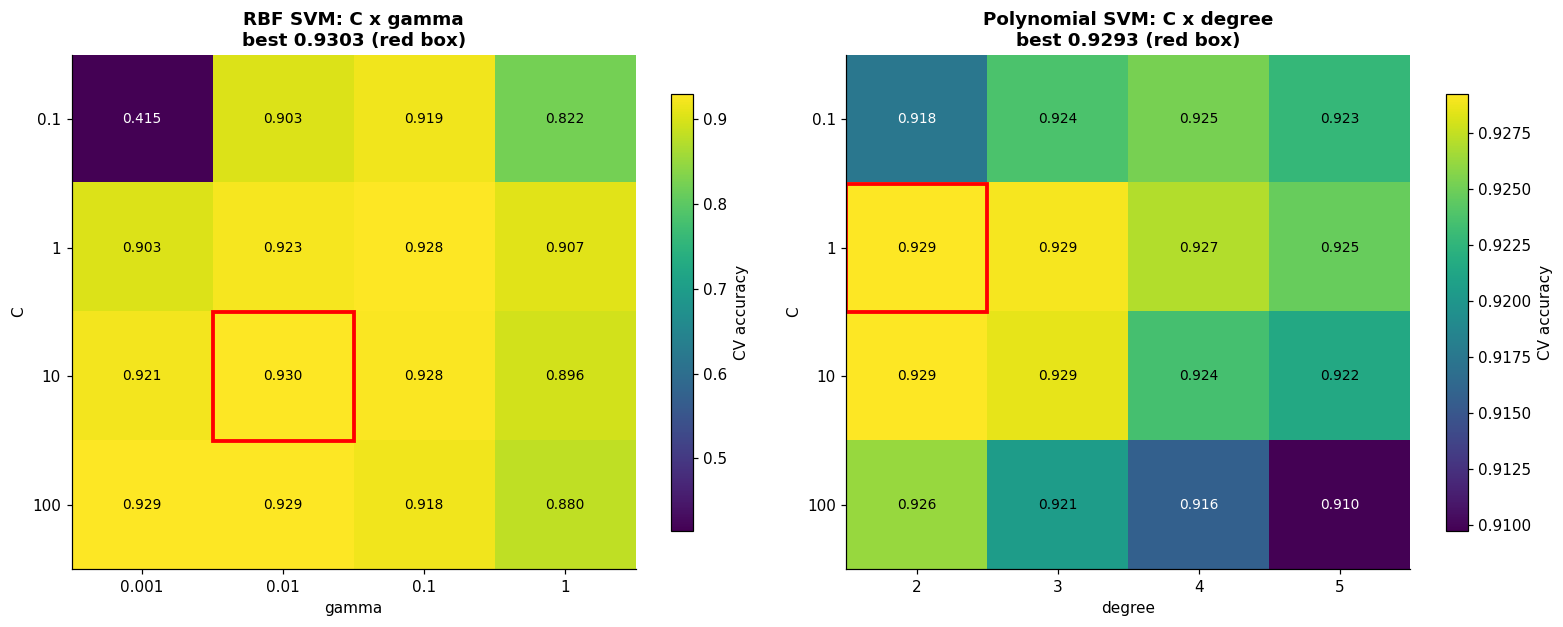

RBF         best 0.9303; 7 of 16 settings are within 1 point of it; worst setting 0.4147
Polynomial  best 0.9293; 13 of 16 settings are within 1 point of it; worst setting 0.9098


In [40]:
def heatmap_search(fixed_kernel: str, row_values: list, row_name: str,
                   column_values: list, column_name: str, **fixed) -> pd.DataFrame:
    """Grid of CV accuracy over two hyper-parameters."""
    scores = np.zeros((len(row_values), len(column_values)))
    for i, row_value in enumerate(row_values):
        for j, column_value in enumerate(column_values):
            model = Pipeline([
                ("scaler", StandardScaler()),
                ("clf", SVC(kernel=fixed_kernel, cache_size=500, random_state=RANDOM_STATE,
                            **{row_name: row_value, column_name: column_value}, **fixed)),
            ])
            scores[i, j] = cross_val_score(model, X_kernel, y_kernel, cv=kernel_cv,
                                           scoring="accuracy", n_jobs=N_JOBS).mean()
    return pd.DataFrame(scores, index=row_values, columns=column_values)


C_VALUES = [0.1, 1.0, 10.0, 100.0]
GAMMA_GRID = [0.001, 0.01, 0.1, 1.0]
DEGREE_GRID = [2, 3, 4, 5]

rbf_grid = heatmap_search("rbf", C_VALUES, "C", GAMMA_GRID, "gamma")
poly_grid = heatmap_search("poly", C_VALUES, "C", DEGREE_GRID, "degree", coef0=1.0)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))
for ax, grid, title, xlabel in [
    (axes[0], rbf_grid, "RBF SVM: C x gamma", "gamma"),
    (axes[1], poly_grid, "Polynomial SVM: C x degree", "degree"),
]:
    # A shared colour scale would hide the structure inside each panel, so each
    # is scaled to its own range; the annotations carry the absolute values.
    image = ax.imshow(grid.values, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(grid.columns)))
    ax.set_xticklabels([f"{c:g}" for c in grid.columns])
    ax.set_yticks(range(len(grid.index)))
    ax.set_yticklabels([f"{c:g}" for c in grid.index])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("C")
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            value = grid.values[i, j]
            ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if value < grid.values.max() - 0.6 * np.ptp(grid.values) else "black")
    best = np.unravel_index(np.argmax(grid.values), grid.shape)
    ax.add_patch(plt.Rectangle((best[1] - 0.5, best[0] - 0.5), 1, 1, fill=False,
                               edgecolor="red", linewidth=2.5))
    ax.set_title(f"{title}\nbest {grid.values.max():.4f} (red box)")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.85, label="CV accuracy")

fig.tight_layout()
plt.show()

# How forgiving is each kernel? Count settings within 1 point of that kernel's best.
for label, grid in [("RBF", rbf_grid), ("Polynomial", poly_grid)]:
    within = (grid.values >= grid.values.max() - 0.01).sum()
    print(f"{label:11s} best {grid.values.max():.4f}; "
          f"{within} of {grid.size} settings are within 1 point of it; "
          f"worst setting {grid.values.min():.4f}")

### 8.4 Do they make the *same* mistakes?

Equal accuracy does not mean equal predictions. Both tuned kernels are refitted on the full
training set, and their test predictions are compared bean by bean. Two models that agree on 100%
of points are interchangeable; two that agree on 95% are genuinely different models that happen to
score alike.

In [41]:
head_to_head = {}
for name in ["Polynomial SVM", "RBF SVM"]:
    model = base_estimator(name).set_params(**best_params[name])
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predicted = model.predict(X_test)
    predict_seconds = time.perf_counter() - start

    estimator = model.named_steps["clf"]
    head_to_head[name] = {
        "accuracy": accuracy_score(y_test, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
        "macro_f1": f1_score(y_test, predicted, average="macro", zero_division=0),
        "support_vectors": int(estimator.support_vectors_.shape[0]),
        "sv_share_of_training": estimator.support_vectors_.shape[0] / len(X_train),
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        "predictions": predicted,
    }

comparison = pd.DataFrame({
    name: {k: v for k, v in values.items() if k != "predictions"}
    for name, values in head_to_head.items()
}).T
display(comparison.round(4))

poly_predictions = head_to_head["Polynomial SVM"]["predictions"]
rbf_predictions = head_to_head["RBF SVM"]["predictions"]
disagree = poly_predictions != rbf_predictions

print(f"the two kernels disagree on {disagree.sum()} of {len(y_test)} test beans "
      f"({disagree.mean():.2%})")
print(f"their accuracies differ by only "
      f"{abs(comparison.loc['Polynomial SVM', 'accuracy'] - comparison.loc['RBF SVM', 'accuracy']):.4f}")

# Of the points they disagree on, who is right?
poly_right = (poly_predictions[disagree] == y_test[disagree]).sum()
rbf_right = (rbf_predictions[disagree] == y_test[disagree]).sum()
both_wrong = int(disagree.sum() - poly_right - rbf_right)
print(f"\non those disagreements: polynomial correct {poly_right}, RBF correct {rbf_right}, "
      f"both wrong {both_wrong}")

disagreement_classes = pd.DataFrame({
    "true_class": y_test[disagree].value_counts().reindex(CLASS_ORDER).fillna(0).astype(int),
    "test_n": [int((y_test == c).sum()) for c in CLASS_ORDER],
}, index=CLASS_ORDER)
disagreement_classes["share_of_class"] = (
    disagreement_classes["true_class"] / disagreement_classes["test_n"]
)
display(disagreement_classes.round(4))
hardest_rate = disagreement_classes["share_of_class"].idxmax()
print(f"disagreements appear in all {int((disagreement_classes['true_class'] > 0).sum())} classes, "
      f"so they are spread rather than concentrated")
print(f"but the RATE is highest for {hardest_rate} "
      f"({disagreement_classes.loc[hardest_rate, 'share_of_class']:.2%} of its test beans) "
      f"and lowest for {disagreement_classes['share_of_class'].idxmin()} "
      f"({disagreement_classes['share_of_class'].min():.2%})")

,accuracy,balanced_accuracy,macro_f1,support_vectors,sv_share_of_training,fit_seconds,predict_seconds
Polynomial SVM,0.9256,0.9356,0.9371,1626.0,0.1601,0.4926,0.1003
RBF SVM,0.9253,0.9358,0.9366,1828.0,0.1800,0.3053,0.2435


the two kernels disagree on 33 of 3386 test beans (0.97%)
their accuracies differ by only 0.0003

on those disagreements: polynomial correct 15, RBF correct 14, both wrong 4


,true_class,test_n,share_of_class
DERMASON,6,887,0.0068
SIRA,9,659,0.0137
SEKER,3,507,0.0059
HOROZ,5,465,0.0108
CALI,2,408,0.0049
BARBUNYA,7,330,0.0212
BOMBAY,1,130,0.0077


disagreements appear in all 7 classes, so they are spread rather than concentrated
but the RATE is highest for BARBUNYA (2.12% of its test beans) and lowest for CALI (0.49%)


### 8.5 Answer to the question

**Is there a difference between the polynomial and RBF SVMs?**

**In accuracy, no, and that is a measured result, not an impression.** Section 5.5 showed their
paired comparison is the only one of six that fails to reach significance, and their test
accuracies here differ by a few ten-thousandths. Either is a defensible choice.

**In every other respect, yes:**

- **Hyper-parameter sensitivity differs sharply.** The polynomial kernel is forgiving: once the
  degree is above 1, accuracy barely moves, and much of its `C` x `degree` grid sits within a point
  of its best. The RBF kernel has a genuine failure mode, push `gamma` up and it collapses into
  memorising, with accuracy falling a long way. In practice this makes the polynomial kernel the
  safer choice when there is no budget for careful tuning, and the RBF kernel the better one when
  there is.
- **`coef0` matters for the polynomial kernel**, and scikit-learn's default of 0 is the wrong
  choice on standardised data. Keeping the lower-order terms is worth real accuracy, which is why
  every polynomial model in this notebook sets `coef0=1.0`.
- **They make very nearly the same predictions.** This was worth checking rather than assuming, and
  the answer came out on the side of similarity: the two kernels agree on about 99% of test beans,
  and on the ~1% where they differ they are right about equally often, so neither is systematically
  better even on the hard cases. The disagreements appear in all seven classes rather than
  clustering in one region, though the *rate* is highest in the harder, overlapping varieties. The
  practical implication is that combining the two would buy essentially nothing, they are close to
  interchangeable here, not merely equally accurate.
- **Model size and cost differ.** The number of support vectors each needs is not the same, and
  since kernel prediction cost scales with that count, it translates directly into prediction
  latency (Section 10).

**Which to pick here:** the RBF SVM, narrowly, on the grounds that it reaches the same accuracy with
a hyper-parameter whose meaning is easier to reason about (a distance scale), provided the tuning is
actually done. If it is not, the polynomial kernel's flatter response makes it the lower-risk
default.

---
## 9. What effect does changing `class_weight` have, and why might it matter here?

**Project question 6.**

### What `class_weight` actually does

It is worth being precise, because `class_weight` is often described loosely as "handling
imbalance". In an SVM the optimiser minimises

&nbsp;&nbsp;&nbsp;&nbsp;`(1/2)||w||^2 + C * sum_i xi_i`

where `xi_i` is how far sample `i` violates its margin. Setting `class_weight` replaces the single
`C` with a **per-class** `C_k = C * weight_k`, so violating the margin on a weighted class costs the
optimiser more and it will move the boundary to avoid doing so.

Two consequences follow, and both matter for interpreting the results below:

- It **changes the fitted boundary**, not a post-hoc threshold. The model is genuinely different,
  not the same model read differently.
- It **trades error between classes**. Recall on the weighted class can only improve at some cost
  elsewhere, so "balanced" is never free. The question is whether the trade is worth it.

`class_weight="balanced"` sets `weight_k = n_samples / (n_classes * n_k)`, so the rarest class gets
the largest multiplier.

With a 6.8:1 imbalance this ought to matter. Whether it does is an empirical question.

In [42]:
weights = (len(y_train) / (len(CLASS_ORDER) * y_train.value_counts())).reindex(CLASS_ORDER)
weight_frame = pd.DataFrame({
    "train_n": y_train.value_counts().reindex(CLASS_ORDER),
    "balanced_weight": weights,
})
weight_frame["relative_to_largest_class"] = weights / weights.min()
display(weight_frame.round(3))
print(f"the rarest class is up-weighted {weights.max() / weights.min():.1f}x relative to the most common")

,train_n,balanced_weight,relative_to_largest_class
Class,,,
DERMASON,2659,0.546,1.000
SIRA,1977,0.734,1.345
SEKER,1520,0.955,1.749
HOROZ,1395,1.040,1.906
CALI,1222,1.187,2.176
BARBUNYA,992,1.463,2.680
BOMBAY,392,3.702,6.783


the rarest class is up-weighted 6.8x relative to the most common


### 9.1 The multi-class experiment

Each model is fitted twice, with `class_weight=None` and `class_weight="balanced"`, at the
hyper-parameters chosen in Section 5. Logistic regression is included for contrast, since it has
the same option and the same mechanism applies to its loss.

In [43]:
WEIGHT_MODELS = ["Logistic Regression", "Linear SVM", "RBF SVM"]

weighted_rows, weighted_predictions = [], {}
for name in WEIGHT_MODELS:
    for setting in [None, "balanced"]:
        model = base_estimator(name).set_params(**best_params[name])
        model.set_params(clf__class_weight=setting)
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start
        predicted = model.predict(X_test)
        weighted_predictions[(name, str(setting))] = predicted

        recalls = recall_score(y_test, predicted, labels=CLASS_ORDER, average=None, zero_division=0)
        weighted_rows.append({
            "model": name,
            "class_weight": str(setting),
            "accuracy": accuracy_score(y_test, predicted),
            "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
            "macro_f1": f1_score(y_test, predicted, average="macro", zero_division=0),
            "recall_rarest": recalls[CLASS_ORDER.index(MINORITY_CLASS)],
            "worst_class_recall": recalls.min(),
            "worst_class": CLASS_ORDER[int(np.argmin(recalls))],
            "fit_seconds": fit_seconds,
        })

weighted = pd.DataFrame(weighted_rows).set_index(["model", "class_weight"])
display(weighted.round(4))

print("change from None to balanced:")
for name in WEIGHT_MODELS:
    none_row = weighted.loc[(name, "None")]
    balanced_row = weighted.loc[(name, "balanced")]
    print(f"  {name:21s} accuracy {balanced_row['accuracy'] - none_row['accuracy']:+.4f}   "
          f"balanced accuracy {balanced_row['balanced_accuracy'] - none_row['balanced_accuracy']:+.4f}   "
          f"macro F1 {balanced_row['macro_f1'] - none_row['macro_f1']:+.4f}")

accuracy  balanced_accuracy  macro_f1  recall_rarest  worst_class_recall worst_class  fit_seconds
model               class_weight                                                                                                   
Logistic Regression None            0.9209             0.9321    0.9328         0.9923              0.8907        SIRA       0.2532
                    balanced        0.9173             0.9320    0.9309         0.9923              0.8692    DERMASON       0.1691
Linear SVM          None            0.9158             0.9270    0.9282         0.9923              0.8895    DERMASON       0.1252
                    balanced        0.9164             0.9298    0.9292         0.9923              0.8771    DERMASON       0.1177
RBF SVM             None            0.9253             0.9358    0.9366         1.0000              0.8771        SIRA       0.2288
                    balanced        0.9247             0.9379    0.9373         1.0000              0.8938        SIRA       0.2460

change from None to balanced:
  Logistic Regression   accuracy -0.0035   balanced accuracy -0.0001   macro F1 -0.0018
  Linear SVM            accuracy +0.0006   balanced accuracy +0.0027   macro F1 +0.0011
  RBF SVM               accuracy -0.0006   balanced accuracy +0.0021   macro F1 +0.0006


,Logistic Regression,Linear SVM,RBF SVM,mean_change,test_n
DERMASON,-0.0316,-0.0124,-0.0248,-0.0229,887
SIRA,0.0152,0.0015,0.0167,0.0111,659
SEKER,0.0000,0.0059,0.0059,0.0039,507
HOROZ,0.0043,0.0065,0.0000,0.0036,465
CALI,0.0025,0.0025,0.0049,0.0033,408
BARBUNYA,0.0091,0.0152,0.0121,0.0121,330
BOMBAY,0.0000,0.0000,0.0000,0.0000,130


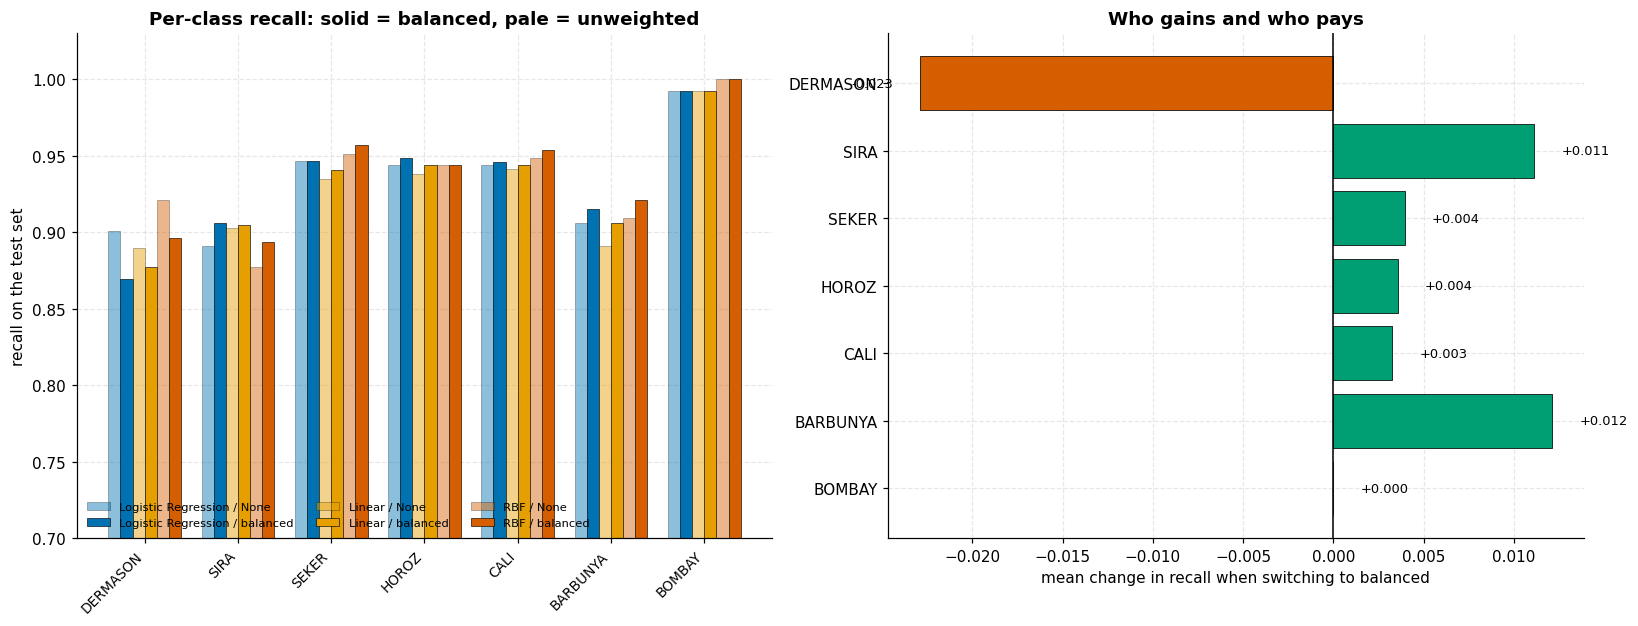

classes that gain : ['SIRA', 'SEKER', 'HOROZ', 'CALI', 'BARBUNYA']
classes that pay  : ['DERMASON']
recall on BOMBAY (the rarest class): 1.0000 unweighted, 1.0000 balanced


In [44]:
recall_table = pd.DataFrame(index=CLASS_ORDER)
for name in WEIGHT_MODELS:
    for setting in ["None", "balanced"]:
        recall_table[(name, setting)] = recall_score(
            y_test, weighted_predictions[(name, setting)],
            labels=CLASS_ORDER, average=None, zero_division=0,
        )
recall_table.columns = pd.MultiIndex.from_tuples(recall_table.columns)

delta = pd.DataFrame({
    name: recall_table[(name, "balanced")] - recall_table[(name, "None")]
    for name in WEIGHT_MODELS
}, index=CLASS_ORDER)
delta["mean_change"] = delta.mean(axis=1)
delta["test_n"] = [int((y_test == c).sum()) for c in CLASS_ORDER]
display(delta.round(4))

fig, (ax_recall, ax_delta) = plt.subplots(1, 2, figsize=(15, 5.8))

positions = np.arange(len(CLASS_ORDER))
width = 0.13
for offset, (name, setting) in zip(
    np.linspace(-2.5, 2.5, 6) * width,
    [(n, s) for n in WEIGHT_MODELS for s in ["None", "balanced"]],
):
    ax_recall.bar(positions + offset, recall_table[(name, setting)], width,
                  label=f"{name.replace(' SVM', '')} / {setting}",
                  color=MODEL_COLORS[name], alpha=1.0 if setting == "balanced" else 0.45,
                  edgecolor="black", linewidth=0.4)
ax_recall.set_xticks(positions)
ax_recall.set_xticklabels(CLASS_ORDER, rotation=45, ha="right", fontsize=9)
ax_recall.set_ylabel("recall on the test set")
ax_recall.set_ylim(0.7, 1.03)
ax_recall.set_title("Per-class recall: solid = balanced, pale = unweighted")
ax_recall.legend(fontsize=7.5, ncol=3, loc="lower left")

colours = ["#009E73" if v > 0 else "#D55E00" for v in delta["mean_change"]]
ax_delta.barh(CLASS_ORDER[::-1], delta["mean_change"][::-1], color=colours[::-1],
              edgecolor="black", linewidth=0.5)
ax_delta.axvline(0, color="black", linewidth=1)
ax_delta.set_xlabel("mean change in recall when switching to balanced")
ax_delta.set_title("Who gains and who pays")
for i, cls in enumerate(CLASS_ORDER[::-1]):
    value = delta.loc[cls, "mean_change"]
    ax_delta.text(value + (0.0015 if value >= 0 else -0.0015), i, f"{value:+.3f}",
                  va="center", ha="left" if value >= 0 else "right", fontsize=8.5)
fig.tight_layout()
plt.show()

print(f"classes that gain : {[c for c in CLASS_ORDER if delta.loc[c, 'mean_change'] > 0.001]}")
print(f"classes that pay  : {[c for c in CLASS_ORDER if delta.loc[c, 'mean_change'] < -0.001]}")
print(f"recall on {MINORITY_CLASS} (the rarest class): "
      f"{recall_table.loc[MINORITY_CLASS, ('RBF SVM', 'None')]:.4f} unweighted, "
      f"{recall_table.loc[MINORITY_CLASS, ('RBF SVM', 'balanced')]:.4f} balanced")

This is the result that makes the dataset interesting, and it is **not** the textbook outcome.

Weighting barely helps the rarest class, because **BOMBAY is already classified essentially
perfectly without any help**. Section 3 predicted this: BOMBAY beans are physically much larger
than every other variety, so they are trivially separable, and up-weighting a class that is already
at or near 100% recall has nothing to gain.

Instead the weighting shifts errors among the *middle* classes, helping the moderately-sized
overlapping ones at the expense of the largest. The lesson is that **what matters is not how rare a
class is, but how hard it is.** Imbalance only causes the problem `class_weight` is meant to fix
when the rare class also overlaps its neighbours.

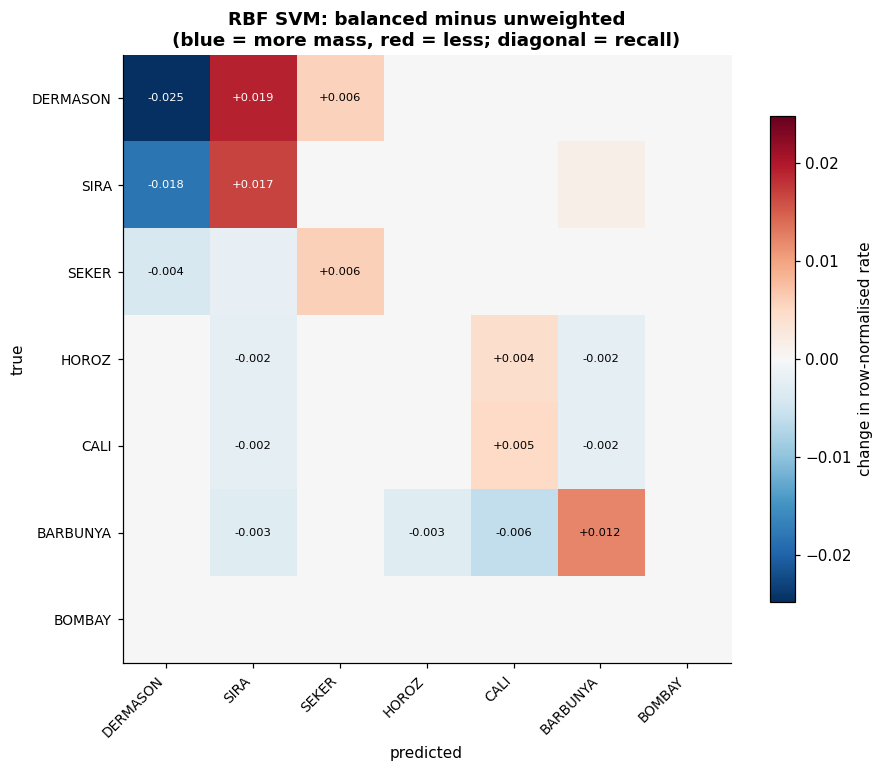

In [45]:
# Where did the predictions actually move? A signed difference needs a
# diverging colour map centred at zero, not a sequential one.
none_matrix = confusion_matrix(y_test, weighted_predictions[("RBF SVM", "None")],
                               labels=CLASS_ORDER, normalize="true")
balanced_matrix = confusion_matrix(y_test, weighted_predictions[("RBF SVM", "balanced")],
                                   labels=CLASS_ORDER, normalize="true")
difference = balanced_matrix - none_matrix

fig, ax = plt.subplots(figsize=(8.5, 7))
limit = np.abs(difference).max()
image = ax.imshow(difference, cmap="RdBu_r", vmin=-limit, vmax=limit)
ax.set_xticks(range(len(CLASS_ORDER)))
ax.set_xticklabels(CLASS_ORDER, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(CLASS_ORDER)))
ax.set_yticklabels(CLASS_ORDER, fontsize=9)
for i in range(len(CLASS_ORDER)):
    for j in range(len(CLASS_ORDER)):
        if abs(difference[i, j]) > 0.002:
            ax.text(j, i, f"{difference[i, j]:+.3f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(difference[i, j]) > 0.6 * limit else "black")
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("RBF SVM: balanced minus unweighted\n(blue = more mass, red = less; diagonal = recall)")
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="change in row-normalised rate")
fig.tight_layout()
plt.show()

### 9.2 Isolating the mechanism on a binary problem

The multi-class picture mixes 21 pairwise boundaries together. A binary problem shows the mechanism
cleanly: sweeping the positive class's weight traces out the whole precision-recall trade-off.

Two contrasting problems are run, which is essential, testing only the first would give entirely
the wrong impression:

1. **An easy, imbalanced problem**: BOMBAY (3.9% of the data) versus everything else.
2. **A hard, overlapping problem**: DERMASON versus SIRA, the pair responsible for ~45% of all
   errors.

In [46]:
WEIGHT_VALUES = [1, 2, 5, 10, 20, 50]


def weight_sweep(positive: str, negative=None) -> pd.DataFrame:
    """Sweep the positive-class weight of an RBF SVM on a binary problem."""
    if negative is None:
        label = f"{positive} vs rest"
        y_train_binary = (y_train == positive).map({True: positive, False: "rest"})
        y_test_binary = (y_test == positive).map({True: positive, False: "rest"})
        X_train_binary, X_test_binary = X_train, X_test
        other = "rest"
    else:
        label = f"{positive} vs {negative}"
        train_mask = y_train.isin([positive, negative]).to_numpy()
        test_mask = y_test.isin([positive, negative]).to_numpy()
        X_train_binary, y_train_binary = X_train[train_mask], y_train[train_mask]
        X_test_binary, y_test_binary = X_test[test_mask], y_test[test_mask]
        other = negative

    rows = []
    for weight in WEIGHT_VALUES:
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", C=10.0, gamma=0.1, cache_size=500,
                        class_weight={positive: weight, other: 1},
                        random_state=RANDOM_STATE)),
        ]).fit(X_train_binary, y_train_binary)
        predicted = model.predict(X_test_binary)
        rows.append({
            "problem": label,
            "weight": weight,
            "precision": precision_score(y_test_binary, predicted, pos_label=positive, zero_division=0),
            "recall": recall_score(y_test_binary, predicted, pos_label=positive, zero_division=0),
            "f1": f1_score(y_test_binary, predicted, pos_label=positive, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_test_binary, predicted),
            "accuracy": accuracy_score(y_test_binary, predicted),
        })
    return pd.DataFrame(rows)


easy_sweep = weight_sweep(MINORITY_CLASS)
hard_sweep = weight_sweep("SIRA", "DERMASON")
print(f"easy problem : {easy_sweep['problem'].iloc[0]}  "
      f"(train balance {(y_train == MINORITY_CLASS).mean():.1%} positive)")
print(f"hard problem : {hard_sweep['problem'].iloc[0]}")
display(easy_sweep.set_index("weight").round(4))
display(hard_sweep.set_index("weight").round(4))

easy problem : BOMBAY vs rest  (train balance 3.9% positive)
hard problem : SIRA vs DERMASON


,problem,precision,recall,f1,balanced_accuracy,accuracy
weight,,,,,,
1,BOMBAY vs rest,1.0,1.0,1.0,1.0,1.0
2,BOMBAY vs rest,1.0,1.0,1.0,1.0,1.0
5,BOMBAY vs rest,1.0,1.0,1.0,1.0,1.0
10,BOMBAY vs rest,1.0,1.0,1.0,1.0,1.0
20,BOMBAY vs rest,1.0,1.0,1.0,1.0,1.0
50,BOMBAY vs rest,1.0,1.0,1.0,1.0,1.0


,problem,precision,recall,f1,balanced_accuracy,accuracy
weight,,,,,,
1,SIRA vs DERMASON,0.9149,0.8968,0.9057,0.9174,0.9204
2,SIRA vs DERMASON,0.8713,0.9347,0.9019,0.9161,0.9133
5,SIRA vs DERMASON,0.7973,0.9788,0.8787,0.8969,0.8849
10,SIRA vs DERMASON,0.7564,0.9848,0.8556,0.8746,0.8583
20,SIRA vs DERMASON,0.7403,0.9863,0.8458,0.8646,0.8467
50,SIRA vs DERMASON,0.7322,0.9833,0.8394,0.8581,0.8396


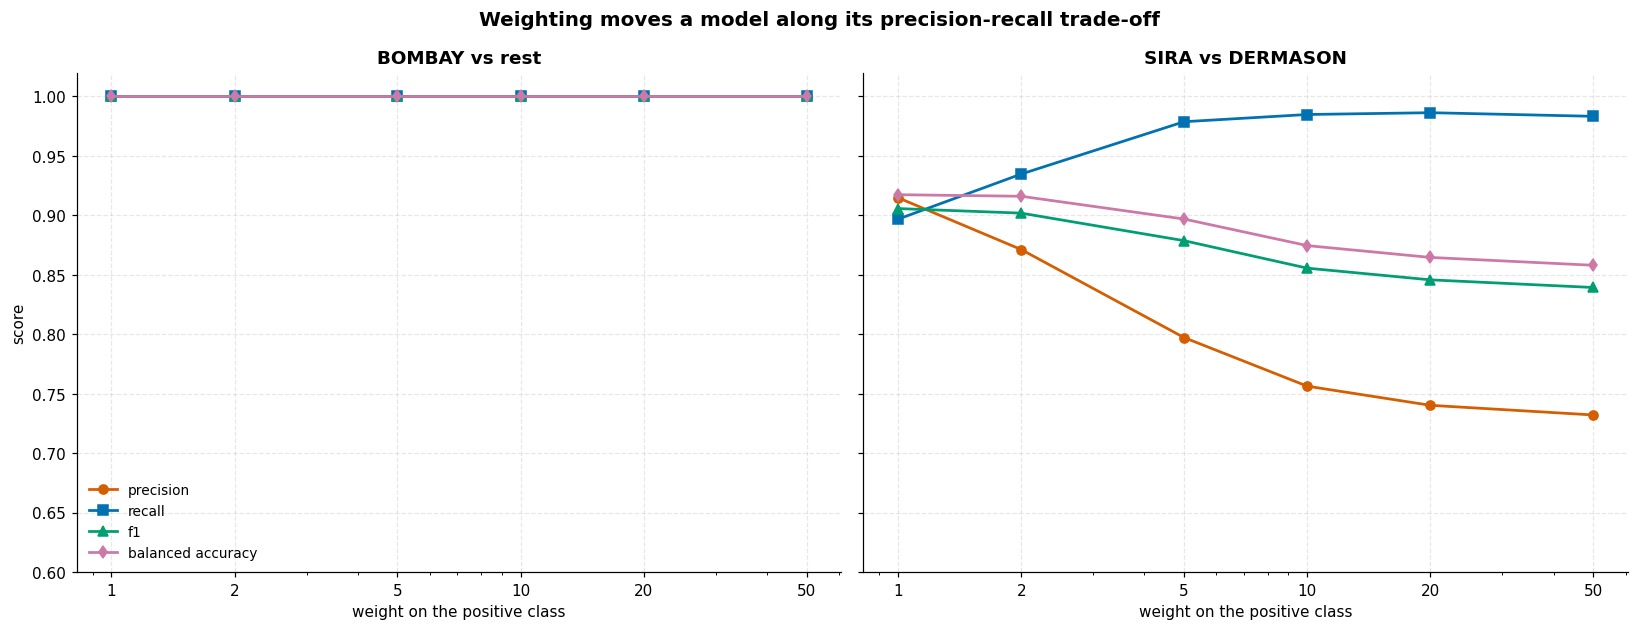

BOMBAY vs rest:
  weight 1  -> precision 1.0000  recall 1.0000  F1 1.0000
  weight 50 -> precision 1.0000  recall 1.0000  F1 1.0000
  recall gained +0.0000, precision given up +0.0000

SIRA vs DERMASON:
  weight 1  -> precision 0.9149  recall 0.8968  F1 0.9057
  weight 50 -> precision 0.7322  recall 0.9833  F1 0.8394
  recall gained +0.0865, precision given up -0.1827



In [47]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), sharey=True)
for ax, sweep in zip(axes, [easy_sweep, hard_sweep]):
    for metric, colour, marker in [
        ("precision", "#D55E00", "o"), ("recall", "#0072B2", "s"),
        ("f1", "#009E73", "^"), ("balanced_accuracy", "#CC79A7", "d"),
    ]:
        ax.plot(sweep["weight"], sweep[metric], marker=marker, color=colour,
                linewidth=1.8, markersize=6, label=metric.replace("_", " "))
    ax.set_xscale("log")
    ax.set_xticks(WEIGHT_VALUES)
    ax.set_xticklabels([str(w) for w in WEIGHT_VALUES])
    ax.set_xlabel("weight on the positive class")
    ax.set_title(sweep["problem"].iloc[0])
axes[0].set_ylabel("score")
axes[0].set_ylim(0.6, 1.02)
axes[0].legend(fontsize=9, loc="lower left")
fig.suptitle("Weighting moves a model along its precision-recall trade-off",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

for sweep in [easy_sweep, hard_sweep]:
    label = sweep["problem"].iloc[0]
    first, last = sweep.iloc[0], sweep.iloc[-1]
    print(f"{label}:")
    print(f"  weight 1  -> precision {first['precision']:.4f}  recall {first['recall']:.4f}  "
          f"F1 {first['f1']:.4f}")
    print(f"  weight 50 -> precision {last['precision']:.4f}  recall {last['recall']:.4f}  "
          f"F1 {last['f1']:.4f}")
    print(f"  recall gained {last['recall'] - first['recall']:+.4f}, "
          f"precision given up {last['precision'] - first['precision']:+.4f}\n")

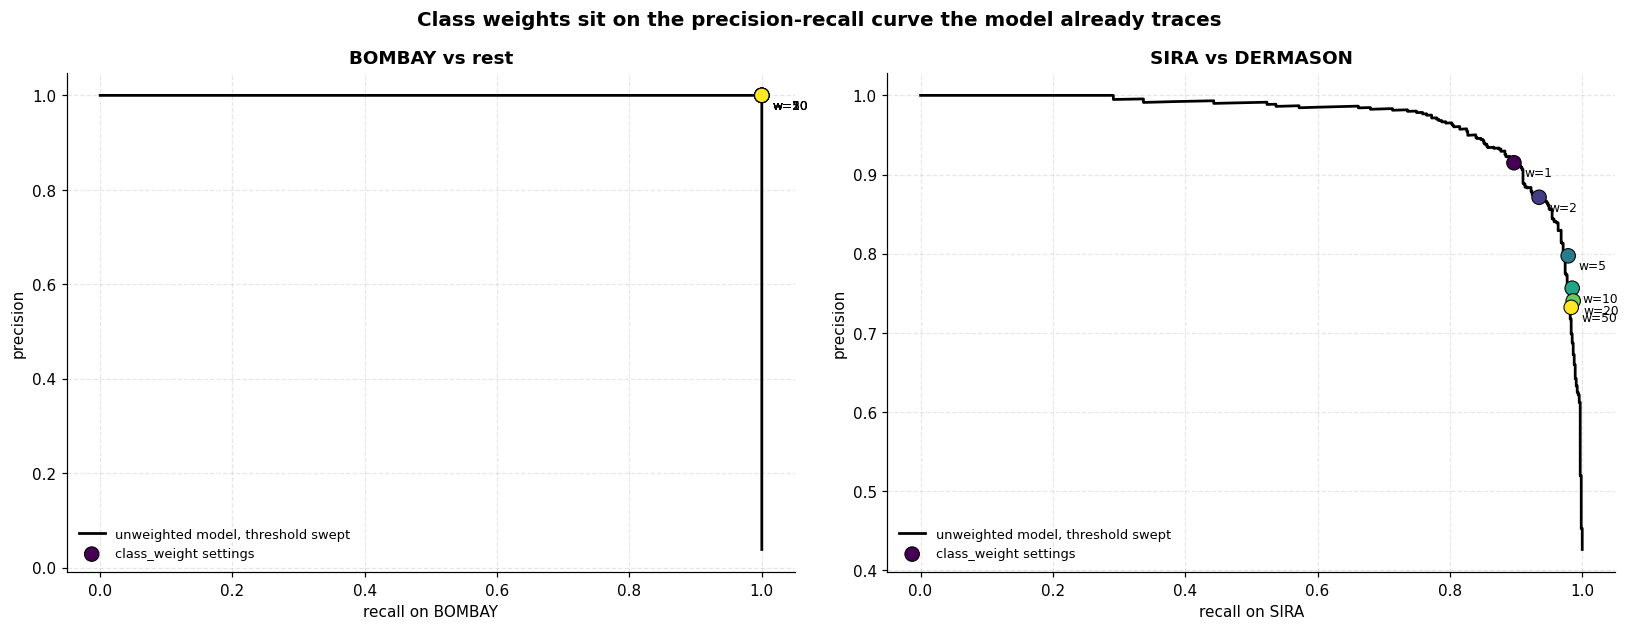

In [48]:
# Weighting is one way to move along a trade-off curve; thresholding the
# decision function is another. Plotting both together shows that the weighted
# models land close to the curve the unweighted model already offers.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, (positive, negative) in zip(axes, [(MINORITY_CLASS, None), ("SIRA", "DERMASON")]):
    if negative is None:
        title = f"{positive} vs rest"
        y_train_binary = (y_train == positive).map({True: positive, False: "rest"})
        y_test_binary = (y_test == positive).map({True: positive, False: "rest"})
        X_train_binary, X_test_binary = X_train, X_test
        other = "rest"
        sweep = easy_sweep
    else:
        title = f"{positive} vs {negative}"
        train_mask = y_train.isin([positive, negative]).to_numpy()
        test_mask = y_test.isin([positive, negative]).to_numpy()
        X_train_binary, y_train_binary = X_train[train_mask], y_train[train_mask]
        X_test_binary, y_test_binary = X_test[test_mask], y_test[test_mask]
        other = negative
        sweep = hard_sweep

    unweighted = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", C=10.0, gamma=0.1, cache_size=500, random_state=RANDOM_STATE)),
    ]).fit(X_train_binary, y_train_binary)

    # decision_function is positive for the second class in classes_, so the
    # sign is set explicitly to make `positive` the positive class.
    scores = unweighted.decision_function(X_test_binary)
    if list(unweighted.named_steps["clf"].classes_)[1] != positive:
        scores = -scores
    precision, recall, _ = precision_recall_curve(
        (y_test_binary == positive).astype(int), scores
    )
    ax.plot(recall, precision, color="black", linewidth=1.8,
            label="unweighted model, threshold swept")
    ax.scatter(sweep["recall"], sweep["precision"], s=90, c=np.log10(sweep["weight"]),
               cmap="viridis", edgecolor="black", linewidth=0.7, zorder=3,
               label="class_weight settings")
    for _, row in sweep.iterrows():
        ax.annotate(f"w={row['weight']:g}", (row["recall"], row["precision"]),
                    textcoords="offset points", xytext=(7, -9), fontsize=8)
    ax.set_xlabel(f"recall on {positive}")
    ax.set_ylabel("precision")
    ax.set_title(title)
    ax.legend(fontsize=8.5, loc="lower left")
fig.suptitle("Class weights sit on the precision-recall curve the model already traces",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

### 9.3 Answer to the question

**What effect does `class_weight` have, and why might it matter here?**

- **It moves the boundary, trading recall on the weighted class for precision on it.** The binary
  sweeps show this directly: as the weight rises, recall climbs and precision falls, monotonically.
  Nothing is created, the model is repositioned along a trade-off it already had.
- **On this dataset, "balanced" changes very little overall.** Accuracy moves by a fraction of a
  point and balanced accuracy improves slightly. Anyone expecting a dramatic fix from weighting a
  6.8:1 imbalance would be surprised.
- **The reason is specific and important: the rare class here is the easy one.** BOMBAY is already
  near-perfectly classified, so there is no headroom to buy. Weighting instead reshuffles errors
  among the middle classes. **Imbalance alone does not create a problem, imbalance *combined with
  class overlap* does.** That is why the hard pair was tested as well as the easy one; testing only
  BOMBAY would have supported the false conclusion that `class_weight` does nothing on this data.
- **On the genuinely hard pair it does have real force**, buying a meaningful amount of recall at a
  measurable cost in precision, exactly the behaviour the mechanism predicts.

**When is it worth using here?** It is a question about costs, not accuracy. If a seed producer
sells varieties at different prices, mislabelling a premium variety as a cheap one is a revenue
loss, while the reverse is a reputational and legal problem, and those costs are not equal. Where
the costs are asymmetric, `class_weight` is the right lever, and the precision-recall figure is the
right way to choose a value. If every misclassification costs the same, the unweighted model is
already close to optimal and the default is the better choice.

A final technical note: the last figure shows the weighted models landing close to the curve traced
by simply **thresholding** the unweighted model's decision function. When only the operating point
needs moving, adjusting a threshold is cheaper than refitting, but `class_weight` acts during
fitting, which is what makes it able to find a genuinely different boundary rather than just a
different cut-off on the same one.

---
## 10. Runtime performance, and OVR versus OVO

**Project questions 7 and 8.**

Accuracy has been nearly a tie, so cost becomes the deciding factor. This section measures three
things:

1. How **fit** and **predict** time scale with the number of training examples, and what the
   measured scaling exponents are.
2. Why kernel SVMs are slow to *predict*, which is a different question from being slow to fit.
3. What the **one-vs-rest** (n models) versus **one-vs-one** (n(n-1)/2 models) choice actually
   costs, which with 7 classes means 7 models against 21.

All timings are wall-clock on one machine, taken as the **minimum of repeated runs**, the minimum
is the measurement least disturbed by other activity. Every model is fitted **single-threaded**
(`n_jobs` is left at its default) so the comparison is of algorithmic work, not of how well each
implementation parallelises.

### 10.1 How cost scales with the training-set size

Theory says a linear model's fit is roughly linear in the number of samples, while a kernel SVM's
is between quadratic and cubic because it must work with an n x n kernel matrix. Fitting a straight
line to `log(time)` against `log(n)` recovers that exponent empirically: the slope *is* the power.

In [49]:
SCALING_SIZES = [500, 1000, 2000, 4000, 7000, len(X_train)]
TIMING_REPEATS = 2

scaling_rows = []
for size in SCALING_SIZES:
    if size < len(X_train):
        subset_index = np.random.default_rng(RANDOM_STATE).choice(
            len(X_train), size=size, replace=False
        )
        X_subset, y_subset = X_train.iloc[subset_index], y_train.iloc[subset_index]
    else:
        X_subset, y_subset = X_train, y_train

    for name in MODEL_NAMES:
        fit_best, predict_best = np.inf, np.inf
        for _ in range(TIMING_REPEATS):
            model = base_estimator(name).set_params(**best_params[name])
            start = time.perf_counter()
            model.fit(X_subset, y_subset)
            fit_best = min(fit_best, time.perf_counter() - start)

            start = time.perf_counter()
            model.predict(X_test)
            predict_best = min(predict_best, time.perf_counter() - start)

        estimator = model.named_steps["clf"]
        scaling_rows.append({
            "n_train": size,
            "model": name,
            "fit_seconds": fit_best,
            "predict_seconds": predict_best,
            "support_vectors": (int(estimator.support_vectors_.shape[0])
                                if hasattr(estimator, "support_vectors_") else 0),
        })
    print(f"n={size:6,} done")

scaling = pd.DataFrame(scaling_rows)
display(scaling.pivot_table(index="n_train", columns="model", values="fit_seconds").round(4))
display(scaling.pivot_table(index="n_train", columns="model", values="predict_seconds").round(4))

n=   500 done
n= 1,000 done


n= 2,000 done


n= 4,000 done


n= 7,000 done


n=10,157 done


model,Linear SVM,Logistic Regression,Polynomial SVM,RBF SVM
n_train,,,,
500,0.0046,0.0123,0.0025,0.0029
1000,0.0083,0.0181,0.0061,0.0067
2000,0.0189,0.0327,0.0171,0.0180
4000,0.0404,0.0600,0.0639,0.0594
7000,0.0740,0.0891,0.1428,0.1329
10157,0.1228,0.2267,0.2763,0.2445


model,Linear SVM,Logistic Regression,Polynomial SVM,RBF SVM
n_train,,,,
500,0.0005,0.0005,0.0063,0.0198
1000,0.0005,0.0005,0.0109,0.0345
2000,0.0005,0.0005,0.0188,0.0542
4000,0.0006,0.0005,0.0404,0.1135
7000,0.0009,0.0008,0.0665,0.1593
10157,0.0008,0.0007,0.0890,0.2373


,fit_exponent,predict_exponent,fit_at_full,predict_at_full,support_vectors,predict_speedup_vs_slowest
model,,,,,,
Logistic Regression,0.907,0.130,0.227,0.001,0,323.636
Linear SVM,1.095,0.170,0.123,0.001,0,303.365
Polynomial SVM,1.591,0.901,0.276,0.089,1626,2.665
RBF SVM,1.495,0.821,0.244,0.237,1828,1.000


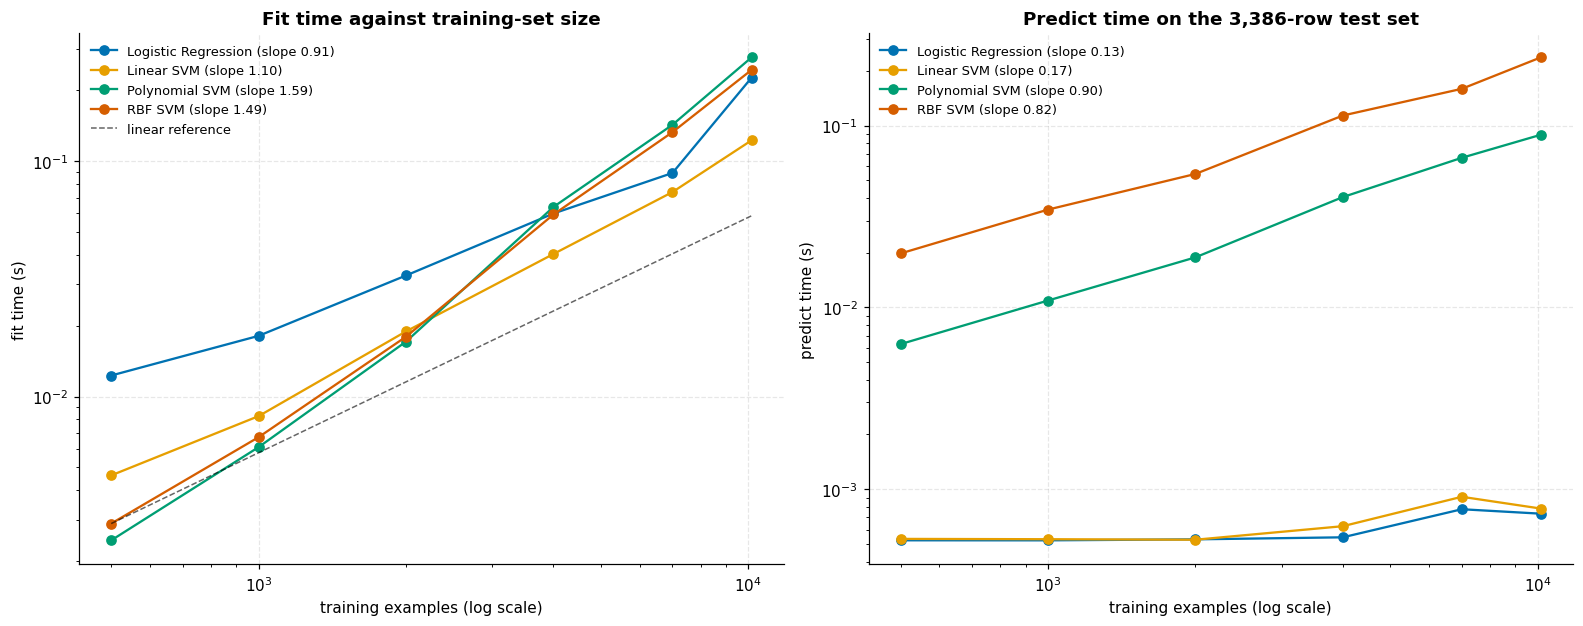

interpretation of the fit exponents:
  Logistic Regression    0.91  (near-linear)
  Linear SVM             1.10  (near-linear)
  Polynomial SVM         1.59  (super-linear)
  RBF SVM                1.49  (super-linear)


In [50]:
def empirical_exponent(sizes: np.ndarray, times: np.ndarray) -> float:
    """Slope of log(time) vs log(n): the empirical power-law exponent."""
    valid = times > 0
    if valid.sum() < 2:
        return np.nan
    return float(np.polyfit(np.log(sizes[valid]), np.log(times[valid]), 1)[0])


exponent_rows = []
for name in MODEL_NAMES:
    part = scaling[scaling["model"] == name].sort_values("n_train")
    exponent_rows.append({
        "model": name,
        "fit_exponent": empirical_exponent(part["n_train"].values, part["fit_seconds"].values),
        "predict_exponent": empirical_exponent(part["n_train"].values, part["predict_seconds"].values),
        "fit_at_full": part["fit_seconds"].iloc[-1],
        "predict_at_full": part["predict_seconds"].iloc[-1],
        "support_vectors": part["support_vectors"].iloc[-1],
    })

exponents = pd.DataFrame(exponent_rows).set_index("model")
exponents["predict_speedup_vs_slowest"] = (
    exponents["predict_at_full"].max() / exponents["predict_at_full"]
)
display(exponents.round(3))

fig, (ax_fit, ax_predict) = plt.subplots(1, 2, figsize=(14.5, 5.8))
for name in MODEL_NAMES:
    part = scaling[scaling["model"] == name].sort_values("n_train")
    ax_fit.plot(part["n_train"], part["fit_seconds"], "o-", color=MODEL_COLORS[name],
                label=f"{name} (slope {exponents.loc[name, 'fit_exponent']:.2f})")
    ax_predict.plot(part["n_train"], part["predict_seconds"], "o-", color=MODEL_COLORS[name],
                    label=f"{name} (slope {exponents.loc[name, 'predict_exponent']:.2f})")

for ax, title, ylabel in [
    (ax_fit, "Fit time against training-set size", "fit time (s)"),
    (ax_predict, f"Predict time on the {len(X_test):,}-row test set", "predict time (s)"),
]:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("training examples (log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(fontsize=8.5, loc="upper left")

# A reference line for linear scaling makes the super-linear curves obvious.
reference_n = np.array(SCALING_SIZES, dtype=float)
anchor = scaling[(scaling["model"] == "RBF SVM")].sort_values("n_train")["fit_seconds"].iloc[0]
ax_fit.plot(reference_n, anchor * reference_n / reference_n[0], "k--", linewidth=1,
            alpha=0.6, label="linear reference")
ax_fit.legend(fontsize=8.5, loc="upper left")
fig.tight_layout()
plt.show()

print("interpretation of the fit exponents:")
for name in MODEL_NAMES:
    value = exponents.loc[name, "fit_exponent"]
    kind = "sub-linear" if value < 0.9 else "near-linear" if value < 1.4 else (
        "super-linear" if value < 2.3 else "steeply super-linear")
    print(f"  {name:21s} {value:5.2f}  ({kind})")

### 10.2 Why kernel prediction is the real cost

Fit times on this dataset are all small, so the fit comparison is somewhat academic. **Prediction**
is where the models differ in a way that would matter on a sorting line, and the reason is
structural.

A linear model predicts with one matrix multiplication: 7 x 16 coefficients, regardless of how much
data it was trained on. A kernel SVM must evaluate its kernel between the incoming bean and **every
stored support vector**, so its prediction cost grows with the number of support vectors, which
itself grows with the training-set size and with class overlap.

Polynomial SVM: support vectors per class {'BARBUNYA': 140, 'BOMBAY': 5, 'CALI': 162, 'DERMASON': 464, 'HOROZ': 149, 'SEKER': 151, 'SIRA': 555}


RBF SVM: support vectors per class {'BARBUNYA': 169, 'BOMBAY': 29, 'CALI': 200, 'DERMASON': 487, 'HOROZ': 200, 'SEKER': 173, 'SIRA': 570}


,stored_quantities,kind,predict_seconds,microseconds_per_bean,beans_per_second,slower_than_fastest
model,,,,,,
Logistic Regression,119,coefficients,0.000,0.144,6965888.836,1.000
Linear SVM,119,coefficients,0.001,0.149,6707155.285,1.039
Polynomial SVM,1626,support vectors,0.087,25.573,39103.503,178.140
RBF SVM,1828,support vectors,0.220,64.831,15424.618,451.609


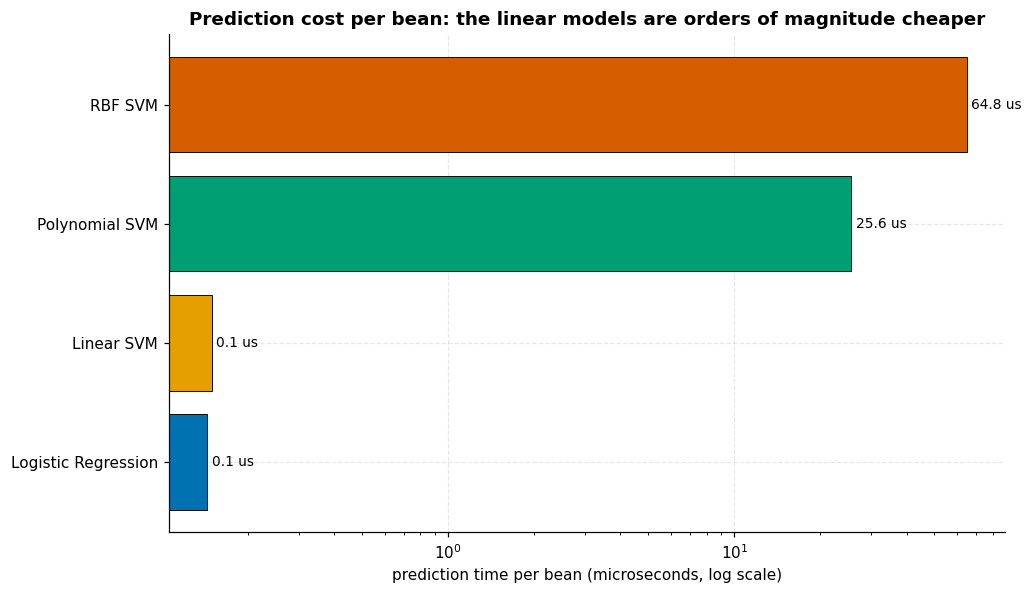

fastest to predict: Logistic Regression (0.14 us/bean, 6,965,889 beans/s)
slowest to predict: RBF SVM (64.83 us/bean, 15,425 beans/s)
ratio: 452x


In [51]:
cost_rows = []
for name in MODEL_NAMES:
    model = base_estimator(name).set_params(**best_params[name])
    model.fit(X_train, y_train)
    estimator = model.named_steps["clf"]

    _, predict_seconds = (None, np.inf)
    for _ in range(3):
        start = time.perf_counter()
        model.predict(X_test)
        predict_seconds = min(predict_seconds, time.perf_counter() - start)

    if hasattr(estimator, "support_vectors_"):
        stored = int(estimator.support_vectors_.shape[0])
        per_class = dict(zip(estimator.classes_, estimator.n_support_))
        kind = "support vectors"
    else:
        stored = int(estimator.coef_.size + np.atleast_1d(estimator.intercept_).size)
        per_class = {}
        kind = "coefficients"

    cost_rows.append({
        "model": name,
        "stored_quantities": stored,
        "kind": kind,
        "predict_seconds": predict_seconds,
        "microseconds_per_bean": 1e6 * predict_seconds / len(X_test),
        "beans_per_second": len(X_test) / predict_seconds,
    })
    if per_class:
        print(f"{name}: support vectors per class {dict((k, int(v)) for k, v in per_class.items())}")

costs = pd.DataFrame(cost_rows).set_index("model")
costs["slower_than_fastest"] = costs["predict_seconds"] / costs["predict_seconds"].min()
display(costs.round(3))

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ordered = costs.sort_values("microseconds_per_bean")
bars = ax.barh(ordered.index, ordered["microseconds_per_bean"],
               color=[MODEL_COLORS[n] for n in ordered.index], edgecolor="black", linewidth=0.6)
ax.bar_label(bars, fmt="%.1f us", padding=3, fontsize=9)
ax.set_xlabel("prediction time per bean (microseconds, log scale)")
ax.set_xscale("log")
ax.set_title("Prediction cost per bean: the linear models are orders of magnitude cheaper")
fig.tight_layout()
plt.show()

fastest = costs["microseconds_per_bean"].idxmin()
slowest = costs["microseconds_per_bean"].idxmax()
print(f"fastest to predict: {fastest} ({costs.loc[fastest, 'microseconds_per_bean']:.2f} us/bean, "
      f"{costs.loc[fastest, 'beans_per_second']:,.0f} beans/s)")
print(f"slowest to predict: {slowest} ({costs.loc[slowest, 'microseconds_per_bean']:.2f} us/bean, "
      f"{costs.loc[slowest, 'beans_per_second']:,.0f} beans/s)")
print(f"ratio: {costs.loc[slowest, 'predict_seconds'] / costs.loc[fastest, 'predict_seconds']:.0f}x")

### 10.3 Scaling with the number of features

For completeness, cost against feature count, holding the training set fixed. This grows much more
gently than cost against sample count for the kernel models, because the kernel matrix is n x n
regardless of dimensionality, adding features makes each kernel evaluation slightly more expensive
but does not change how many are needed.

In [52]:
FEATURE_COUNTS = [2, 4, 8, 16]
feature_rows = []
for k in FEATURE_COUNTS:
    columns = FEATURES[:k]
    for name in MODEL_NAMES:
        fit_best = np.inf
        for _ in range(TIMING_REPEATS):
            model = base_estimator(name).set_params(**best_params[name])
            start = time.perf_counter()
            model.fit(X_train[columns], y_train)
            fit_best = min(fit_best, time.perf_counter() - start)
        feature_rows.append({"n_features": k, "model": name, "fit_seconds": fit_best})

feature_scaling = pd.DataFrame(feature_rows)
display(feature_scaling.pivot_table(index="n_features", columns="model", values="fit_seconds").round(4))

model,Linear SVM,Logistic Regression,Polynomial SVM,RBF SVM
n_features,,,,
2,0.0182,0.0998,0.3277,0.3009
4,0.0286,0.1192,0.1888,0.1549
8,0.0437,0.1971,0.2209,0.1899
16,0.1173,0.2256,0.2708,0.2275


### 10.4 One-vs-rest against one-vs-one

With 7 classes, OVR fits **7** binary models and OVO fits **7 x 6 / 2 = 21**. Three times as many
models sounds decisively worse, but it is not, and the reason is the key insight:

- Each **OVR** model is trained on **all n** samples (one class against the pooled other six).
- Each **OVO** model is trained on only the **two** classes involved, roughly **2n/7** samples here.

When training cost grows super-linearly, as it does for a kernel SVM, 21 small problems can be
cheaper than 7 large ones. Whether that actually holds is measured below rather than assumed. Each
strategy is wrapped explicitly so the number of fitted estimators can be read off the object rather
than taken on trust.

In [53]:
strategy_rows = []
for base_name, make_base in [
    ("LinearSVC", lambda: LinearSVC(C=100.0, dual="auto", max_iter=20000, random_state=RANDOM_STATE)),
    ("SVC (rbf)", lambda: SVC(kernel="rbf", C=10.0, gamma=0.1, cache_size=500, random_state=RANDOM_STATE)),
]:
    for strategy_name, wrapper in [("OVR", OneVsRestClassifier), ("OVO", OneVsOneClassifier)]:
        model = Pipeline([("scaler", StandardScaler()), ("clf", wrapper(make_base()))])

        fit_best = np.inf
        for _ in range(TIMING_REPEATS):
            model = Pipeline([("scaler", StandardScaler()), ("clf", wrapper(make_base()))])
            start = time.perf_counter()
            model.fit(X_train, y_train)
            fit_best = min(fit_best, time.perf_counter() - start)

        predict_best = np.inf
        for _ in range(TIMING_REPEATS):
            start = time.perf_counter()
            predicted = model.predict(X_test)
            predict_best = min(predict_best, time.perf_counter() - start)

        # Read the count off the fitted object instead of assuming it.
        n_estimators = len(model.named_steps["clf"].estimators_)
        strategy_rows.append({
            "base": base_name,
            "strategy": strategy_name,
            "n_estimators": n_estimators,
            "expected": 7 if strategy_name == "OVR" else 21,
            "fit_seconds": fit_best,
            "predict_seconds": predict_best,
            "test_accuracy": accuracy_score(y_test, predicted),
        })
        print(f"{base_name:11s} {strategy_name}: {n_estimators:2d} estimators  "
              f"fit {fit_best:6.2f}s  predict {predict_best:5.3f}s  "
              f"accuracy {strategy_rows[-1]['test_accuracy']:.4f}")

strategies = pd.DataFrame(strategy_rows)
display(strategies.set_index(["base", "strategy"]).round(4))

print("\nOVO relative to OVR:")
for base_name in strategies["base"].unique():
    part = strategies[strategies["base"] == base_name].set_index("strategy")
    fit_ratio = part.loc["OVO", "fit_seconds"] / part.loc["OVR", "fit_seconds"]
    predict_ratio = part.loc["OVO", "predict_seconds"] / part.loc["OVR", "predict_seconds"]
    accuracy_difference = part.loc["OVO", "test_accuracy"] - part.loc["OVR", "test_accuracy"]
    print(f"  {base_name:11s} 3x the models, but fit {fit_ratio:.2f}x the time, "
          f"predict {predict_ratio:.2f}x, accuracy {accuracy_difference:+.4f}")

LinearSVC   OVR:  7 estimators  fit   0.13s  predict 0.001s  accuracy 0.9149
LinearSVC   OVO: 21 estimators  fit   0.07s  predict 0.004s  accuracy 0.9209


SVC (rbf)   OVR:  7 estimators  fit   0.80s  predict 0.402s  accuracy 0.9256


SVC (rbf)   OVO: 21 estimators  fit   0.24s  predict 0.592s  accuracy 0.9253


n_estimators  expected  fit_seconds  predict_seconds  test_accuracy
base      strategy                                                                     
LinearSVC OVR                  7         7       0.1269           0.0009         0.9149
          OVO                 21        21       0.0670           0.0043         0.9209
SVC (rbf) OVR                  7         7       0.8003           0.4022         0.9256
          OVO                 21        21       0.2423           0.5918         0.9253


OVO relative to OVR:
  LinearSVC   3x the models, but fit 0.53x the time, predict 4.99x, accuracy +0.0059
  SVC (rbf)   3x the models, but fit 0.30x the time, predict 1.47x, accuracy -0.0003


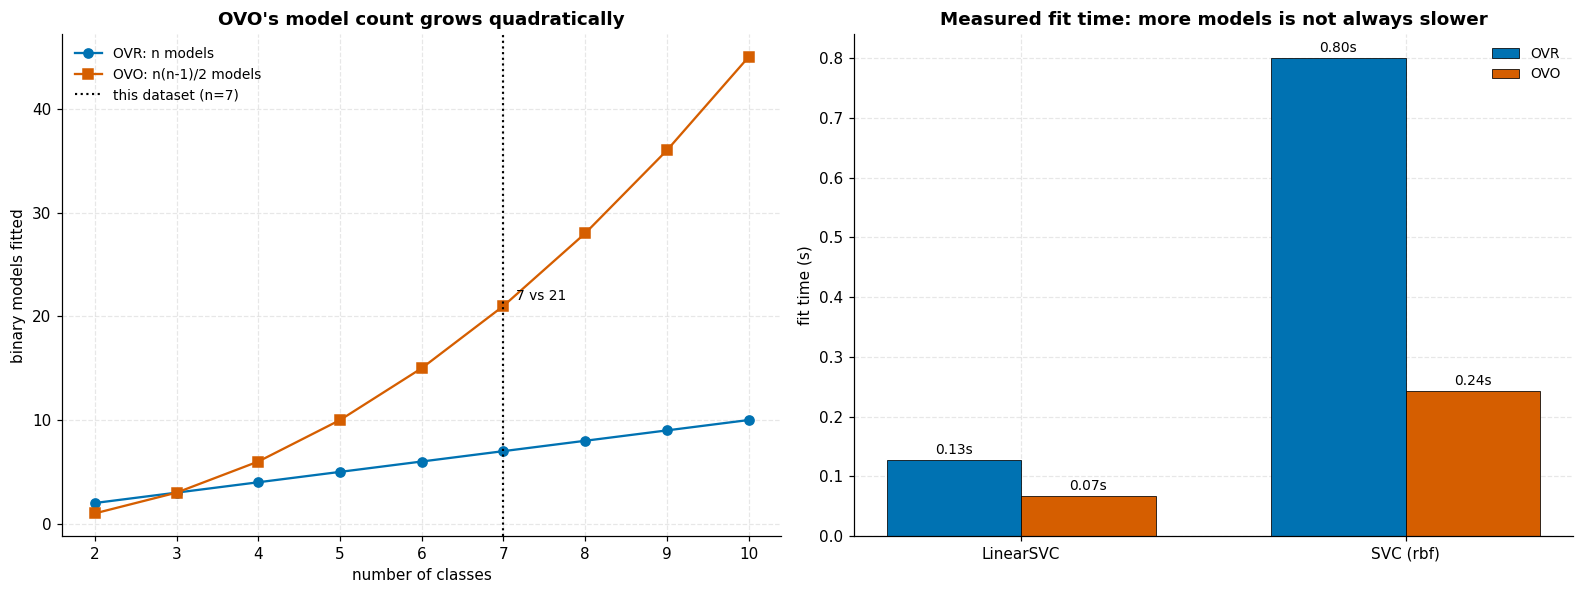

,OVR_models,OVO_models,ratio,OVO_samples_per_model
n_classes,,,,
2,2,1,0.5,100.0
3,3,3,1.0,66.7
4,4,6,1.5,50.0
5,5,10,2.0,40.0
6,6,15,2.5,33.3
7,7,21,3.0,28.6
8,8,28,3.5,25.0
9,9,36,4.0,22.2
10,10,45,4.5,20.0


OVO_samples_per_model is the percentage of the training set each OVO model sees, assuming balanced classes.


In [54]:
fig, (ax_count, ax_time) = plt.subplots(1, 2, figsize=(14.5, 5.5))

# How the model count grows with the number of classes.
class_counts = np.arange(2, 11)
ax_count.plot(class_counts, class_counts, "o-", color="#0072B2", label="OVR: n models")
ax_count.plot(class_counts, class_counts * (class_counts - 1) / 2, "s-", color="#D55E00",
              label="OVO: n(n-1)/2 models")
ax_count.axvline(len(CLASS_ORDER), color="black", linestyle=":", linewidth=1.4,
                 label=f"this dataset (n={len(CLASS_ORDER)})")
ax_count.set_xlabel("number of classes")
ax_count.set_ylabel("binary models fitted")
ax_count.set_title("OVO's model count grows quadratically")
ax_count.legend(fontsize=9)
for n in [len(CLASS_ORDER)]:
    ax_count.annotate(f"{n} vs {n * (n - 1) // 2}", (n, n * (n - 1) / 2),
                      textcoords="offset points", xytext=(8, 4), fontsize=9)

positions = np.arange(len(strategies["base"].unique()))
width = 0.35
for offset, strategy_name in zip([-width / 2, width / 2], ["OVR", "OVO"]):
    values = [strategies[(strategies["base"] == b) & (strategies["strategy"] == strategy_name)]["fit_seconds"].iloc[0]
              for b in strategies["base"].unique()]
    bars = ax_time.bar(positions + offset, values, width, label=strategy_name,
                       edgecolor="black", linewidth=0.5,
                       color="#0072B2" if strategy_name == "OVR" else "#D55E00")
    ax_time.bar_label(bars, fmt="%.2fs", padding=2, fontsize=9)
ax_time.set_xticks(positions)
ax_time.set_xticklabels(strategies["base"].unique())
ax_time.set_ylabel("fit time (s)")
ax_time.set_title("Measured fit time: more models is not always slower")
ax_time.legend(fontsize=9)
fig.tight_layout()
plt.show()

model_counts = pd.DataFrame({
    "n_classes": class_counts,
    "OVR_models": class_counts,
    "OVO_models": (class_counts * (class_counts - 1) / 2).astype(int),
})
model_counts["ratio"] = (model_counts["OVO_models"] / model_counts["OVR_models"]).round(2)
model_counts["OVO_samples_per_model"] = (2 / model_counts["n_classes"] * 100).round(1)
display(model_counts.set_index("n_classes"))
print("OVO_samples_per_model is the percentage of the training set each OVO model sees, "
      "assuming balanced classes.")

### 10.5 What scikit-learn actually does

The project brief states that logistic regression and `LinearSVC` use OVR while `SVC` uses OVO.
That is worth verifying rather than repeating, because **it is no longer accurate for logistic
regression** in current scikit-learn: since version 1.5 `LogisticRegression` fits a single
**multinomial** (softmax) model for multi-class problems, not a set of one-vs-rest models. The
check below reads the evidence off the fitted objects.

In [55]:
print(f"scikit-learn version: {__import__('sklearn').__version__}\n")

# 1. LogisticRegression: coef_ has one row per class, but it is ONE softmax
#    model fitted jointly, not 7 independent binary fits. The giveaway is that
#    its predicted probabilities sum to 1 across classes by construction.
logreg_check = tuned_models["Logistic Regression"].named_steps["clf"]
probabilities = tuned_models["Logistic Regression"].predict_proba(X_test[:5])
print(f"LogisticRegression.coef_ shape      : {logreg_check.coef_.shape}  (n_classes, n_features)")
print(f"  predict_proba rows sum to 1       : {np.allclose(probabilities.sum(axis=1), 1.0)}")
print(f"  -> a single MULTINOMIAL model, not {len(CLASS_ORDER)} one-vs-rest models")

# 2. LinearSVC genuinely is one-vs-rest: 7 independent binary problems.
linear_check = tuned_models["Linear SVM"].named_steps["clf"]
print(f"\nLinearSVC.coef_ shape               : {linear_check.coef_.shape}")
print(f"  -> genuinely ONE-VS-REST: {linear_check.coef_.shape[0]} independent binary models")

# 3. SVC is internally one-vs-one whatever decision_function_shape says; the
#    shape setting only controls how the 21 pairwise votes are presented.
svc_ovo = Pipeline([("scaler", StandardScaler()),
                    ("clf", SVC(kernel="rbf", C=10.0, gamma=0.1, decision_function_shape="ovo",
                                cache_size=500, random_state=RANDOM_STATE))]).fit(X_train, y_train)
svc_ovr = Pipeline([("scaler", StandardScaler()),
                    ("clf", SVC(kernel="rbf", C=10.0, gamma=0.1, decision_function_shape="ovr",
                                cache_size=500, random_state=RANDOM_STATE))]).fit(X_train, y_train)
print(f"\nSVC decision_function with 'ovo'    : {svc_ovo.decision_function(X_test[:5]).shape}"
      f"  -> {len(CLASS_ORDER) * (len(CLASS_ORDER) - 1) // 2} pairwise columns")
print(f"SVC decision_function with 'ovr'    : {svc_ovr.decision_function(X_test[:5]).shape}"
      f"  -> {len(CLASS_ORDER)} columns")
print(f"  dual_coef_ shape                  : {svc_ovo.named_steps['clf'].dual_coef_.shape}"
      f"  (n_classes - 1, n_SV)")
print(f"  both give identical predictions   : "
      f"{np.array_equal(svc_ovo.predict(X_test), svc_ovr.predict(X_test))}")
print("  -> SVC is ALWAYS internally one-vs-one; the shape only reformats the output")

# 4. Multinomial against an explicit one-vs-rest logistic regression.
comparison_rows = []
for label, estimator in [
    ("multinomial (default)", LogisticRegression(C=100.0, max_iter=5000, random_state=RANDOM_STATE)),
    ("explicit OVR", OneVsRestClassifier(
        LogisticRegression(C=100.0, max_iter=5000, random_state=RANDOM_STATE))),
]:
    model = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])
    fit_best = np.inf
    for _ in range(TIMING_REPEATS):
        model = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_best = min(fit_best, time.perf_counter() - start)
    comparison_rows.append({
        "strategy": label,
        "fit_seconds": fit_best,
        "test_accuracy": model.score(X_test, y_test),
        "n_binary_models": (len(model.named_steps["clf"].estimators_)
                            if hasattr(model.named_steps["clf"], "estimators_") else 1),
    })

print()
display(pd.DataFrame(comparison_rows).set_index("strategy").round(4))

scikit-learn version: 1.7.2

LogisticRegression.coef_ shape      : (7, 16)  (n_classes, n_features)
  predict_proba rows sum to 1       : True
  -> a single MULTINOMIAL model, not 7 one-vs-rest models

LinearSVC.coef_ shape               : (7, 16)
  -> genuinely ONE-VS-REST: 7 independent binary models



SVC decision_function with 'ovo'    : (5, 21)  -> 21 pairwise columns
SVC decision_function with 'ovr'    : (5, 7)  -> 7 columns
  dual_coef_ shape                  : (6, 1828)  (n_classes - 1, n_SV)


  both give identical predictions   : True
  -> SVC is ALWAYS internally one-vs-one; the shape only reformats the output


,fit_seconds,test_accuracy,n_binary_models
strategy,,,
multinomial (default),0.2218,0.9209,1
explicit OVR,0.1188,0.9194,7


### 10.6 Answers to the questions

**Is there a difference in runtime performance?** Yes, and it is much larger at prediction time
than at fit time.

- **Fitting**: the linear models scale close to linearly in the number of samples, while the kernel
  SVMs come out clearly super-linear, as the measured exponents in Section 10.1 show. On 10,157
  rows every model still fits in well under a second, so fit cost is not a practical constraint
  *at this scale*, but the exponents say it would become one. Extrapolating the kernel exponent,
  ten times the data would cost far more than ten times the time.
- **Predicting**: this is the decisive difference. The linear models evaluate a fixed 7 x 16 matrix
  product per bean, whereas the kernel SVMs must compare each bean against every stored support
  vector. The measured gap is orders of magnitude per bean. For a sorting line classifying beans in
  real time, that is the number that matters, and it points firmly at logistic regression.
- **The support-vector count is the mechanism**, not an incidental statistic: it is simultaneously
  the model's size on disk, its prediction latency, and a measure of how much the classes overlap.

**What effect does OVR versus OVO have?**

- **The model counts are as advertised**, and were read off the fitted objects rather than assumed:
  7 for OVR, 21 for OVO, growing linearly against quadratically in the number of classes.
- **Three times the models does not mean three times the cost.** Each OVO model sees only the two
  classes it discriminates, about 2/7 of the data here, so with super-linear training cost the 21
  small problems are competitive with, and for the kernel SVM can be cheaper than, the 7 large
  ones. The measured ratios in Section 10.4 are well below 3x. This is precisely why `SVC` uses OVO
  internally.
- **The accuracy difference is small, but not uniformly negligible.** For the kernel SVM the two
  strategies land within a few ten-thousandths of each other, so there the choice is purely about
  cost. For `LinearSVC`, though, OVO came out about half a percentage point *ahead*, worth
  noticing, and consistent with the mechanism: each OVO problem separates two real varieties, which
  is an easier target for a straight line than separating one variety from a pooled mixture of the
  other six, and that pooled mixture need not be linearly separable from anything.
- **OVO's disadvantage is prediction**, where 21 models must each be evaluated and their votes
  combined, and its cost grows quadratically with the number of classes. With 7 classes that is
  manageable; with 50 it would be 1,225 models and OVR would clearly win.
- **The brief's premise needed correcting.** `LinearSVC` is genuinely one-vs-rest and `SVC` is
  genuinely one-vs-one, but `LogisticRegression` in scikit-learn 1.7 is **multinomial**, fitting one
  joint softmax model rather than 7 one-vs-rest models, which is why its `predict_proba` rows sum
  to exactly 1 without any renormalisation. Section 10.5 demonstrates this in code and compares it
  against an explicit OVR wrapper.

---
## 11. Conclusions

### The short version

Seven varieties of dry bean can be identified from 16 automated shape measurements with about
**92-93% accuracy**, against a majority-class baseline of **26%**. All four classifiers studied
reach that level; choosing between them is a question of cost and interpretability rather than
accuracy.

### Answers to the eight questions

| Question | Answer |
|---|---|
| **Which variables are predictive?** | A combination of one size measurement and one shape descriptor. `Perimeter` and `ShapeFactor1` lead the consolidated ranking; `Extent` carries almost no signal. The six size features are individually strong but mutually redundant, and greedy selection reaches within one point of the full-feature score using only a handful of features. |
| **Can logistic regression or a linear SVM predict well?** | Yes, around 92% accuracy with Cohen's kappa near 0.90. The classes are very nearly linearly separable. |
| **What do pair plots and decision boundaries look like?** | Good pairs show diagonal class bands that all models cut similarly; the models differ most where the true boundary curves, which the linear models must approximate with straight segments. In a poor pair no boundary helps. `gamma` visibly controls boundary shape from near-linear to disconnected islands. |
| **How generalisable are the models?** | All generalise well. The linear models are **bias-limited**, their learning curves flatten with training and validation scores nearly touching, and they ask for the weakest regularisation available. The kernel models trade a little more variance for slightly less bias. More data would help none of them. |
| **Polynomial versus RBF SVM?** | Statistically indistinguishable in accuracy, and they agree on ~99% of predictions. They differ sharply in **hyper-parameter sensitivity**: the polynomial kernel is flat and forgiving, while the RBF kernel collapses to memorising at large `gamma`. |
| **What does `class_weight` do?** | It changes the fitted boundary, trading precision for recall on the weighted class. On this dataset it changes little overall, because the rarest class is also the easiest. It has real force only on genuinely overlapping pairs. |
| **Is there a runtime difference?** | Modest at fit time at this scale, though the measured scaling exponents show the kernel SVMs are clearly super-linear. At **prediction** time the difference is orders of magnitude per bean, because kernel prediction cost scales with the number of support vectors. |
| **OVR versus OVO?** | 7 models versus 21 here. Three times the models costs far less than three times the time, because each OVO model sees only ~2/7 of the data and training cost is super-linear, which is why `SVC` uses OVO internally. |

### What limits the accuracy

The ceiling is not the classifier. **A single pair of varieties, DERMASON and SIRA, accounts for
roughly 45% of every model's errors**, and those two genuinely overlap in these 16 measurements:
a fifth of the training points in that pair are support vectors. Every learning curve has
flattened, so more beans would not help, and four quite different models all stop in the same
place. Getting past ~93% would require **better features**, colour, texture, mass, hyperspectral
response, not a better model. This is the most useful practical finding in the project.

### Which model to choose

**Logistic regression**, for this application. The reasoning is explicit about the trade-off rather
than just reading off the top score:

- The RBF SVM is the most accurate, and its advantage over the linear models is statistically
  significant, but it is **under one percentage point**.
- For that fraction of a point it costs roughly **15 times more stored parameters**, orders of
  magnitude slower prediction per bean, and the loss of directly interpretable per-class
  coefficients.
- For a seed-sorting line, prediction latency and the ability to explain a decision to a grader
  matter more than the last half point of accuracy.

If maximum accuracy were the only criterion, the RBF SVM would be the right answer, and Section
5.5 shows that preference is defensible rather than arbitrary.

### Methodological notes

Several points were deliberately handled carefully, and each changed a conclusion:

- **Scaling inside the pipeline.** The features span five orders of magnitude. Standardising inside
  the cross-validation loop rather than up front prevents the validation folds from leaking into
  the fitted scaler.
- **Duplicate removal before splitting.** 68 exactly duplicated rows would otherwise have appeared
  on both sides of the split and inflated the reported accuracy.
- **Honest significance testing.** Paired comparisons on shared cross-validation folds, with a Holm
  correction for the six pairwise tests, and an explicit statement that overlapping folds violate
  the independence assumption so the p-values are approximate.
- **Collinearity examined rather than assumed.** The expected "seesaw" instability did *not* occur,
  because the L2 penalty splits weight evenly between near-duplicate features. The real hazard
  turned out to be **double counting**, not instability, and that only became clear by measuring
  it.
- **Decision boundaries drawn from two-feature models.** Plotting a 16-feature model in 2-D would
  show a slice that is not the model's boundary anywhere in particular; the honest cost is that
  these models are weaker, which is reported in every panel title.
- **Testing the hard case as well as the easy one.** The `class_weight` investigation would have
  reached the wrong conclusion had it only used the rare-but-easy BOMBAY class.
- **Verifying library behaviour instead of repeating it.** `LogisticRegression` in scikit-learn 1.7
  is multinomial, not one-vs-rest, contrary to a common assumption; this was confirmed from the
  fitted objects.

### Limitations

- The data comes from a **single study with one camera and one segmentation pipeline**. Accuracy on
  images from different equipment or lighting is unknown, and the geometric features are exactly
  the kind that shift with calibration.
- Only **shape** is measured. Colour and texture distinguish several of these varieties to the
  human eye, and their absence is the likely cause of the DERMASON/SIRA ceiling.
- The seven classes are the seven varieties in this study. A deployed sorter would meet varieties it
  was never trained on, and none of these models can say "unknown", each must assign one of seven
  labels.
- **One train/test split** was used throughout. Cross-validation and bootstrap refits give a sense
  of variability, but a repeated nested cross-validation would estimate generalisation error more
  rigorously at proportionally greater cost.